In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [2]:

# CELL 01 — IMPORTS AND CONFIGURATION

import os
import random
import json
import hashlib
import warnings
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageFile

ImageFile.LOAD_TRUNCATED_IMAGES = False
warnings.filterwarnings("ignore", category=UserWarning)

INPUT_ROOT = Path("/kaggle/input")
PROJECT_DIR = Path("/kaggle/working/DR_Project")

for folder in ["metadata", "plots", "checkpoints", "results"]:
    (PROJECT_DIR / folder).mkdir(parents=True, exist_ok=True)

print("Project directory:", PROJECT_DIR)
print("Input directory exists:", INPUT_ROOT.exists())


Project directory: /kaggle/working/DR_Project
Input directory exists: True


In [3]:

# CELL 02 — SEED AND HARDWARE

SEED = 42

def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)

seed_everything(SEED)

import torch
import torchvision
import sklearn

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Device:", DEVICE)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: GPU unavailable. Enable GPU in Kaggle settings.")


PyTorch: 2.11.0+cu128
Torchvision: 0.26.0+cu128
Scikit-learn: 1.6.1
Device: cuda
GPU: Tesla T4


In [4]:

# CELL 03 — DATASET DISCOVERY

dataset_roots = sorted(
    p for p in INPUT_ROOT.iterdir() if p.is_dir()
)

print("Number of attached dataset folders:", len(dataset_roots))

for i, path in enumerate(dataset_roots, 1):
    print(f"{i}. {path}")


Number of attached dataset folders: 1
1. /kaggle/input/datasets


In [5]:

# CELL 04 — FOLDER STRUCTURE

for root in dataset_roots:
    print(f"\n{'=' * 60}\n{root.name}")

    shown = 0
    for current, dirs, files in os.walk(root):
        depth = len(Path(current).relative_to(root).parts)

        print("  " * depth + Path(current).name + "/")
        shown += 1

        if shown >= 35:
            print("... structure preview limited")
            break



datasets
datasets/
  mohamedabdalkader/
    indian-diabetic-retinopathy-image-dataset-idrid/
      IDRiD/
        Test/
          images/
        Train/
          images/
  dankok/
    diabetic-retinopathy-image-dataset/
      Localization/
        Localization/
          Original_Images/
            Testing Set/
            Training Set/
          Groundtruths/
            Fovea Center Location/
            Optic Disc Center Location/
      Segmentation/
        Segmentation_Groundtruths/
          Testing Set/
            Optic Disc/
            Microaneurysms/
            Soft Exudates/
            Haemorrhages/
            Hard Exudates/
          Training Set/
            Optic Disc/
            Microaneurysms/
            Soft Exudates/
            Haemorrhages/
            Hard Exudates/
        Original_Images/
          Testing Set/
          Training Set/
... structure preview limited


In [6]:

# CELL 05 — FILE INVENTORY

IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}
TABLE_EXTS = {".csv", ".xlsx", ".xls"}

file_inventory = []

for root in dataset_roots:
    images = 0
    tables = []

    for current, _, files in os.walk(root):
        for filename in files:
            path = Path(current) / filename

            if path.suffix.lower() in IMAGE_EXTS:
                images += 1
            elif path.suffix.lower() in TABLE_EXTS:
                tables.append(str(path))

    file_inventory.append({
        "dataset": root.name,
        "image_count": images,
        "metadata_file_count": len(tables),
        "metadata_files": tables
    })

inventory_df = pd.DataFrame(file_inventory)

display(
    inventory_df[
        ["dataset", "image_count", "metadata_file_count"]
    ]
)


,dataset,image_count,metadata_file_count
0,datasets,3479,9


In [7]:

# CELL 06 — FIND LABEL FILES

table_files = []

for root in dataset_roots:
    for current, _, files in os.walk(root):
        for filename in files:
            path = Path(current) / filename

            if path.suffix.lower() in TABLE_EXTS:
                table_files.append(path)

for path in table_files:
    print(path)


/kaggle/input/datasets/mohamedabdalkader/indian-diabetic-retinopathy-image-dataset-idrid/IDRiD/Test/annotations.csv
/kaggle/input/datasets/mohamedabdalkader/indian-diabetic-retinopathy-image-dataset-idrid/IDRiD/Train/annotations.csv
/kaggle/input/datasets/dankok/diabetic-retinopathy-image-dataset/Localization/Localization/Groundtruths/Fovea Center Location/IDRiD_Fovea_Center_Testing Set_Markups.csv
/kaggle/input/datasets/dankok/diabetic-retinopathy-image-dataset/Localization/Localization/Groundtruths/Fovea Center Location/IDRiD_Fovea_Center_Training Set_Markups.csv
/kaggle/input/datasets/dankok/diabetic-retinopathy-image-dataset/Localization/Localization/Groundtruths/Optic Disc Center Location/IDRiD_OD_Center_Testing Set_Markups.csv
/kaggle/input/datasets/dankok/diabetic-retinopathy-image-dataset/Localization/Localization/Groundtruths/Optic Disc Center Location/IDRiD_OD_Center_Training Set_Markups.csv
/kaggle/input/datasets/dankok/diabetic-retinopathy-image-dataset/Disease_Grading/Grou

In [8]:

# CELL 07 — METADATA PREVIEW

for path in table_files:
    print(f"\nFILE: {path.name}")

    try:
        if path.suffix.lower() == ".csv":
            df_preview = pd.read_csv(path, nrows=5)
        else:
            df_preview = pd.read_excel(path, nrows=5)

        print("Columns:", df_preview.columns.tolist())
        display(df_preview.head(3))

    except Exception as e:
        print("Could not preview:", str(e))



FILE: annotations.csv
Columns: ['Image name', 'Retinopathy grade', 'Risk of macular edema', 'class', 'caption']


,Image name,Retinopathy grade,Risk of macular edema,class,caption
0,IDRiD_0001.jpg,0,0,No_DR,"A fundus photograph of a healthy retina, class..."
1,IDRiD_0002.jpg,0,0,No_DR,"A fundus photograph of a healthy retina, class..."
2,IDRiD_0003.jpg,3,2,Clinically_Significant_Macular_Edema,This fundus photograph illustrates Clinically_...



FILE: annotations.csv
Columns: ['Image name', 'Retinopathy grade', 'Risk of macular edema', 'class', 'caption']


,Image name,Retinopathy grade,Risk of macular edema,class,caption
0,IDRiD_0001.jpg,0,0,No_DR,"A fundus photograph of a healthy retina, class..."
1,IDRiD_0002.jpg,1,0,Mild_Moderate_NPDR,A fundus image of a patient with Mild_Moderate...
2,IDRiD_0003.jpg,2,2,Clinically_Significant_Macular_Edema,This fundus photograph illustrates Clinically_...



FILE: IDRiD_Fovea_Center_Testing Set_Markups.csv
Columns: ['Image No', 'X- Coordinate', 'Y - Coordinate', 'Unnamed: 3', 'Unnamed: 4', 'Unnamed: 5', 'Unnamed: 6', 'Unnamed: 7', 'Unnamed: 8', 'Unnamed: 9', 'Unnamed: 10', 'Unnamed: 11', 'Unnamed: 12', 'Unnamed: 13', 'Unnamed: 14', 'Unnamed: 15', 'Unnamed: 16', 'Unnamed: 17', 'Unnamed: 18', 'Unnamed: 19', 'Unnamed: 20', 'Unnamed: 21', 'Unnamed: 22', 'Unnamed: 23', 'Unnamed: 24', 'Unnamed: 25', 'Unnamed: 26', 'Unnamed: 27', 'Unnamed: 28', 'Unnamed: 29', 'Unnamed: 30', 'Unnamed: 31', 'Unnamed: 32', 'Unnamed: 33', 'Unnamed: 34', 'Unnamed: 35', 'Unnamed: 36', 'Unnamed: 37', 'Unnamed: 38', 'Unnamed: 39', 'Unnamed: 40', 'Unnamed: 41', 'Unnamed: 42', 'Unnamed: 43', 'Unnamed: 44', 'Unnamed: 45', 'Unnamed: 46', 'Unnamed: 47']


...

,Image name,Retinopathy grade,Risk of macular edema
0,IDRiD_001,4,0
1,IDRiD_002,4,1
2,IDRiD_003,4,0



FILE: IDRiD_Disease Grading_Training Labels.csv
Columns: ['Image name', 'Retinopathy grade', 'Risk of macular edema ', 'Unnamed: 3', 'Unnamed: 4', 'Unnamed: 5', 'Unnamed: 6', 'Unnamed: 7', 'Unnamed: 8', 'Unnamed: 9', 'Unnamed: 10', 'Unnamed: 11']


,Image name,Retinopathy grade,Risk of macular edema,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,Unnamed: 10,Unnamed: 11
0,IDRiD_001,3,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,IDRiD_002,3,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,IDRiD_003,2,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



FILE: idrid_labels.csv
Columns: ['id_code', 'diagnosis', 'Risk of macular edema ', 'Unnamed: 3', 'Unnamed: 4', 'Unnamed: 5', 'Unnamed: 6', 'Unnamed: 7', 'Unnamed: 8', 'Unnamed: 9', 'Unnamed: 10', 'Unnamed: 11']


,id_code,diagnosis,Risk of macular edema,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,Unnamed: 10,Unnamed: 11
0,IDRiD_001,3,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,IDRiD_002,3,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,IDRiD_003,2,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [9]:

# CELL 08 — IMAGE DIRECTORY DISCOVERY

image_dirs = []

for root in dataset_roots:
    for current, dirs, files in os.walk(root):
        image_count = sum(
            Path(f).suffix.lower() in IMAGE_EXTS
            for f in files
        )

        if image_count > 0:
            image_dirs.append({
                "dataset": root.name,
                "directory": current,
                "images": image_count
            })

image_dirs_df = pd.DataFrame(image_dirs)

display(
    image_dirs_df.sort_values(
        "images", ascending=False
    ).reset_index(drop=True)
)


,dataset,directory,images
0,datasets,/kaggle/input/datasets/mohamedabdalkader/india...,1239
1,datasets,/kaggle/input/datasets/mariaherrerot/idrid-dat...,455
2,datasets,/kaggle/input/datasets/dankok/diabetic-retinop...,413
3,datasets,/kaggle/input/datasets/dankok/diabetic-retinop...,413
4,datasets,/kaggle/input/datasets/mohamedabdalkader/india...,309
5,datasets,/kaggle/input/datasets/dankok/diabetic-retinop...,103
6,datasets,/kaggle/input/datasets/dankok/diabetic-retinop...,103
7,datasets,/kaggle/input/datasets/dankok/diabetic-retinop...,54
8,datasets,/kaggle/input/datasets/dankok/diabetic-retinop...,54
9,datasets,/kaggle/input/datasets/dankok/diabetic-retinop...,54


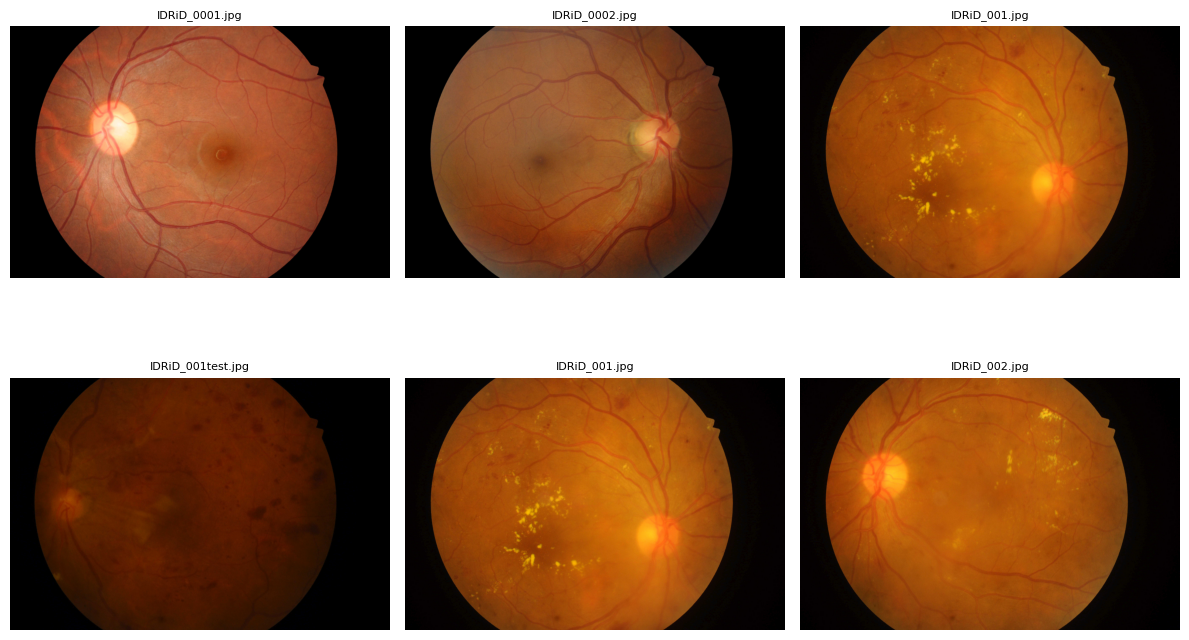

In [10]:

# CELL 09 — IMAGE QUALITY PREVIEW

preview_paths = []

for item in sorted(
    image_dirs, key=lambda x: x["images"], reverse=True
):
    folder = Path(item["directory"])

    candidates = sorted(
        p for p in folder.iterdir()
        if p.is_file() and p.suffix.lower() in IMAGE_EXTS
    )

    for path in candidates[:2]:
        preview_paths.append(path)

    if len(preview_paths) >= 6:
        break

if not preview_paths:
    print("No images found. Check the attached dataset paths.")
else:
    fig, axes = plt.subplots(
        2, 3, figsize=(12, 8)
    )
    axes = axes.ravel()

    for ax in axes:
        ax.axis("off")

    for ax, path in zip(axes, preview_paths):
        try:
            with Image.open(path) as img:
                ax.imshow(img.convert("RGB"))
            ax.set_title(path.name, fontsize=8)
            ax.axis("off")
        except Exception as e:
            ax.set_title(f"Failed: {path.name}")
            print(path, e)

    plt.tight_layout()
    plt.show()


In [11]:

# CELL 10 — SAVE DATASET AUDIT

audit = {
    "seed": SEED,
    "device": str(DEVICE),
    "torch_version": torch.__version__,
    "torchvision_version": torchvision.__version__,
    "datasets": file_inventory,
    "image_directories": image_dirs
}

audit_path = PROJECT_DIR / "metadata" / "initial_audit.json"

with open(audit_path, "w") as f:
    json.dump(audit, f, indent=2, default=str)

inventory_df.to_csv(
    PROJECT_DIR / "metadata" / "dataset_inventory.csv",
    index=False
)

print("Audit saved:", audit_path)
print("Dataset inventory saved.")
print("\nNEXT: Verify dataset names, image counts and label columns.")


Audit saved: /kaggle/working/DR_Project/metadata/initial_audit.json
Dataset inventory saved.

NEXT: Verify dataset names, image counts and label columns.


In [12]:
# CELL 11 — IDENTIFY PRIMARY DATASET FOLDERS

grading_roots = [
    p for p in dataset_roots
    if "indian-diabetic-retinopathy-image-dataset-idrid" in str(p).lower()
    or "diabetic-retinopathy-image-dataset" in str(p).lower()
]

print("Potential IDRiD dataset roots:")
for root in grading_roots:
    print(root)

print("\nImage folders containing IDRiD grading images:")
for item in image_dirs:
    path = item["directory"]
    if "idrid" in path.lower() and (
        "disease_grading" in path.lower()
        or "training set" in path.lower()
        or "testing set" in path.lower()
    ):
        print(item["images"], path)

Potential IDRiD dataset roots:

Image folders containing IDRiD grading images:


In [13]:
# CELL 12 — OFFICIAL GRADING LABEL FILES

def find_one_file(keyword):
    matches = [
        p for p in table_files
        if keyword.lower() in p.name.lower()
    ]
    if len(matches) != 1:
        print(f"{keyword}: found {len(matches)} matching files")
        for p in matches:
            print(" ", p)
        return None
    return matches[0]

train_label_path = find_one_file(
    "IDRiD_Disease Grading_Training Labels"
)
test_label_path = find_one_file(
    "IDRiD_Disease Grading_Testing Labels"
)

assert train_label_path is not None, (
    "Training labels not uniquely identified. Inspect Cell 6."
)
assert test_label_path is not None, (
    "Testing labels not uniquely identified. Inspect Cell 6."
)

print("Training labels:", train_label_path)
print("Testing labels:", test_label_path)

Training labels: /kaggle/input/datasets/dankok/diabetic-retinopathy-image-dataset/Disease_Grading/Groundtruths/IDRiD_Disease Grading_Training Labels.csv
Testing labels: /kaggle/input/datasets/dankok/diabetic-retinopathy-image-dataset/Disease_Grading/Groundtruths/IDRiD_Disease Grading_Testing Labels.csv


In [14]:
# CELL 13 — STANDARDIZE LABEL TABLES

train_labels = pd.read_csv(train_label_path)
test_labels = pd.read_csv(test_label_path)

def standardize_labels(df):
    df = df.copy()
    df.columns = df.columns.str.strip()

    id_col = next(
        (c for c in df.columns
         if c.lower() in ["image name", "id_code", "image id"]),
        None
    )
    grade_col = next(
        (c for c in df.columns
         if "retinopathy grade" in c.lower()
         or c.lower() == "diagnosis"),
        None
    )

    if id_col is None or grade_col is None:
        raise ValueError(
            f"Could not identify image ID and grade columns: "
            f"{df.columns.tolist()}"
        )

    out = df[[id_col, grade_col]].copy()
    out.columns = ["image_id", "label"]

    out["image_id"] = (
        out["image_id"].astype(str).str.strip()
        .str.replace(r"\.(jpg|jpeg|png|tif|tiff)$", "",
                     regex=True, case=False)
    )
    out["label"] = pd.to_numeric(out["label"], errors="coerce")

    out = out.dropna(subset=["image_id", "label"])
    out["label"] = out["label"].astype(int)

    if not out["label"].isin(range(5)).all():
        raise ValueError("Unexpected DR labels; expected grades 0–4.")

    if out["image_id"].duplicated().any():
        raise ValueError("Duplicate image IDs in the label table.")

    return out.reset_index(drop=True)

train_labels = standardize_labels(train_labels)
test_labels = standardize_labels(test_labels)

print("Official training records:", len(train_labels))
print("Official testing records:", len(test_labels))
print("\nTraining grade distribution:")
print(train_labels["label"].value_counts().sort_index())
print("\nTesting grade distribution:")
print(test_labels["label"].value_counts().sort_index())

Official training records: 413
Official testing records: 103

Training grade distribution:
label
0    134
1     20
2    136
3     74
4     49
Name: count, dtype: int64

Testing grade distribution:
label
0    34
1     5
2    32
3    19
4    13
Name: count, dtype: int64


In [15]:
# CELL 14 — MATCH LABEL IDS TO IMAGE FILES

all_image_paths = []

for root in dataset_roots:
    for current, _, files in os.walk(root):
        for filename in files:
            path = Path(current) / filename

            if path.suffix.lower() in IMAGE_EXTS:
                all_image_paths.append(path)

def normalized_stem(path):
    return path.stem.strip().lower()

image_lookup = {}

for path in all_image_paths:
    key = normalized_stem(path)
    image_lookup.setdefault(key, []).append(path)

print("Unique filename keys:", len(image_lookup))
print("Image files scanned:", len(all_image_paths))

Unique filename keys: 2176
Image files scanned: 3479


In [16]:
# CELL 15 — RESOLVE IMAGE PATHS

def resolve_image(image_id, split):
    key = image_id.lower()
    candidates = image_lookup.get(key, [])

    if not candidates:
        return None

    def score(path):
        text = str(path).lower()
        s = 0

        if "disease_grading" in text:
            s += 10
        if split == "train" and "training set" in text:
            s += 20
        if split == "test" and "testing set" in text:
            s += 20

        if "segmentation" in text or "localization" in text:
            s -= 50
        if "mask" in path.stem.lower():
            s -= 50

        return s

    ranked = sorted(candidates, key=score, reverse=True)
    best_score = score(ranked[0])
    best = [p for p in ranked if score(p) == best_score]

    if len(best) != 1 or best_score < 10:
        return None

    return str(best[0])

train_labels["image_path"] = train_labels["image_id"].apply(
    lambda x: resolve_image(x, "train")
)
test_labels["image_path"] = test_labels["image_id"].apply(
    lambda x: resolve_image(x, "test")
)

print("Unmatched training IDs:",
      train_labels["image_path"].isna().sum())
print("Unmatched test IDs:",
      test_labels["image_path"].isna().sum())

display(train_labels.head())
display(test_labels.head())

if train_labels["image_path"].isna().any():
    print("Inspect unmatched training IDs before proceeding.")
if test_labels["image_path"].isna().any():
    print("Inspect unmatched test IDs before proceeding.")

Unmatched training IDs: 0
Unmatched test IDs: 0


,image_id,label,image_path
0,IDRiD_001,3,/kaggle/input/datasets/dankok/diabetic-retinop...
1,IDRiD_002,3,/kaggle/input/datasets/dankok/diabetic-retinop...
2,IDRiD_003,2,/kaggle/input/datasets/dankok/diabetic-retinop...
3,IDRiD_004,3,/kaggle/input/datasets/dankok/diabetic-retinop...
4,IDRiD_005,4,/kaggle/input/datasets/dankok/diabetic-retinop...


,image_id,label,image_path
0,IDRiD_001,4,/kaggle/input/datasets/dankok/diabetic-retinop...
1,IDRiD_002,4,/kaggle/input/datasets/dankok/diabetic-retinop...
2,IDRiD_003,4,/kaggle/input/datasets/dankok/diabetic-retinop...
3,IDRiD_004,4,/kaggle/input/datasets/dankok/diabetic-retinop...
4,IDRiD_005,4,/kaggle/input/datasets/dankok/diabetic-retinop...


In [17]:
# CELL 16 — IMAGE VALIDATION AND HASHING

def image_sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

def inspect_image(path):
    try:
        with Image.open(path) as img:
            img.verify()
        with Image.open(path) as img:
            width, height = img.size
        return True, width, height
    except Exception:
        return False, None, None

for df in [train_labels, test_labels]:
    df["readable"] = False
    df["width"] = np.nan
    df["height"] = np.nan
    df["file_hash"] = None

    for idx, row in df.iterrows():
        path = row["image_path"]
        if not isinstance(path, str):
            continue

        ok, w, h = inspect_image(path)
        df.at[idx, "readable"] = ok
        df.at[idx, "width"] = w
        df.at[idx, "height"] = h

        if ok:
            df.at[idx, "file_hash"] = image_sha256(path)

print("Unreadable training images:",
      int((~train_labels["readable"]).sum()))
print("Unreadable test images:",
      int((~test_labels["readable"]).sum()))

print("Duplicate training hashes:",
      int(train_labels["file_hash"].duplicated().sum()))
print("Duplicate test hashes:",
      int(test_labels["file_hash"].duplicated().sum()))

Unreadable training images: 0
Unreadable test images: 0
Duplicate training hashes: 5
Duplicate test hashes: 0


In [18]:
# CELL 17 — CROSS-SPLIT DUPLICATE AUDIT

train_hashes = set(train_labels["file_hash"].dropna())
test_hashes = set(test_labels["file_hash"].dropna())

cross_split_hashes = train_hashes & test_hashes

print("Exact hashes shared by train and test:",
      len(cross_split_hashes))

if cross_split_hashes:
    print("WARNING: Investigate shared images before evaluation.")
else:
    print("PASS: No exact file-hash overlap.")

# Check IDs as an additional safeguard
id_overlap = set(train_labels["image_id"]) & set(test_labels["image_id"])
print("Image ID overlap:", len(id_overlap))

Exact hashes shared by train and test: 1
Image ID overlap: 103


In [19]:
# CELL 18 — CLEAN PRIMARY DATA TABLES

train_clean = train_labels.loc[
    train_labels["readable"] & train_labels["image_path"].notna()
].copy()

test_clean = test_labels.loc[
    test_labels["readable"] & test_labels["image_path"].notna()
].copy()

# Collapse exact duplicates only within each partition.
# Keep the first record and flag the removal count.
train_before = len(train_clean)
test_before = len(test_clean)

train_clean = train_clean.drop_duplicates(
    subset=["file_hash"], keep="first"
).reset_index(drop=True)

test_clean = test_clean.drop_duplicates(
    subset=["file_hash"], keep="first"
).reset_index(drop=True)

print(f"Training: {train_before} -> {len(train_clean)}")
print(f"Testing:  {test_before} -> {len(test_clean)}")

print("\nTraining class counts:")
print(train_clean["label"].value_counts().sort_index())

print("\nTest class counts:")
print(test_clean["label"].value_counts().sort_index())

if len(train_clean) == 0 or len(test_clean) == 0:
    raise RuntimeError(
        "A usable split is empty. Check image matching and validation."
    )

Training: 413 -> 408
Testing:  103 -> 103

Training class counts:
label
0    134
1     19
2    133
3     73
4     49
Name: count, dtype: int64

Test class counts:
label
0    34
1     5
2    32
3    19
4    13
Name: count, dtype: int64


In [20]:
# CELL 19 — TRAIN / VALIDATION SPLIT

from sklearn.model_selection import train_test_split

class_counts = train_clean["label"].value_counts()
can_stratify = (
    train_clean["label"].nunique() > 1
    and class_counts.min() >= 2
)

train_df, val_df = train_test_split(
    train_clean,
    test_size=0.20,
    random_state=SEED,
    stratify=train_clean["label"] if can_stratify else None
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_clean.reset_index(drop=True)

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Official test:", len(test_df))

print("\nTrain distribution:")
print(train_df["label"].value_counts().sort_index())

print("\nValidation distribution:")
print(val_df["label"].value_counts().sort_index())

Train: 326
Validation: 82
Official test: 103

Train distribution:
label
0    107
1     15
2    106
3     59
4     39
Name: count, dtype: int64

Validation distribution:
label
0    27
1     4
2    27
3    14
4    10
Name: count, dtype: int64


In [21]:
# CELL 20 — FINAL SPLIT AUDIT

def check_overlap(a, b, column):
    return set(a[column].dropna()) & set(b[column].dropna())

for left_name, left in [("train", train_df), ("validation", val_df)]:
    for right_name, right in [
        ("validation", val_df),
        ("test", test_df)
    ]:
        if left_name == right_name:
            continue

        id_overlap = check_overlap(left, right, "image_id")
        hash_overlap = check_overlap(left, right, "file_hash")

        print(
            f"{left_name} vs {right_name}: "
            f"ID overlap={len(id_overlap)}, "
            f"hash overlap={len(hash_overlap)}"
        )

if cross_split_hashes:
    print(
        "\nWARNING: Official train/test duplicates were detected. "
        "Do not report the test set as fully independent until reviewed."
    )

for name, df in [
    ("train", train_df),
    ("validation", val_df),
    ("test", test_df)
]:
    df.to_csv(
        PROJECT_DIR / "metadata" / f"{name}_split.csv",
        index=False
    )

print("\nSplit metadata saved to:", PROJECT_DIR / "metadata")

train vs validation: ID overlap=0, hash overlap=0
train vs test: ID overlap=82, hash overlap=1
validation vs test: ID overlap=21, hash overlap=0


Split metadata saved to: /kaggle/working/DR_Project/metadata


In [22]:
# CELL 21 — INVESTIGATE OFFICIAL SPLIT OVERLAP

print("TRAIN LABELS — sample paths")
display(train_labels[["image_id", "image_path"]].head(10))

print("\nTEST LABELS — sample paths")
display(test_labels[["image_id", "image_path"]].head(10))

print("\nTraining directories:")
print(train_labels["image_path"].dropna().apply(
    lambda p: str(Path(p).parent)
).value_counts().head(10))

print("\nTesting directories:")
print(test_labels["image_path"].dropna().apply(
    lambda p: str(Path(p).parent)
).value_counts().head(10))

print("\nMatching IDs across official splits:")
overlap_ids = sorted(
    set(train_labels["image_id"]) &
    set(test_labels["image_id"])
)

print("Number of overlapping IDs:", len(overlap_ids))
print("First 15 overlapping IDs:", overlap_ids[:15])

print("\nMatching image paths:")
path_map_train = dict(zip(
    train_labels["image_id"], train_labels["image_path"]
))
path_map_test = dict(zip(
    test_labels["image_id"], test_labels["image_path"]
))

for image_id in overlap_ids[:10]:
    print(
        image_id,
        "\n  train:", path_map_train.get(image_id),
        "\n  test: ", path_map_test.get(image_id)
    )

TRAIN LABELS — sample paths


,image_id,image_path
0,IDRiD_001,/kaggle/input/datasets/dankok/diabetic-retinop...
1,IDRiD_002,/kaggle/input/datasets/dankok/diabetic-retinop...
2,IDRiD_003,/kaggle/input/datasets/dankok/diabetic-retinop...
3,IDRiD_004,/kaggle/input/datasets/dankok/diabetic-retinop...
4,IDRiD_005,/kaggle/input/datasets/dankok/diabetic-retinop...
5,IDRiD_006,/kaggle/input/datasets/dankok/diabetic-retinop...
6,IDRiD_007,/kaggle/input/datasets/dankok/diabetic-retinop...
7,IDRiD_008,/kaggle/input/datasets/dankok/diabetic-retinop...
8,IDRiD_009,/kaggle/input/datasets/dankok/diabetic-retinop...
9,IDRiD_010,/kaggle/input/datasets/dankok/diabetic-retinop...



TEST LABELS — sample paths


,image_id,image_path
0,IDRiD_001,/kaggle/input/datasets/dankok/diabetic-retinop...
1,IDRiD_002,/kaggle/input/datasets/dankok/diabetic-retinop...
2,IDRiD_003,/kaggle/input/datasets/dankok/diabetic-retinop...
3,IDRiD_004,/kaggle/input/datasets/dankok/diabetic-retinop...
4,IDRiD_005,/kaggle/input/datasets/dankok/diabetic-retinop...
5,IDRiD_006,/kaggle/input/datasets/dankok/diabetic-retinop...
6,IDRiD_007,/kaggle/input/datasets/dankok/diabetic-retinop...
7,IDRiD_008,/kaggle/input/datasets/dankok/diabetic-retinop...
8,IDRiD_009,/kaggle/input/datasets/dankok/diabetic-retinop...
9,IDRiD_010,/kaggle/input/datasets/dankok/diabetic-retinop...



Training directories:
image_path
/kaggle/input/datasets/dankok/diabetic-retinopathy-image-dataset/Disease_Grading/Original_Images/Training Set    413
Name: count, dtype: int64

Testing directories:
image_path
/kaggle/input/datasets/dankok/diabetic-retinopathy-image-dataset/Disease_Grading/Original_Images/Testing Set    103
Name: count, dtype: int64

Matching IDs across official splits:
Number of overlapping IDs: 103
First 15 overlapping IDs: ['IDRiD_001', 'IDRiD_002', 'IDRiD_003', 'IDRiD_004', 'IDRiD_005', 'IDRiD_006', 'IDRiD_007', 'IDRiD_008', 'IDRiD_009', 'IDRiD_010', 'IDRiD_011', 'IDRiD_012', 'IDRiD_013', 'IDRiD_014', 'IDRiD_015']

Matching image paths:
IDRiD_001 
  train: /kaggle/input/datasets/dankok/diabetic-retinopathy-image-dataset/Disease_Grading/Original_Images/Training Set/IDRiD_001.jpg 
  test:  /kaggle/input/datasets/dankok/diabetic-retinopathy-image-dataset/Disease_Grading/Original_Images/Testing Set/IDRiD_001.jpg
IDRiD_002 
  train: /kaggle/input/datasets/dankok/diabeti

In [23]:
# CELL 22 — VERIFY CROSS-SPLIT DUPLICATE AND PATHS

train_path_by_id = dict(zip(
    train_labels["image_id"], train_labels["image_path"]
))
test_path_by_id = dict(zip(
    test_labels["image_id"], test_labels["image_path"]
))

# Verify that the paths are different for matching IDs.
same_path_ids = [
    image_id for image_id in
    set(train_path_by_id) & set(test_path_by_id)
    if os.path.abspath(train_path_by_id[image_id]) ==
       os.path.abspath(test_path_by_id[image_id])
]

print("IDs resolving to the exact same path:", len(same_path_ids))

# Locate any exact file-hash matches across the official splits.
train_hash_map = train_labels.dropna(
    subset=["file_hash"]
).groupby("file_hash")["image_id"].apply(list).to_dict()

test_hash_map = test_labels.dropna(
    subset=["file_hash"]
).groupby("file_hash")["image_id"].apply(list).to_dict()

shared_hashes = set(train_hash_map) & set(test_hash_map)

print("Shared exact file hashes:", len(shared_hashes))

for h in shared_hashes:
    print("\nHash:", h)
    print("Training IDs:", train_hash_map[h])
    print("Testing IDs:", test_hash_map[h])

    print("Training paths:")
    print(train_labels.loc[
        train_labels["file_hash"] == h, "image_path"
    ].tolist())

    print("Testing paths:")
    print(test_labels.loc[
        test_labels["file_hash"] == h, "image_path"
    ].tolist())

# Correct interpretation of the ID check
print("\nNOTE: Matching ID strings are not sufficient evidence of leakage.")
print("Compare file hashes and actual image content instead.")

IDs resolving to the exact same path: 0
Shared exact file hashes: 1

Hash: 505330878f4d4186a71b8001570100b82b6b05cb431e81e2c259d8c584314708
Training IDs: ['IDRiD_118']
Testing IDs: ['IDRiD_064']
Training paths:
['/kaggle/input/datasets/dankok/diabetic-retinopathy-image-dataset/Disease_Grading/Original_Images/Training Set/IDRiD_118.jpg']
Testing paths:
['/kaggle/input/datasets/dankok/diabetic-retinopathy-image-dataset/Disease_Grading/Original_Images/Testing Set/IDRiD_064.jpg']

NOTE: Matching ID strings are not sufficient evidence of leakage.
Compare file hashes and actual image content instead.


In [24]:
# CELL 23 — REMOVE EXACT TRAIN/TEST DUPLICATE SAFELY

shared_hash = (
    "505330878f4d4186a71b8001570100b82b6b05cb431e81e2c259d8c584314708"
)

print("TRAINING RECORD:")
display(train_labels.loc[train_labels["file_hash"] == shared_hash,
                         ["image_id", "label", "image_path", "file_hash"]])

print("TESTING RECORD:")
display(test_labels.loc[test_labels["file_hash"] == shared_hash,
                        ["image_id", "label", "image_path", "file_hash"]])

# Keep the testing copy; remove the identical image from training.
before = len(train_clean)
train_clean = train_clean.loc[
    train_clean["file_hash"] != shared_hash
].copy()

print(f"\nTraining rows before removal: {before}")
print(f"Training rows after removal:  {len(train_clean)}")
print("Testing rows retained:", len(test_labels))

# Confirm no exact file-content duplicates remain across these sets.
train_hashes = set(train_clean["file_hash"].dropna())
test_hashes = set(test_labels["file_hash"].dropna())
remaining_shared_hashes = train_hashes.intersection(test_hashes)

print("Remaining train/test shared hashes:", len(remaining_shared_hashes))
assert len(remaining_shared_hashes) == 0, (
    "Exact duplicate content still crosses the training/test boundary."
)

# Recreate the stratified train/validation split after cleaning.
from sklearn.model_selection import train_test_split

train_df, val_df = train_test_split(
    train_clean,
    test_size=0.20,
    random_state=42,
    stratify=train_clean["label"]
)

print("\nFinal split sizes:")
print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_labels))

print("\nTraining class counts:")
print(train_df["label"].value_counts().sort_index())

print("\nValidation class counts:")
print(val_df["label"].value_counts().sort_index())

print("\nTest class counts:")
print(test_labels["label"].value_counts().sort_index())

TRAINING RECORD:


,image_id,label,image_path,file_hash
117,IDRiD_118,0,/kaggle/input/datasets/dankok/diabetic-retinop...,505330878f4d4186a71b8001570100b82b6b05cb431e81...


TESTING RECORD:


,image_id,label,image_path,file_hash
63,IDRiD_064,3,/kaggle/input/datasets/dankok/diabetic-retinop...,505330878f4d4186a71b8001570100b82b6b05cb431e81...



Training rows before removal: 408
Training rows after removal:  407
Testing rows retained: 103
Remaining train/test shared hashes: 0

Final split sizes:
Train: 325
Validation: 82
Test: 103

Training class counts:
label
0    106
1     15
2    106
3     59
4     39
Name: count, dtype: int64

Validation class counts:
label
0    27
1     4
2    27
3    14
4    10
Name: count, dtype: int64

Test class counts:
label
0    34
1     5
2    32
3    19
4    13
Name: count, dtype: int64


In [25]:
# CELL 24 — SAVE FINAL, LEAKAGE-CHECKED SPLITS
from pathlib import Path

split_dir = PROJECT_DIR / "metadata"
split_dir.mkdir(parents=True, exist_ok=True)

train_df.to_csv(split_dir / "train_split.csv", index=False)
val_df.to_csv(split_dir / "validation_split.csv", index=False)
test_labels.to_csv(split_dir / "test_split.csv", index=False)

# Confirm image hashes do not cross the train/validation/test boundaries.
split_frames = {
    "train": train_df,
    "validation": val_df,
    "test": test_labels,
}

for name, frame in split_frames.items():
    assert frame["image_path"].notna().all(), f"{name}: missing image paths"
    assert frame["label"].between(0, 4).all(), f"{name}: invalid labels"
    assert frame["image_path"].map(os.path.isfile).all(), f"{name}: missing files"

for a, b in [("train", "validation"), ("train", "test"),
             ("validation", "test")]:
    hashes_a = set(split_frames[a]["file_hash"].dropna())
    hashes_b = set(split_frames[b]["file_hash"].dropna())
    overlap = hashes_a & hashes_b
    print(f"{a} vs {b}: {len(overlap)} shared hashes")
    assert not overlap, f"Exact duplicate images found between {a} and {b}"

print("\nSaved corrected split CSV files to:", split_dir)

train vs validation: 0 shared hashes
train vs test: 0 shared hashes
validation vs test: 0 shared hashes

Saved corrected split CSV files to: /kaggle/working/DR_Project/metadata


,train,validation,test
label,,,
No DR,106,27,34
Mild,15,4,5
Moderate,106,27,32
Severe,59,14,19
Proliferative DR,39,10,13


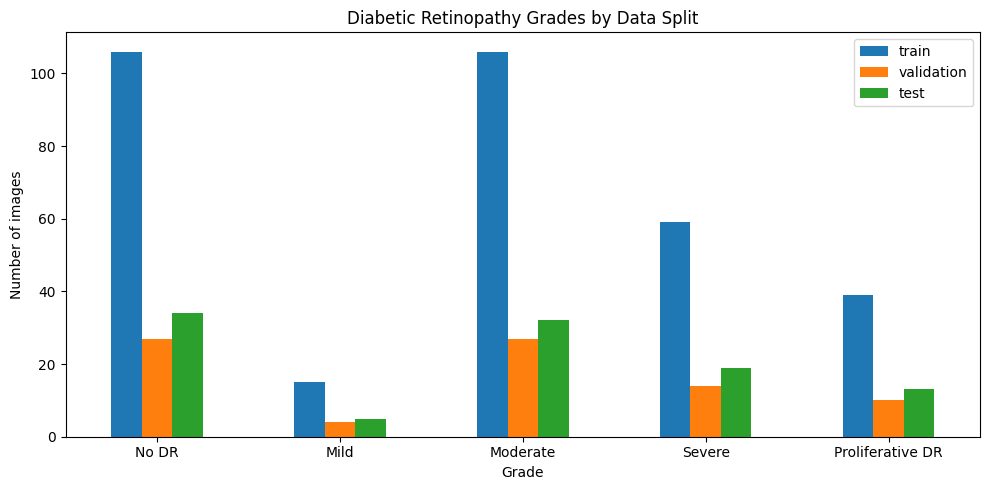

In [26]:
# CELL 25 — CLASS DISTRIBUTION
import matplotlib.pyplot as plt
import pandas as pd

class_names = {
    0: "No DR",
    1: "Mild",
    2: "Moderate",
    3: "Severe",
    4: "Proliferative DR",
}

distribution = pd.DataFrame({
    name: frame["label"].value_counts().reindex(range(5), fill_value=0)
    for name, frame in split_frames.items()
}).rename(index=class_names)

display(distribution)

ax = distribution.plot(kind="bar", figsize=(10, 5))
ax.set_title("Diabetic Retinopathy Grades by Data Split")
ax.set_xlabel("Grade")
ax.set_ylabel("Number of images")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

In [28]:

# CELL 26 — IMAGE DIMENSION AUDIT (FIXED)

from PIL import Image, ImageFile
import numpy as np
import pandas as pd

ImageFile.LOAD_TRUNCATED_IMAGES = False

# Combine all splits and keep one record per image path
all_split_df = pd.concat(
    [train_df, val_df, test_labels],
    ignore_index=True
)

all_split_df = all_split_df.drop_duplicates(
    subset=["image_path"]
).copy()

# Remove old audit columns to prevent duplicate column names
audit_columns = ["readable", "width", "height", "mode"]
all_split_df = all_split_df.drop(
    columns=audit_columns, errors="ignore"
)

def inspect_image(path):
    try:
        with Image.open(path) as img:
            img.verify()

        with Image.open(path) as img:
            width, height = img.size
            mode = img.mode

        return {
            "readable": True,
            "width": width,
            "height": height,
            "mode": mode
        }

    except Exception:
        return {
            "readable": False,
            "width": np.nan,
            "height": np.nan,
            "mode": None
        }

# Build a clean audit DataFrame
dimension_info = pd.DataFrame(
    [inspect_image(path) for path in all_split_df["image_path"]],
    index=all_split_df.index
)

all_split_df = pd.concat(
    [all_split_df, dimension_info], axis=1
)

# Report results
print("Unique images audited:", len(all_split_df))
print(
    "Unreadable images:",
    int((~all_split_df["readable"]).sum())
)

print("\nImage dimensions:")
display(
    all_split_df.loc[
        all_split_df["readable"], ["width", "height"]
    ].describe()
)

print("\nMost common dimensions:")
display(
    all_split_df.loc[all_split_df["readable"]]
    .groupby(["width", "height"])
    .size()
    .sort_values(ascending=False)
    .head(10)
    .rename("count")
    .reset_index()
)

# Save audit results
audit_path = PROJECT_DIR / "metadata" / "image_dimension_audit.csv"
all_split_df.to_csv(audit_path, index=False)

print("\nAudit saved to:", audit_path)


Unique images audited: 510
Unreadable images: 0

Image dimensions:


,width,height
count,510.0,510.0
mean,4288.0,2848.0
std,0.0,0.0
min,4288.0,2848.0
25%,4288.0,2848.0
50%,4288.0,2848.0
75%,4288.0,2848.0
max,4288.0,2848.0



Most common dimensions:


,width,height,count
0,4288,2848,510



Audit saved to: /kaggle/working/DR_Project/metadata/image_dimension_audit.csv


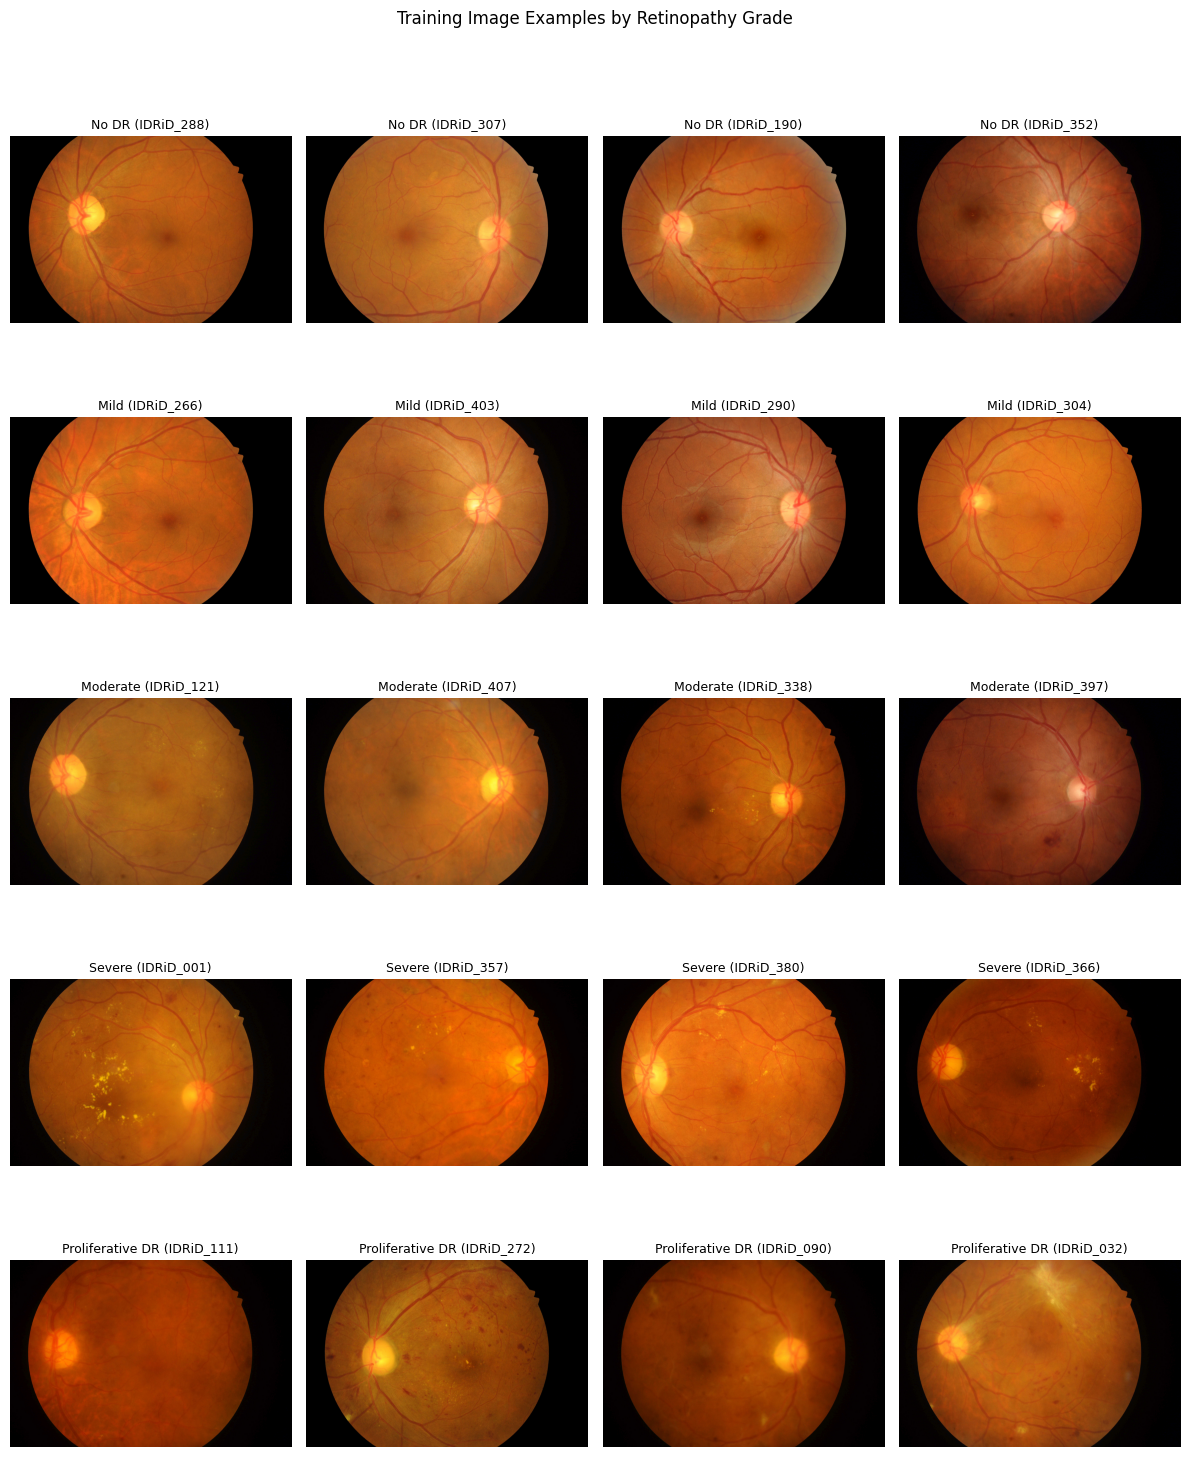

In [29]:
# CELL 27 — VISUAL SAMPLE ACROSS GRADES
import random
from PIL import Image
import matplotlib.pyplot as plt

random.seed(42)
fig, axes = plt.subplots(5, 4, figsize=(12, 15))

for grade in range(5):
    candidates = train_df.loc[train_df["label"] == grade]
    chosen = candidates.sample(
        n=min(4, len(candidates)), random_state=42
    )

    for j, (_, row) in enumerate(chosen.iterrows()):
        img = Image.open(row["image_path"]).convert("RGB")
        axes[grade, j].imshow(img)
        axes[grade, j].set_title(
            f'{class_names[grade]} ({row["image_id"]})',
            fontsize=9
        )
        axes[grade, j].axis("off")

    for j in range(len(chosen), 4):
        axes[grade, j].axis("off")

plt.suptitle("Training Image Examples by Retinopathy Grade", y=1.01)
plt.tight_layout()
plt.show()

In [30]:
# CELL 28 — BASIC BRIGHTNESS AND SHARPNESS AUDIT
import cv2

def image_quality_metrics(path):
    image = cv2.imread(str(path))
    if image is None:
        return pd.Series({
            "mean_brightness": np.nan,
            "sharpness": np.nan
        })

    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    return pd.Series({
        "mean_brightness": float(gray.mean()),
        "sharpness": float(cv2.Laplacian(gray, cv2.CV_64F).var())
    })

quality = all_split_df["image_path"].apply(image_quality_metrics)
all_split_df = pd.concat([all_split_df, quality], axis=1)

display(
    all_split_df[
        ["image_id", "label", "mean_brightness", "sharpness"]
    ].describe()
)

print("Darkest image examples:")
display(
    all_split_df.nsmallest(5, "mean_brightness")[
        ["image_id", "label", "mean_brightness", "image_path"]
    ]
)

print("Lowest-sharpness image examples:")
display(
    all_split_df.nsmallest(5, "sharpness")[
        ["image_id", "label", "sharpness", "image_path"]
    ]
)

,label,mean_brightness,sharpness
count,510.000000,510.000000,510.000000
mean,1.721569,66.562049,22.149112
std,1.396363,13.324553,5.900205
min,0.000000,24.747287,4.403281
25%,0.000000,58.531162,20.163879
50%,2.000000,67.633796,23.307362
75%,3.000000,76.016319,25.747172
max,4.000000,96.578974,33.658570


Darkest image examples:


,image_id,label,mean_brightness,image_path
55,IDRiD_274,0,24.747287,/kaggle/input/datasets/dankok/diabetic-retinop...
407,IDRiD_001,4,27.570555,/kaggle/input/datasets/dankok/diabetic-retinop...
228,IDRiD_030,4,27.639381,/kaggle/input/datasets/dankok/diabetic-retinop...
166,IDRiD_124,2,30.871655,/kaggle/input/datasets/dankok/diabetic-retinop...
504,IDRiD_098,0,32.086007,/kaggle/input/datasets/dankok/diabetic-retinop...


Lowest-sharpness image examples:


,image_id,label,sharpness,image_path
166,IDRiD_124,2,4.403281,/kaggle/input/datasets/dankok/diabetic-retinop...
478,IDRiD_072,2,5.705382,/kaggle/input/datasets/dankok/diabetic-retinop...
227,IDRiD_017,4,5.909355,/kaggle/input/datasets/dankok/diabetic-retinop...
407,IDRiD_001,4,5.954254,/kaggle/input/datasets/dankok/diabetic-retinop...
430,IDRiD_024,2,6.022515,/kaggle/input/datasets/dankok/diabetic-retinop...


In [31]:
# CELL 29 — COMPLETE IMAGE QUALITY AUDIT

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def calculate_quality_metrics(path):
    try:
        image = cv2.imread(str(path))
        if image is None:
            raise ValueError("Unable to read image")

        gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
        mask = gray > 10

        if mask.sum() == 0:
            raise ValueError("No visible retinal region detected")

        pixels = gray[mask]
        laplacian = cv2.Laplacian(gray, cv2.CV_64F)

        return {
            "mean_brightness": float(pixels.mean()),
            "contrast_std": float(pixels.std()),
            "sharpness": float(laplacian[mask].var()),
            "fov_ratio": float(mask.mean()),
            "quality_readable": True
        }

    except Exception:
        return {
            "mean_brightness": np.nan,
            "contrast_std": np.nan,
            "sharpness": np.nan,
            "fov_ratio": np.nan,
            "quality_readable": False
        }

# Remove previous versions of these columns before rerunning
quality_columns = [
    "mean_brightness", "contrast_std", "sharpness",
    "fov_ratio", "quality_readable"
]

quality_base = all_split_df.drop(
    columns=quality_columns, errors="ignore"
).copy()

quality_results = pd.DataFrame(
    [
        calculate_quality_metrics(path)
        for path in quality_base["image_path"]
    ],
    index=quality_base.index
)

all_split_df = pd.concat(
    [quality_base, quality_results], axis=1
)

print("Unique images:", len(all_split_df))
print(
    "Quality analysis failures:",
    int((~all_split_df["quality_readable"]).sum())
)

display(
    all_split_df[
        ["mean_brightness", "contrast_std",
         "sharpness", "fov_ratio"]
    ].describe().round(3)
)

quality_csv = PROJECT_DIR / "metadata" / "image_quality_audit.csv"
all_split_df.to_csv(quality_csv, index=False)
print("Saved:", quality_csv)

Unique images: 510
Quality analysis failures: 0


,mean_brightness,contrast_std,sharpness,fov_ratio
count,510.000,510.000,510.000,510.000
mean,95.392,20.404,31.671,0.692
std,18.942,4.599,8.540,0.002
min,35.847,8.245,6.266,0.690
25%,84.109,17.349,28.648,0.691
50%,96.955,20.177,33.306,0.691
75%,108.820,23.033,36.802,0.692
max,136.891,48.401,48.576,0.716


Saved: /kaggle/working/DR_Project/metadata/image_quality_audit.csv


Image quality by DR grade:


mean_brightness                  contrast_std                sharpness  \
                 mean   median     std         mean  median    std      mean   
label                                                                          
0              92.644   95.616  21.681       21.474  21.587  4.557    33.243   
1             102.864  105.543  13.083       20.679  20.074  2.626    33.927   
2              95.657   95.262  17.653       19.656  19.274  4.593    29.847   
3             100.775  101.681  16.320       19.734  19.358  4.317    32.203   
4              91.206   93.054  17.626       20.396  20.135  5.245    30.625   

                     fov_ratio                
       median    std      mean median    std  
label                                         
0      33.861  8.362     0.691  0.691  0.002  
1      35.248  7.572     0.691  0.691  0.001  
2      32.387  9.228     0.692  0.691  0.003  
3      33.771  6.933     0.692  0.692  0.002  
4      33.168  8.763     0.692  0.691  0.002

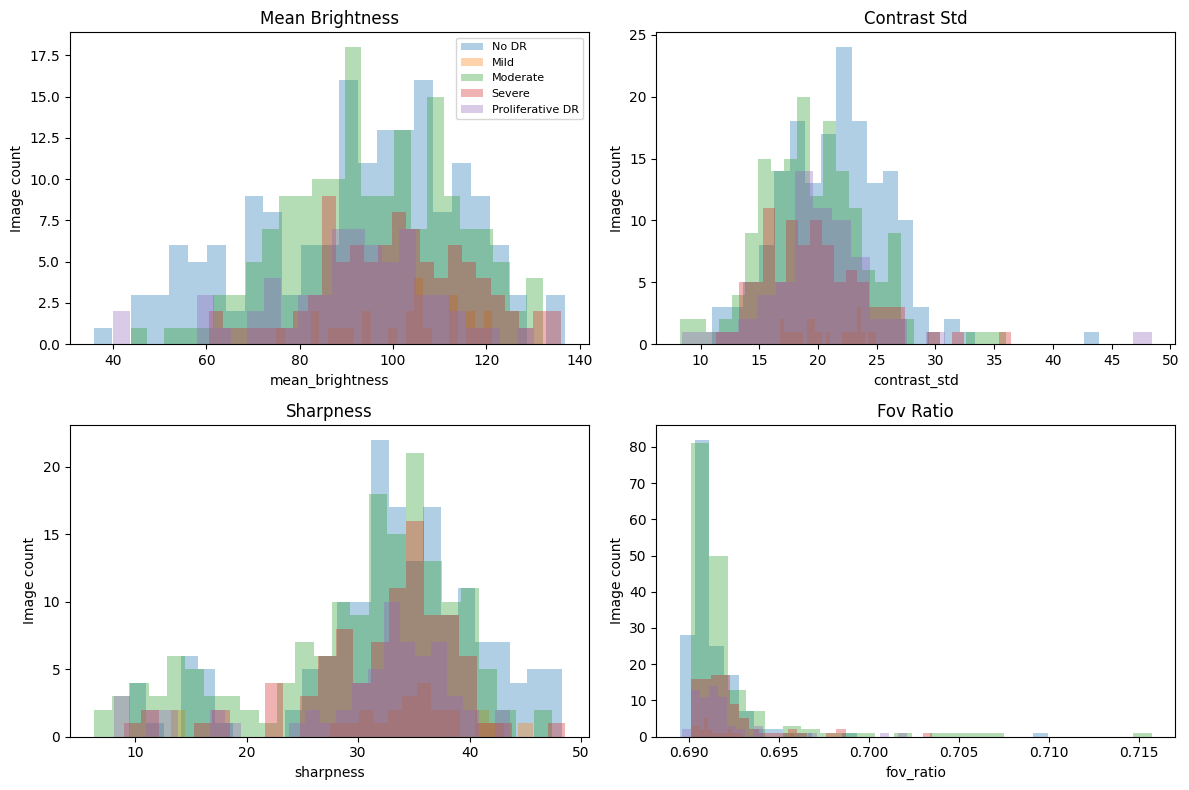

Saved: /kaggle/working/DR_Project/plots/quality_by_grade.png


In [32]:
# CELL 30 — QUALITY METRICS BY DR GRADE

quality_metrics = [
    "mean_brightness",
    "contrast_std",
    "sharpness",
    "fov_ratio"
]

quality_by_grade = (
    all_split_df.loc[all_split_df["quality_readable"]]
    .groupby("label")[quality_metrics]
    .agg(["mean", "median", "std"])
    .round(3)
)

print("Image quality by DR grade:")
display(quality_by_grade)

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, metric in zip(axes.flat, quality_metrics):
    for grade in range(5):
        values = all_split_df.loc[
            (all_split_df["label"] == grade)
            & all_split_df["quality_readable"],
            metric
        ].dropna()

        if len(values):
            ax.hist(
                values, bins=25, alpha=0.35,
                label=class_names[grade]
            )

    ax.set_title(metric.replace("_", " ").title())
    ax.set_xlabel(metric)
    ax.set_ylabel("Image count")

axes[0, 0].legend(fontsize=8)
plt.tight_layout()

plot_path = PROJECT_DIR / "plots" / "quality_by_grade.png"
plt.savefig(plot_path, dpi=150, bbox_inches="tight")
plt.show()

print("Saved:", plot_path)

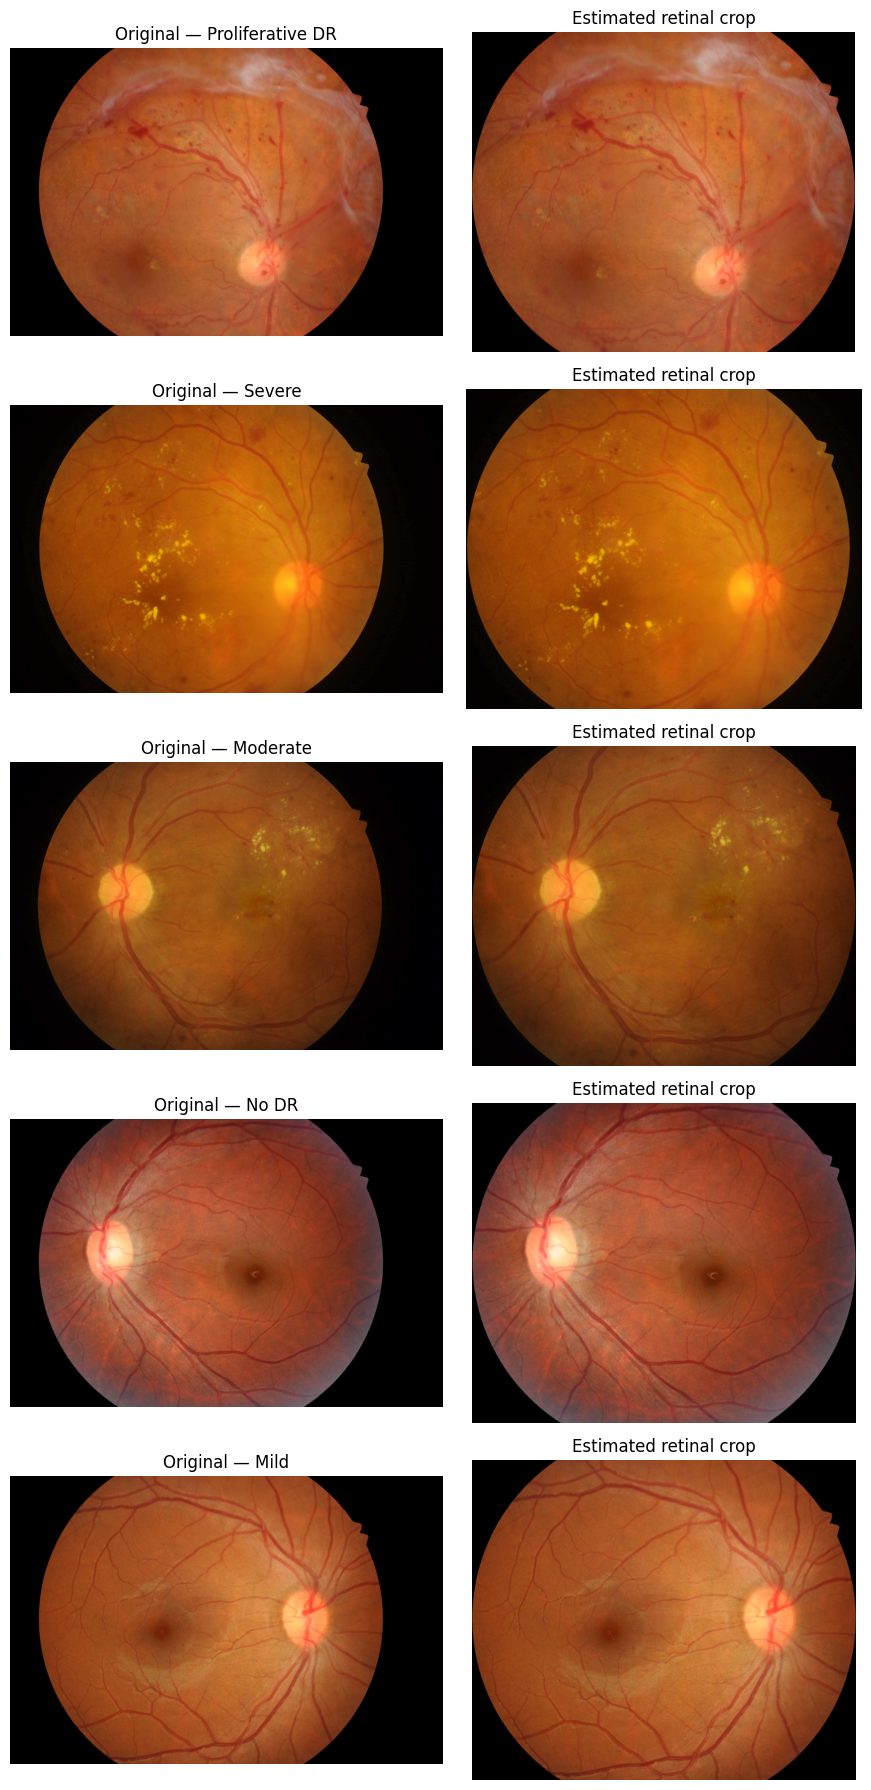

In [33]:
# CELL 31 — RETINAL FIELD-OF-VIEW VISUALIZATION

from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

def estimate_retinal_bbox(image, threshold=10):
    """Estimate a bounding box around non-dark pixels."""
    rgb = np.asarray(image.convert("RGB"))
    gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)

    mask = gray > threshold

    if mask.sum() == 0:
        return (0, 0, image.width, image.height)

    ys, xs = np.where(mask)

    x1, x2 = xs.min(), xs.max() + 1
    y1, y2 = ys.min(), ys.max() + 1

    return (x1, y1, x2, y2)

sample_rows = (
    train_df.groupby("label", group_keys=False)
    .head(1)
    .head(5)
)

fig, axes = plt.subplots(5, 2, figsize=(9, 18))

for row_idx, (_, row) in enumerate(sample_rows.iterrows()):
    with Image.open(row["image_path"]) as img:
        image = img.convert("RGB")

    bbox = estimate_retinal_bbox(image)
    cropped = image.crop(bbox)

    axes[row_idx, 0].imshow(image)
    axes[row_idx, 0].set_title(
        f"Original — {class_names[int(row['label'])]}"
    )
    axes[row_idx, 0].axis("off")

    axes[row_idx, 1].imshow(cropped)
    axes[row_idx, 1].set_title("Estimated retinal crop")
    axes[row_idx, 1].axis("off")

plt.tight_layout()
plt.show()

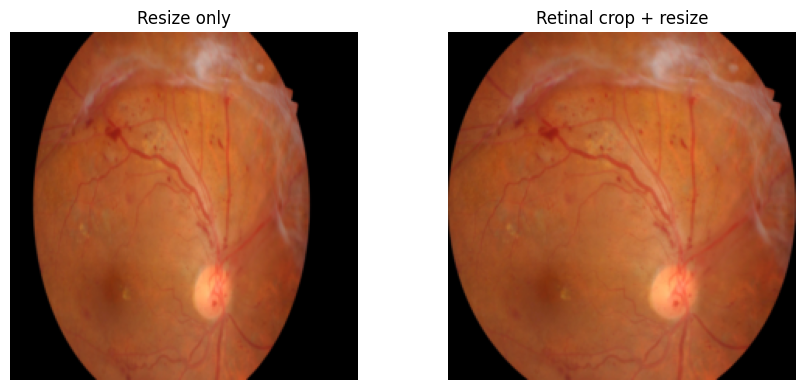

In [34]:
# CELL 32 — IMAGE PREPROCESSING FUNCTIONS

from PIL import Image, ImageOps

IMAGE_SIZE = 224

def preprocess_image(
    image_path,
    image_size=IMAGE_SIZE,
    crop_retina=False
):
    """
    Load an image, optionally crop the approximate retinal field,
    and resize it to a consistent square input.
    """
    with Image.open(image_path) as img:
        image = ImageOps.exif_transpose(img).convert("RGB")

    if crop_retina:
        bbox = estimate_retinal_bbox(image, threshold=10)
        image = image.crop(bbox)

    image = image.resize(
        (image_size, image_size),
        Image.Resampling.BILINEAR
    )

    return image

# Preview both preprocessing approaches
sample_path = train_df.iloc[0]["image_path"]

fig, axes = plt.subplots(1, 2, figsize=(9, 4))

axes[0].imshow(
    preprocess_image(sample_path, crop_retina=False)
)
axes[0].set_title("Resize only")

axes[1].imshow(
    preprocess_image(sample_path, crop_retina=True)
)
axes[1].set_title("Retinal crop + resize")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

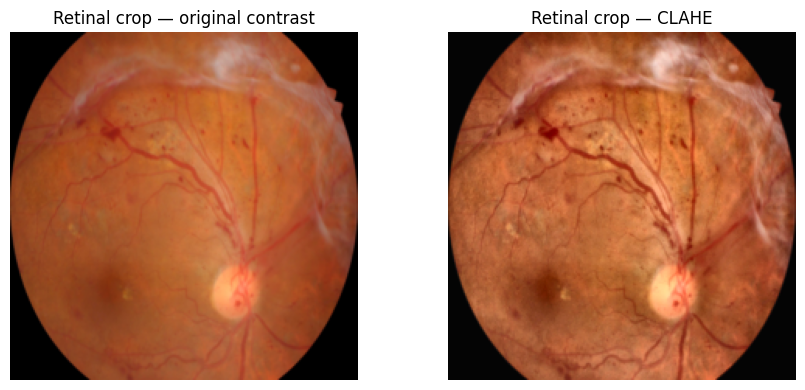

CLAHE comparison completed.
Use visual inspection before choosing CLAHE for all images.


In [35]:
# CELL 33 — CLAHE PREPROCESSING EXPERIMENT

import cv2
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

def apply_clahe(image, clip_limit=2.0, tile_grid_size=(8, 8)):
    """Apply CLAHE to the luminance channel while retaining color."""
    rgb = np.asarray(image.convert("RGB"))
    lab = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB)

    luminance, channel_a, channel_b = cv2.split(lab)

    clahe = cv2.createCLAHE(
        clipLimit=clip_limit,
        tileGridSize=tile_grid_size
    )

    enhanced_luminance = clahe.apply(luminance)

    enhanced_lab = cv2.merge(
        [enhanced_luminance, channel_a, channel_b]
    )

    enhanced_rgb = cv2.cvtColor(
        enhanced_lab, cv2.COLOR_LAB2RGB
    )

    return Image.fromarray(enhanced_rgb)

sample_path = train_df.iloc[0]["image_path"]
original = preprocess_image(
    sample_path, crop_retina=True
)
enhanced = apply_clahe(original)

fig, axes = plt.subplots(1, 2, figsize=(9, 4))

axes[0].imshow(original)
axes[0].set_title("Retinal crop — original contrast")

axes[1].imshow(enhanced)
axes[1].set_title("Retinal crop — CLAHE")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("CLAHE comparison completed.")
print("Use visual inspection before choosing CLAHE for all images.")

In [36]:
# CELL 34 — TRANSFORMS AND AUGMENTATION

import torch
from torchvision import transforms

# ImageNet normalization is appropriate when using ImageNet-pretrained
# EfficientNetB0, MobileNetV2 and ResNet50 weights.
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)

train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ColorJitter(
        brightness=0.10,
        contrast=0.10,
        saturation=0.05
    ),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

print("Image size:", IMAGE_SIZE)
print("Training transform:", train_transform)
print("Evaluation transform:", eval_transform)

Image size: 224
Training transform: Compose(
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    RandomHorizontalFlip(p=0.5)
    RandomRotation(degrees=[-10.0, 10.0], interpolation=nearest, expand=False, fill=0)
    ColorJitter(brightness=(0.9, 1.1), contrast=(0.9, 1.1), saturation=(0.95, 1.05), hue=None)
    ToTensor()
    Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225))
)
Evaluation transform: Compose(
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225))
)


In [37]:
# CELL 35 — PYTORCH DATASET

from torch.utils.data import Dataset
from PIL import Image, ImageOps
import pandas as pd
import os

class DRDataset(Dataset):
    def __init__(
        self,
        dataframe,
        transform=None,
        crop_retina=False
    ):
        self.dataframe = dataframe.reset_index(drop=True).copy()
        self.transform = transform
        self.crop_retina = crop_retina

        required_columns = {"image_path", "label"}
        missing = required_columns - set(self.dataframe.columns)

        if missing:
            raise ValueError(
                f"Missing required columns: {missing}"
            )

        if self.dataframe["image_path"].isna().any():
            raise ValueError("Missing image paths detected.")

        if not self.dataframe["label"].between(0, 4).all():
            raise ValueError("Labels must be integers from 0 to 4.")

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]
        image_path = str(row["image_path"])
        label = int(row["label"])

        with Image.open(image_path) as img:
            image = ImageOps.exif_transpose(img).convert("RGB")

        if self.crop_retina:
            bbox = estimate_retinal_bbox(image)
            image = image.crop(bbox)

        if self.transform is not None:
            image = self.transform(image)

        return image, torch.tensor(label, dtype=torch.long)


print("Training records:", len(train_df))
print("Validation records:", len(val_df))
print("Test records:", len(test_labels))
print("Dataset class defined successfully.")

Training records: 325
Validation records: 82
Test records: 103
Dataset class defined successfully.


In [38]:
# CELL 36 — DATASETS AND DATALOADERS

from torch.utils.data import DataLoader

BATCH_SIZE = 32
NUM_WORKERS = 2

train_dataset = DRDataset(
    train_df,
    transform=train_transform,
    crop_retina=False
)

val_dataset = DRDataset(
    val_df,
    transform=eval_transform,
    crop_retina=False
)

test_dataset = DRDataset(
    test_labels,
    transform=eval_transform,
    crop_retina=False
)

loader_generator = torch.Generator()
loader_generator.manual_seed(SEED)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available(),
    generator=loader_generator
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)

images, labels = next(iter(train_loader))

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))
print("Image tensor shape:", tuple(images.shape))
print("Label tensor shape:", tuple(labels.shape))
print("Labels in first batch:", labels.tolist())

assert images.shape[1:] == (3, IMAGE_SIZE, IMAGE_SIZE)
assert labels.min().item() >= 0
assert labels.max().item() <= 4

Training batches: 11
Validation batches: 3
Test batches: 4
Image tensor shape: (32, 3, 224, 224)
Label tensor shape: (32,)
Labels in first batch: [2, 0, 2, 4, 3, 0, 3, 3, 2, 2, 0, 0, 2, 0, 2, 2, 2, 1, 2, 1, 0, 4, 2, 2, 0, 0, 3, 0, 2, 3, 3, 2]


In [39]:
# CELL 37 — CLASS IMBALANCE HANDLING

import torch
import numpy as np
import pandas as pd

NUM_CLASSES = 5

train_class_counts = (
    train_df["label"]
    .value_counts()
    .reindex(range(NUM_CLASSES), fill_value=0)
    .sort_index()
)

print("Training class counts:")
display(
    train_class_counts.rename(index=class_names).to_frame("count")
)

if (train_class_counts == 0).any():
    missing_grades = train_class_counts[
        train_class_counts == 0
    ].index.tolist()

    raise ValueError(
        f"Training split has no examples for grades {missing_grades}. "
        "Review the split before training."
    )

# Inverse-frequency weights, normalized to mean 1
counts = train_class_counts.to_numpy(dtype=np.float64)

class_weights = len(train_df) / (
    NUM_CLASSES * counts
)

class_weights = class_weights / class_weights.mean()

class_weights = torch.tensor(
    class_weights,
    dtype=torch.float32,
    device=DEVICE
)

print("\nClass weights:")
for grade, weight in enumerate(class_weights.cpu().tolist()):
    print(f"{class_names[grade]}: {weight:.4f}")

print("\nWeights calculated using training labels only.")

Training class counts:


,count
label,
No DR,106
Mild,15
Moderate,106
Severe,59
Proliferative DR,39



Class weights:
No DR: 0.3682
Mild: 2.6016
Moderate: 0.3682
Severe: 0.6614
Proliferative DR: 1.0006

Weights calculated using training labels only.


In [40]:
# Cell 38 — Define ConvNeXt-Tiny, EfficientNetB0, and ResNet50

import torch
import torch.nn as nn
from torchvision import models

NUM_CLASSES = 5

def build_model(model_name, pretrained=True):
    """
    Build a five-class DR grading model.

    Supported models:
        - convnext_tiny
        - efficientnet_b0
        - resnet50
    """

    if model_name == "convnext_tiny":
        weights = (
            models.ConvNeXt_Tiny_Weights.DEFAULT
            if pretrained else None
        )

        model = models.convnext_tiny(weights=weights)
        in_features = model.classifier[2].in_features
        model.classifier[2] = nn.Linear(in_features, NUM_CLASSES)

    elif model_name == "efficientnet_b0":
        weights = (
            models.EfficientNet_B0_Weights.DEFAULT
            if pretrained else None
        )

        model = models.efficientnet_b0(weights=weights)
        in_features = model.classifier[1].in_features
        model.classifier[1] = nn.Linear(in_features, NUM_CLASSES)

    elif model_name == "resnet50":
        weights = (
            models.ResNet50_Weights.DEFAULT
            if pretrained else None
        )

        model = models.resnet50(weights=weights)
        in_features = model.fc.in_features
        model.fc = nn.Linear(in_features, NUM_CLASSES)

    else:
        raise ValueError(f"Unsupported model: {model_name}")

    return model


# The only three benchmark models in this project
MODEL_NAMES = [
    "convnext_tiny",
    "efficientnet_b0",
    "resnet50"
]

# Verify that every model returns five class logits
for name in MODEL_NAMES:
    model = build_model(name, pretrained=False).to(DEVICE)

    with torch.no_grad():
        dummy_input = torch.randn(2, 3, IMAGE_SIZE, IMAGE_SIZE).to(DEVICE)
        output = model(dummy_input)

    assert output.shape == (2, NUM_CLASSES), (
        f"{name} returned unexpected output shape: {output.shape}"
    )

    total_params = sum(p.numel() for p in model.parameters())
    print(
        f"{name}: output shape={tuple(output.shape)}, "
        f"parameters={total_params:,}"
    )

    del model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

print("All three benchmark models passed the output-shape check.")

convnext_tiny: output shape=(2, 5), parameters=27,823,973
efficientnet_b0: output shape=(2, 5), parameters=4,013,953
resnet50: output shape=(2, 5), parameters=23,518,277
All three benchmark models passed the output-shape check.


In [41]:
# Cell 39 — Training configuration

import time
import copy
import json
from contextlib import nullcontext
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    recall_score,
    cohen_kappa_score
)

BATCH_SIZE = 32
EPOCHS = 10
PATIENCE = 3

LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-4

USE_AMP = torch.cuda.is_available()  # Mixed precision on GPU

RESULTS_DIR = PROJECT_DIR / "results"
CHECKPOINT_DIR = PROJECT_DIR / "checkpoints"

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

print("Device:", DEVICE)
print("Models:", MODEL_NAMES)
print("Epochs:", EPOCHS)
print("Batch size:", BATCH_SIZE)
print("Mixed precision enabled:", USE_AMP)

Device: cuda
Models: ['convnext_tiny', 'efficientnet_b0', 'resnet50']
Epochs: 10
Batch size: 32
Mixed precision enabled: True


In [42]:
# Cell 40 — Evaluation metrics

def calculate_metrics(y_true, y_pred):
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(
            y_true, y_pred,
            average="macro",
            zero_division=0
        ),
        "macro_recall": recall_score(
            y_true, y_pred,
            average="macro",
            zero_division=0
        ),
        "qwk": cohen_kappa_score(
            y_true, y_pred,
            weights="quadratic"
        )
    }


def evaluate_model(model, data_loader, criterion):
    """Evaluate a model without updating its weights."""

    model.eval()

    total_loss = 0.0
    total_samples = 0
    all_targets = []
    all_predictions = []

    with torch.no_grad():
        for images, labels in data_loader:
            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)

            with (
                torch.autocast(device_type="cuda", enabled=USE_AMP)
                if DEVICE.type == "cuda"
                else nullcontext()
            ):
                logits = model(images)
                loss = criterion(logits, labels)

            batch_size = labels.size(0)
            total_loss += loss.item() * batch_size
            total_samples += batch_size

            predictions = logits.argmax(dim=1)

            all_targets.extend(labels.cpu().numpy())
            all_predictions.extend(predictions.cpu().numpy())

    metrics = calculate_metrics(all_targets, all_predictions)
    metrics["loss"] = total_loss / max(total_samples, 1)

    return metrics, np.asarray(all_targets), np.asarray(all_predictions)


print("Evaluation function ready.")

Evaluation function ready.


In [48]:
# Cell 41 — Train ConvNeXt-Tiny only

MODEL_NAME = "convnext_tiny"

model_convnext = build_model(
    MODEL_NAME,
    pretrained=True
).to(DEVICE)

criterion_convnext = nn.CrossEntropyLoss(
    weight=class_weights
)

optimizer_convnext = torch.optim.AdamW(
    model_convnext.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

scheduler_convnext = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_convnext,
    mode="min",
    factor=0.5,
    patience=1
)

scaler_convnext = torch.amp.GradScaler(
    "cuda",
    enabled=USE_AMP
)

best_qwk_convnext = -float("inf")
best_epoch_convnext = 0
wait_convnext = 0
history_convnext = []

checkpoint_convnext = (
    CHECKPOINT_DIR / "convnext_tiny_best.pth"
)

for epoch in range(1, EPOCHS + 1):
    model_convnext.train()
    total_loss = 0.0
    total_samples = 0

    for images, labels in train_loader:
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        optimizer_convnext.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type="cuda",
            enabled=USE_AMP
        ) if DEVICE.type == "cuda" else nullcontext():
            logits = model_convnext(images)
            loss = criterion_convnext(logits, labels)

        scaler_convnext.scale(loss).backward()
        scaler_convnext.step(optimizer_convnext)
        scaler_convnext.update()

        total_loss += loss.item() * labels.size(0)
        total_samples += labels.size(0)

    train_loss = total_loss / max(total_samples, 1)

    val_metrics, _, _ = evaluate_model(
        model_convnext,
        val_loader,
        criterion_convnext
    )

    scheduler_convnext.step(val_metrics["loss"])

    history_convnext.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "val_loss": val_metrics["loss"],
        "val_accuracy": val_metrics["accuracy"],
        "val_macro_f1": val_metrics["macro_f1"],
        "val_qwk": val_metrics["qwk"]
    })

    print(
        f"ConvNeXt-Tiny | Epoch {epoch}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_metrics['loss']:.4f} | "
        f"Val F1: {val_metrics['macro_f1']:.4f} | "
        f"Val QWK: {val_metrics['qwk']:.4f}"
    )

    if (
        np.isfinite(val_metrics["qwk"])
        and val_metrics["qwk"] > best_qwk_convnext
    ):
        best_qwk_convnext = val_metrics["qwk"]
        best_epoch_convnext = epoch
        wait_convnext = 0

        torch.save({
            "model_name": MODEL_NAME,
            "epoch": epoch,
            "model_state_dict": model_convnext.state_dict(),
            "best_val_qwk": best_qwk_convnext,
            "num_classes": NUM_CLASSES
        }, checkpoint_convnext)

    else:
        wait_convnext += 1

    if wait_convnext >= PATIENCE:
        print("Early stopping ConvNeXt-Tiny.")
        break

pd.DataFrame(history_convnext).to_csv(
    RESULTS_DIR / "convnext_tiny_training_history.csv",
    index=False
)

print("Best ConvNeXt-Tiny validation QWK:", best_qwk_convnext)
print("Best epoch:", best_epoch_convnext)
print("Checkpoint saved:", checkpoint_convnext)

ConvNeXt-Tiny | Epoch 1/10 | Train Loss: 1.5123 | Val Loss: 1.2142 | Val F1: 0.5061 | Val QWK: 0.7593
ConvNeXt-Tiny | Epoch 2/10 | Train Loss: 1.1860 | Val Loss: 1.1625 | Val F1: 0.4283 | Val QWK: 0.7940
ConvNeXt-Tiny | Epoch 3/10 | Train Loss: 0.9876 | Val Loss: 1.0837 | Val F1: 0.4858 | Val QWK: 0.7750
ConvNeXt-Tiny | Epoch 4/10 | Train Loss: 0.8428 | Val Loss: 1.1666 | Val F1: 0.4432 | Val QWK: 0.7651
ConvNeXt-Tiny | Epoch 5/10 | Train Loss: 0.8208 | Val Loss: 1.1390 | Val F1: 0.4781 | Val QWK: 0.8138
ConvNeXt-Tiny | Epoch 6/10 | Train Loss: 0.6105 | Val Loss: 0.9695 | Val F1: 0.5529 | Val QWK: 0.8416
ConvNeXt-Tiny | Epoch 7/10 | Train Loss: 0.5156 | Val Loss: 1.0971 | Val F1: 0.5745 | Val QWK: 0.8371
ConvNeXt-Tiny | Epoch 8/10 | Train Loss: 0.4490 | Val Loss: 0.9945 | Val F1: 0.5174 | Val QWK: 0.8303
ConvNeXt-Tiny | Epoch 9/10 | Train Loss: 0.3893 | Val Loss: 0.9844 | Val F1: 0.5964 | Val QWK: 0.8459
ConvNeXt-Tiny | Epoch 10/10 | Train Loss: 0.3420 | Val Loss: 0.9771 | Val F1: 0.51

In [49]:
# Cell 42 — Train EfficientNetB0 only

MODEL_NAME = "efficientnet_b0"

model_eff = build_model(
    MODEL_NAME,
    pretrained=True
).to(DEVICE)

criterion_eff = nn.CrossEntropyLoss(weight=class_weights)

optimizer_eff = torch.optim.AdamW(
    model_eff.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

scheduler_eff = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_eff,
    mode="min",
    factor=0.5,
    patience=1
)

scaler_eff = torch.amp.GradScaler(
    "cuda",
    enabled=USE_AMP
)

best_qwk_eff = -float("inf")
best_epoch_eff = 0
wait_eff = 0
history_eff = []

checkpoint_eff = CHECKPOINT_DIR / "efficientnet_b0_best.pth"

for epoch in range(1, EPOCHS + 1):
    model_eff.train()
    total_loss = 0.0
    total_samples = 0

    for images, labels in train_loader:
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        optimizer_eff.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type="cuda",
            enabled=USE_AMP
        ) if DEVICE.type == "cuda" else nullcontext():
            logits = model_eff(images)
            loss = criterion_eff(logits, labels)

        scaler_eff.scale(loss).backward()
        scaler_eff.step(optimizer_eff)
        scaler_eff.update()

        total_loss += loss.item() * labels.size(0)
        total_samples += labels.size(0)

    train_loss = total_loss / max(total_samples, 1)

    val_metrics, _, _ = evaluate_model(
        model_eff,
        val_loader,
        criterion_eff
    )

    scheduler_eff.step(val_metrics["loss"])

    history_eff.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "val_loss": val_metrics["loss"],
        "val_accuracy": val_metrics["accuracy"],
        "val_macro_f1": val_metrics["macro_f1"],
        "val_qwk": val_metrics["qwk"]
    })

    print(
        f"EfficientNetB0 | Epoch {epoch}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_metrics['loss']:.4f} | "
        f"Val F1: {val_metrics['macro_f1']:.4f} | "
        f"Val QWK: {val_metrics['qwk']:.4f}"
    )

    if (
        np.isfinite(val_metrics["qwk"])
        and val_metrics["qwk"] > best_qwk_eff
    ):
        best_qwk_eff = val_metrics["qwk"]
        best_epoch_eff = epoch
        wait_eff = 0

        torch.save({
            "model_name": MODEL_NAME,
            "epoch": epoch,
            "model_state_dict": model_eff.state_dict(),
            "best_val_qwk": best_qwk_eff,
            "num_classes": NUM_CLASSES
        }, checkpoint_eff)

    else:
        wait_eff += 1

    if wait_eff >= PATIENCE:
        print("Early stopping EfficientNetB0.")
        break

pd.DataFrame(history_eff).to_csv(
    RESULTS_DIR / "efficientnet_b0_training_history.csv",
    index=False
)

print("Best EfficientNetB0 validation QWK:", best_qwk_eff)
print("Best epoch:", best_epoch_eff)
print("Checkpoint saved:", checkpoint_eff)

EfficientNetB0 | Epoch 1/10 | Train Loss: 1.5950 | Val Loss: 1.5841 | Val F1: 0.1336 | Val QWK: 0.1498
EfficientNetB0 | Epoch 2/10 | Train Loss: 1.4654 | Val Loss: 1.4469 | Val F1: 0.3122 | Val QWK: 0.6439
EfficientNetB0 | Epoch 3/10 | Train Loss: 1.3449 | Val Loss: 1.2907 | Val F1: 0.4171 | Val QWK: 0.6757
EfficientNetB0 | Epoch 4/10 | Train Loss: 1.2233 | Val Loss: 1.1654 | Val F1: 0.4538 | Val QWK: 0.7275
EfficientNetB0 | Epoch 5/10 | Train Loss: 1.0911 | Val Loss: 1.0650 | Val F1: 0.4643 | Val QWK: 0.7686
EfficientNetB0 | Epoch 6/10 | Train Loss: 1.0022 | Val Loss: 0.9966 | Val F1: 0.5346 | Val QWK: 0.8004
EfficientNetB0 | Epoch 7/10 | Train Loss: 0.8539 | Val Loss: 0.9166 | Val F1: 0.5458 | Val QWK: 0.8102
EfficientNetB0 | Epoch 8/10 | Train Loss: 0.8028 | Val Loss: 0.8737 | Val F1: 0.5477 | Val QWK: 0.8164
EfficientNetB0 | Epoch 9/10 | Train Loss: 0.7224 | Val Loss: 0.8593 | Val F1: 0.5573 | Val QWK: 0.8129
EfficientNetB0 | Epoch 10/10 | Train Loss: 0.6484 | Val Loss: 0.9058 | Va

In [50]:
# Cell 43 — Train ResNet50 only

MODEL_NAME = "resnet50"

model_resnet = build_model(
    MODEL_NAME,
    pretrained=True
).to(DEVICE)

criterion_resnet = nn.CrossEntropyLoss(weight=class_weights)

optimizer_resnet = torch.optim.AdamW(
    model_resnet.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

scheduler_resnet = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_resnet,
    mode="min",
    factor=0.5,
    patience=1
)

scaler_resnet = torch.amp.GradScaler(
    "cuda",
    enabled=USE_AMP
)

best_qwk_resnet = -float("inf")
best_epoch_resnet = 0
wait_resnet = 0
history_resnet = []

checkpoint_resnet = CHECKPOINT_DIR / "resnet50_best.pth"

for epoch in range(1, EPOCHS + 1):
    model_resnet.train()
    total_loss = 0.0
    total_samples = 0

    for images, labels in train_loader:
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        optimizer_resnet.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type="cuda",
            enabled=USE_AMP
        ) if DEVICE.type == "cuda" else nullcontext():
            logits = model_resnet(images)
            loss = criterion_resnet(logits, labels)

        scaler_resnet.scale(loss).backward()
        scaler_resnet.step(optimizer_resnet)
        scaler_resnet.update()

        total_loss += loss.item() * labels.size(0)
        total_samples += labels.size(0)

    train_loss = total_loss / max(total_samples, 1)

    val_metrics, _, _ = evaluate_model(
        model_resnet,
        val_loader,
        criterion_resnet
    )

    scheduler_resnet.step(val_metrics["loss"])

    history_resnet.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "val_loss": val_metrics["loss"],
        "val_accuracy": val_metrics["accuracy"],
        "val_macro_f1": val_metrics["macro_f1"],
        "val_qwk": val_metrics["qwk"]
    })

    print(
        f"ResNet50 | Epoch {epoch}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_metrics['loss']:.4f} | "
        f"Val F1: {val_metrics['macro_f1']:.4f} | "
        f"Val QWK: {val_metrics['qwk']:.4f}"
    )

    if (
        np.isfinite(val_metrics["qwk"])
        and val_metrics["qwk"] > best_qwk_resnet
    ):
        best_qwk_resnet = val_metrics["qwk"]
        best_epoch_resnet = epoch
        wait_resnet = 0

        torch.save({
            "model_name": MODEL_NAME,
            "epoch": epoch,
            "model_state_dict": model_resnet.state_dict(),
            "best_val_qwk": best_qwk_resnet,
            "num_classes": NUM_CLASSES
        }, checkpoint_resnet)

    else:
        wait_resnet += 1

    if wait_resnet >= PATIENCE:
        print("Early stopping ResNet50.")
        break

pd.DataFrame(history_resnet).to_csv(
    RESULTS_DIR / "resnet50_training_history.csv",
    index=False
)

print("Best ResNet50 validation QWK:", best_qwk_resnet)
print("Best epoch:", best_epoch_resnet)
print("Checkpoint saved:", checkpoint_resnet)

ResNet50 | Epoch 1/10 | Train Loss: 1.5754 | Val Loss: 1.5392 | Val F1: 0.3060 | Val QWK: 0.4793
ResNet50 | Epoch 2/10 | Train Loss: 1.4230 | Val Loss: 1.3958 | Val F1: 0.4114 | Val QWK: 0.6158
ResNet50 | Epoch 3/10 | Train Loss: 1.2610 | Val Loss: 1.2162 | Val F1: 0.4200 | Val QWK: 0.7137
ResNet50 | Epoch 4/10 | Train Loss: 1.0378 | Val Loss: 1.0784 | Val F1: 0.4660 | Val QWK: 0.7338
ResNet50 | Epoch 5/10 | Train Loss: 0.8684 | Val Loss: 0.9980 | Val F1: 0.4761 | Val QWK: 0.7564
ResNet50 | Epoch 6/10 | Train Loss: 0.6927 | Val Loss: 1.1330 | Val F1: 0.5438 | Val QWK: 0.6943
ResNet50 | Epoch 7/10 | Train Loss: 0.5972 | Val Loss: 1.1302 | Val F1: 0.4875 | Val QWK: 0.6914
ResNet50 | Epoch 8/10 | Train Loss: 0.4942 | Val Loss: 1.0201 | Val F1: 0.5580 | Val QWK: 0.8155
ResNet50 | Epoch 9/10 | Train Loss: 0.3825 | Val Loss: 1.0189 | Val F1: 0.6086 | Val QWK: 0.8146
ResNet50 | Epoch 10/10 | Train Loss: 0.3279 | Val Loss: 1.0658 | Val F1: 0.5169 | Val QWK: 0.8014
Best ResNet50 validation QWK:

In [51]:
# Cell 44 — Release model and GPU memory

import gc

for variable_name in [
    "model_convnext", "criterion_convnext",
    "optimizer_convnext", "scheduler_convnext", "scaler_convnext",
    "model_eff", "criterion_eff",
    "optimizer_eff", "scheduler_eff", "scaler_eff",
    "model_resnet", "criterion_resnet",
    "optimizer_resnet", "scheduler_resnet", "scaler_resnet"
]:
    if variable_name in globals():
        del globals()[variable_name]

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

print("Unused model variables cleared where available.")

Unused model variables cleared where available.


In [52]:
# Cell 45 — Compare best validation results

history_files = {
    "ConvNeXt-Tiny": RESULTS_DIR / "convnext_tiny_training_history.csv",
    "EfficientNetB0": RESULTS_DIR / "efficientnet_b0_training_history.csv",
    "ResNet50": RESULTS_DIR / "resnet50_training_history.csv"
}

validation_records = []

for model_name, file_path in history_files.items():
    if not file_path.exists():
        print(f"Skipping {model_name}: training history not found.")
        continue

    history_df = pd.read_csv(file_path)
    best_row = history_df.loc[history_df["val_qwk"].idxmax()]

    validation_records.append({
        "model": model_name,
        "best_epoch": int(best_row["epoch"]),
        "val_accuracy": best_row["val_accuracy"],
        "val_macro_f1": best_row["val_macro_f1"],
        "val_qwk": best_row["val_qwk"]
    })

validation_comparison_df = pd.DataFrame(validation_records)

if not validation_comparison_df.empty:
    display(
        validation_comparison_df.sort_values(
            "val_qwk", ascending=False
        )
    )

    validation_comparison_df.to_csv(
        RESULTS_DIR / "validation_model_comparison.csv",
        index=False
    )

,model,best_epoch,val_accuracy,val_macro_f1,val_qwk
1,EfficientNetB0,10,0.682927,0.619454,0.853390
0,ConvNeXt-Tiny,9,0.682927,0.596437,0.845909
2,ResNet50,8,0.658537,0.558016,0.815517


In [53]:
# Cell 46 — Check class distribution and current checkpoint files

import pandas as pd
from pathlib import Path

print("Training class distribution:")
display(
    train_df["label"]
    .value_counts()
    .reindex(range(NUM_CLASSES), fill_value=0)
    .rename(index=class_names)
    .to_frame("count")
)

print("\nValidation class distribution:")
display(
    val_df["label"]
    .value_counts()
    .reindex(range(NUM_CLASSES), fill_value=0)
    .rename(index=class_names)
    .to_frame("count")
)

print("\nAvailable checkpoints:")
for path in sorted(CHECKPOINT_DIR.glob("*.pth")):
    print(f"{path.name}: {path.stat().st_size / (1024**2):.1f} MB")

Training class distribution:


,count
label,
No DR,106
Mild,15
Moderate,106
Severe,59
Proliferative DR,39



Validation class distribution:


,count
label,
No DR,27
Mild,4
Moderate,27
Severe,14
Proliferative DR,10



Available checkpoints:
convnext_tiny_best.pth: 106.2 MB
efficientnet_b0_best.pth: 15.6 MB
resnet50_best.pth: 90.0 MB


In [55]:
# Cell 47 — Corrected EfficientNetB0 Fine-Tuning

import copy
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from contextlib import nullcontext

# --------------------------------------------------
# 1. Configuration
# --------------------------------------------------
MODEL_NAME = "efficientnet_b0"
CHECKPOINT_PATH = CHECKPOINT_DIR / "efficientnet_b0_best.pth"
FINETUNED_PATH = CHECKPOINT_DIR / "efficientnet_b0_finetuned_best.pth"

FINE_TUNE_EPOCHS = 8
FINE_TUNE_PATIENCE = 3

# --------------------------------------------------
# 2. Load the existing best checkpoint
# --------------------------------------------------
if not CHECKPOINT_PATH.exists():
    raise FileNotFoundError(
        f"Checkpoint not found: {CHECKPOINT_PATH}. "
        "Run the original EfficientNetB0 training cell first."
    )

try:
    saved = torch.load(
        CHECKPOINT_PATH,
        map_location=DEVICE,
        weights_only=True,
    )
except (RuntimeError, EOFError, ValueError, Exception) as exc:
    # Only use this fallback for your own trusted training checkpoint.
    if (
        "Weights only load failed" not in str(exc)
        and "Unsupported global" not in str(exc)
    ):
        raise

    print("Retrying trusted checkpoint with weights_only=False...")
    saved = torch.load(
        CHECKPOINT_PATH,
        map_location=DEVICE,
        weights_only=False,
    )

if isinstance(saved, dict) and "model_state_dict" in saved:
    state_dict = saved["model_state_dict"]
elif isinstance(saved, dict) and "state_dict" in saved:
    state_dict = saved["state_dict"]
else:
    state_dict = saved

model_ft = build_model(
    MODEL_NAME,
    pretrained=False,
).to(DEVICE)

model_ft.load_state_dict(state_dict)
print("Loaded existing EfficientNetB0 checkpoint.")

# --------------------------------------------------
# 3. Freeze early features; fine-tune later features
# --------------------------------------------------
for param in model_ft.features.parameters():
    param.requires_grad = False

for param in model_ft.features[6:].parameters():
    param.requires_grad = True

for param in model_ft.classifier.parameters():
    param.requires_grad = True

# --------------------------------------------------
# 4. Loss, optimizer, scheduler, and AMP
# --------------------------------------------------
criterion_ft = nn.CrossEntropyLoss(
    weight=class_weights.to(DEVICE),
    label_smoothing=0.05,
)

optimizer_ft = torch.optim.AdamW(
    [
        {
            "params": [
                p for p in model_ft.features.parameters()
                if p.requires_grad
            ],
            "lr": 1e-5,
        },
        {
            "params": model_ft.classifier.parameters(),
            "lr": 5e-5,
        },
    ],
    weight_decay=1e-4,
)

scheduler_ft = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_ft,
    mode="max",
    factor=0.5,
    patience=1,
)

scaler_ft = torch.amp.GradScaler(
    "cuda",
    enabled=(DEVICE.type == "cuda"),
)

def get_amp_context():
    if DEVICE.type == "cuda":
        return torch.autocast("cuda", enabled=True)
    return nullcontext()

# --------------------------------------------------
# 5. Establish the baseline and best state
# --------------------------------------------------
baseline_metrics, _, _ = evaluate_model(
    model_ft, val_loader, criterion_ft
)

best_qwk_ft = baseline_metrics["qwk"]
best_state_ft = copy.deepcopy(model_ft.state_dict())
best_epoch_ft = 0
no_improve_ft = 0
history_ft = []

print("\nBaseline validation metrics:")
print(baseline_metrics)

# --------------------------------------------------
# 6. Fine-tuning loop
# --------------------------------------------------
for epoch in range(1, FINE_TUNE_EPOCHS + 1):
    model_ft.train()
    running_loss = 0.0
    total_samples = 0

    for images, labels in train_loader:
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        optimizer_ft.zero_grad(set_to_none=True)

        with get_amp_context():
            logits = model_ft(images)
            loss = criterion_ft(logits, labels)

        scaler_ft.scale(loss).backward()
        scaler_ft.unscale_(optimizer_ft)

        torch.nn.utils.clip_grad_norm_(
            [p for p in model_ft.parameters() if p.requires_grad],
            max_norm=1.0,
        )

        scaler_ft.step(optimizer_ft)
        scaler_ft.update()

        batch_size = labels.size(0)
        running_loss += loss.item() * batch_size
        total_samples += batch_size

    train_loss = running_loss / max(total_samples, 1)

    val_metrics, _, _ = evaluate_model(
        model_ft, val_loader, criterion_ft
    )

    scheduler_ft.step(val_metrics["qwk"])

    history_ft.append({
        "epoch": epoch,
        "train_loss": train_loss,
        **{f"val_{key}": value for key, value in val_metrics.items()},
    })

    print(
        f"Epoch {epoch}/{FINE_TUNE_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Accuracy: {val_metrics['accuracy']:.4f} | "
        f"Val Macro-F1: {val_metrics['macro_f1']:.4f} | "
        f"Val QWK: {val_metrics['qwk']:.4f}"
    )

    # Save the best model according to validation QWK.
    if val_metrics["qwk"] > best_qwk_ft:
        best_qwk_ft = val_metrics["qwk"]
        best_epoch_ft = epoch
        best_state_ft = copy.deepcopy(model_ft.state_dict())
        no_improve_ft = 0

        torch.save(best_state_ft, FINETUNED_PATH)
        print("  Best fine-tuned checkpoint saved.")
    else:
        no_improve_ft += 1

    if no_improve_ft >= FINE_TUNE_PATIENCE:
        print("Early stopping triggered.")
        break

# --------------------------------------------------
# 7. Restore and evaluate the best fine-tuned model
# --------------------------------------------------
model_ft.load_state_dict(best_state_ft)

history_df_ft = pd.DataFrame(history_ft)
history_df_ft.to_csv(
    RESULTS_DIR / "efficientnet_b0_finetune_history.csv",
    index=False,
)

best_metrics_ft, _, _ = evaluate_model(
    model_ft, val_loader, criterion_ft
)

print("\nFine-tuning complete.")
print("Best fine-tuning epoch:", best_epoch_ft)
print("Best validation QWK:", round(best_qwk_ft, 4))
print("Best validation metrics:", best_metrics_ft)
print("Checkpoint:", FINETUNED_PATH)

Retrying trusted checkpoint with weights_only=False...
Loaded existing EfficientNetB0 checkpoint.

Baseline validation metrics:
{'accuracy': 0.6829268292682927, 'macro_f1': 0.6194538515293232, 'macro_recall': 0.6351322751322751, 'qwk': np.float64(0.8533897686637962), 'loss': 1.0974784478908632}
Epoch 1/8 | Train Loss: 0.8095 | Val Accuracy: 0.6463 | Val Macro-F1: 0.6061 | Val QWK: 0.8174
Epoch 2/8 | Train Loss: 0.7884 | Val Accuracy: 0.6707 | Val Macro-F1: 0.6316 | Val QWK: 0.8305
Epoch 3/8 | Train Loss: 0.7902 | Val Accuracy: 0.7073 | Val Macro-F1: 0.6567 | Val QWK: 0.8458
Early stopping triggered.

Fine-tuning complete.
Best fine-tuning epoch: 0
Best validation QWK: 0.8534
Best validation metrics: {'accuracy': 0.6829268292682927, 'macro_f1': 0.6194538515293232, 'macro_recall': 0.6351322751322751, 'qwk': np.float64(0.8533897686637962), 'loss': 1.0974784478908632}
Checkpoint: /kaggle/working/DR_Project/checkpoints/efficientnet_b0_finetuned_best.pth


In [56]:
# Cell 48 — Evaluate the fine-tuned model on validation data

import numpy as np
import pandas as pd
import torch

val_metrics_ft, y_true_val, y_pred_val, = evaluate_model(
    model_ft, val_loader, criterion_ft
)

print("Fine-tuned EfficientNetB0 — Validation Results")
for metric, value in val_metrics_ft.items():
    print(f"{metric}: {value:.4f}")

original_metrics = {
    "accuracy": 0.682927,
    "macro_f1": 0.619454,
    "qwk": 0.853390,
}

comparison = pd.DataFrame([
    {"model": "Original EfficientNetB0", **original_metrics},
    {
        "model": "Fine-tuned EfficientNetB0",
        "accuracy": val_metrics_ft["accuracy"],
        "macro_f1": val_metrics_ft["macro_f1"],
        "qwk": val_metrics_ft["qwk"],
    },
])

display(comparison)
comparison.to_csv(
    RESULTS_DIR / "efficientnet_finetune_comparison.csv",
    index=False,
)

Fine-tuned EfficientNetB0 — Validation Results
accuracy: 0.6829
macro_f1: 0.6195
macro_recall: 0.6351
qwk: 0.8534
loss: 1.0975


,model,accuracy,macro_f1,qwk
0,Original EfficientNetB0,0.682927,0.619454,0.85339
1,Fine-tuned EfficientNetB0,0.682927,0.619454,0.85339


In [57]:
# Cell 49 — Horizontal-flip TTA

from contextlib import nullcontext
from sklearn.metrics import accuracy_score, f1_score, cohen_kappa_score

@torch.no_grad()
def predict_tta(model, loader):
    model.eval()
    targets, probabilities = [], []

    for images, labels in loader:
        images = images.to(DEVICE, non_blocking=True)

        context = (
            torch.autocast("cuda", enabled=True)
            if DEVICE.type == "cuda"
            else nullcontext()
        )

        with context:
            logits_original = model(images)
            logits_flipped = model(torch.flip(images, dims=[3]))

        probs = (
            torch.softmax(logits_original.float(), dim=1)
            + torch.softmax(logits_flipped.float(), dim=1)
        ) / 2

        targets.extend(labels.cpu().numpy())
        probabilities.append(probs.cpu().numpy())

    return np.asarray(targets), np.concatenate(probabilities, axis=0)


def metrics_from_probabilities(y_true, probs):
    predictions = probs.argmax(axis=1)
    return {
        "accuracy": accuracy_score(y_true, predictions),
        "macro_f1": f1_score(
            y_true, predictions, average="macro", zero_division=0
        ),
        "qwk": cohen_kappa_score(
            y_true, predictions, weights="quadratic"
        ),
    }


y_true_tta, probs_eff_tta = predict_tta(model_ft, val_loader)
tta_metrics = metrics_from_probabilities(y_true_tta, probs_eff_tta)

print("Fine-tuned EfficientNetB0 with TTA:")
for metric, value in tta_metrics.items():
    print(f"{metric}: {value:.4f}")

display(pd.DataFrame([
    {
        "method": "Fine-tuned EfficientNetB0",
        "accuracy": val_metrics_ft["accuracy"],
        "macro_f1": val_metrics_ft["macro_f1"],
        "qwk": val_metrics_ft["qwk"],
    },
    {"method": "Fine-tuned EfficientNetB0 + TTA", **tta_metrics},
]))

Fine-tuned EfficientNetB0 with TTA:
accuracy: 0.6585
macro_f1: 0.6101
qwk: 0.8311


,method,accuracy,macro_f1,qwk
0,Fine-tuned EfficientNetB0,0.682927,0.619454,0.853390
1,Fine-tuned EfficientNetB0 + TTA,0.658537,0.610130,0.831056


In [58]:
# Cell 50 — Model and ensemble comparison

convnext_path = CHECKPOINT_DIR / "convnext_tiny_best.pth"

if not convnext_path.exists():
    raise FileNotFoundError(
        f"Missing checkpoint: {convnext_path}. "
        "Run the ConvNeXt-Tiny training cell first."
    )

def load_trusted_state_dict(path):
    try:
        saved = torch.load(
            path, map_location=DEVICE, weights_only=True
        )
    except Exception as exc:
        if (
            "Weights only load failed" not in str(exc)
            and "Unsupported global" not in str(exc)
        ):
            raise
        # Only for a checkpoint generated by your own trusted training.
        saved = torch.load(
            path, map_location=DEVICE, weights_only=False
        )

    if isinstance(saved, dict) and "model_state_dict" in saved:
        return saved["model_state_dict"]
    if isinstance(saved, dict) and "state_dict" in saved:
        return saved["state_dict"]
    return saved


convnext_model = build_model(
    "convnext_tiny", pretrained=False
).to(DEVICE)

convnext_model.load_state_dict(
    load_trusted_state_dict(convnext_path)
)

y_true_conv, probs_conv_tta = predict_tta(
    convnext_model, val_loader
)

assert np.array_equal(y_true_tta, y_true_conv), (
    "The validation loaders returned labels in different orders."
)

ensemble_probs = (probs_eff_tta + probs_conv_tta) / 2

results = [
    {
        "model": "EfficientNetB0 + TTA",
        **metrics_from_probabilities(y_true_tta, probs_eff_tta),
    },
    {
        "model": "ConvNeXt-Tiny + TTA",
        **metrics_from_probabilities(y_true_tta, probs_conv_tta),
    },
    {
        "model": "EfficientNetB0 + ConvNeXt-Tiny ensemble",
        **metrics_from_probabilities(y_true_tta, ensemble_probs),
    },
]

ensemble_results = pd.DataFrame(results).sort_values(
    "qwk", ascending=False
).reset_index(drop=True)

display(ensemble_results)

ensemble_results.to_csv(
    RESULTS_DIR / "ensemble_validation_results.csv",
    index=False,
)

,model,accuracy,macro_f1,qwk
0,ConvNeXt-Tiny + TTA,0.707317,0.617460,0.862524
1,EfficientNetB0 + ConvNeXt-Tiny ensemble,0.682927,0.598282,0.850700
2,EfficientNetB0 + TTA,0.658537,0.610130,0.831056


Best candidate by validation QWK: ConvNeXt-Tiny + TTA
                  precision    recall  f1-score   support

           No DR     0.8621    0.9259    0.8929        27
            Mild     0.5000    0.2500    0.3333         4
        Moderate     0.7083    0.6296    0.6667        27
          Severe     0.4615    0.4286    0.4444        14
Proliferative DR     0.6429    0.9000    0.7500        10

        accuracy                         0.7073        82
       macro avg     0.6350    0.6268    0.6175        82
    weighted avg     0.6987    0.7073    0.6971        82



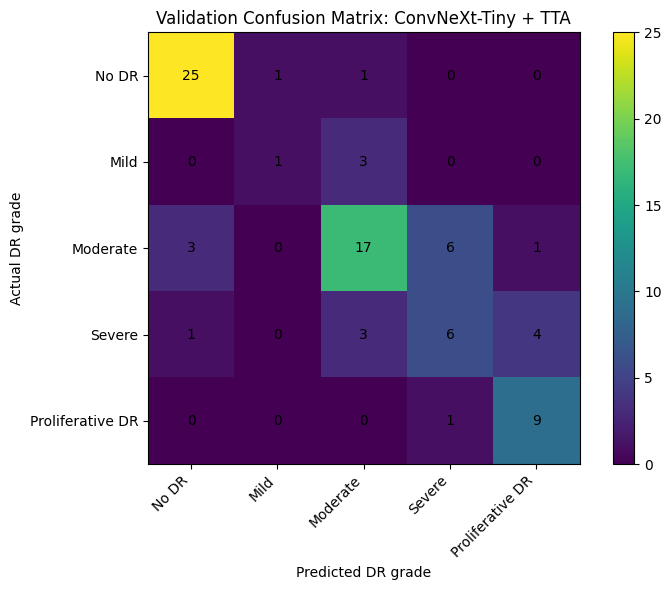

In [59]:
# Cell 51 — Detailed evaluation of the best validation candidate

import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix

best_name = ensemble_results.iloc[0]["model"]

if best_name == "EfficientNetB0 + TTA":
    best_probs = probs_eff_tta
elif best_name == "ConvNeXt-Tiny + TTA":
    best_probs = probs_conv_tta
else:
    best_probs = ensemble_probs

best_predictions = best_probs.argmax(axis=1)

print("Best candidate by validation QWK:", best_name)
print(
    classification_report(
        y_true_tta,
        best_predictions,
        labels=list(range(NUM_CLASSES)),
        target_names=[class_names[i] for i in range(NUM_CLASSES)],
        zero_division=0,
        digits=4,
    )
)

cm = confusion_matrix(
    y_true_tta,
    best_predictions,
    labels=list(range(NUM_CLASSES)),
)

plt.figure(figsize=(8, 6))
plt.imshow(cm, interpolation="nearest")
plt.title(f"Validation Confusion Matrix: {best_name}")
plt.colorbar()

labels = [class_names[i] for i in range(NUM_CLASSES)]
plt.xticks(range(NUM_CLASSES), labels, rotation=45, ha="right")
plt.yticks(range(NUM_CLASSES), labels)
plt.xlabel("Predicted DR grade")
plt.ylabel("Actual DR grade")

for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        plt.text(j, i, str(cm[i, j]), ha="center", va="center")

plt.tight_layout()
plt.show()

In [60]:
# Cell 52 — Save model-selection results

import json

selection = {
    "selected_candidate": best_name,
    "selection_metric": "validation QWK",
    "validation_metrics": metrics_from_probabilities(
        y_true_tta, best_probs
    ),
    "num_classes": NUM_CLASSES,
    "class_names": {str(k): v for k, v in class_names.items()},
}

with open(
    RESULTS_DIR / "selected_model_metadata.json",
    "w",
    encoding="utf-8",
) as f:
    json.dump(selection, f, indent=4)

np.save(
    RESULTS_DIR / "validation_selected_probabilities.npy",
    best_probs,
)
np.save(
    RESULTS_DIR / "validation_selected_labels.npy",
    y_true_tta,
)

print("Selected candidate:", best_name)
print("Saved metadata and validation predictions to:", RESULTS_DIR)

Selected candidate: ConvNeXt-Tiny + TTA
Saved metadata and validation predictions to: /kaggle/working/DR_Project/results


In [61]:
# Cell 53 — Prepare the selected model for final test evaluation

import json
import numpy as np
import torch
import torch.nn as nn
from pathlib import Path

with open(
    RESULTS_DIR / "selected_model_metadata.json",
    "r",
    encoding="utf-8",
) as f:
    selection = json.load(f)

selected_name = selection["selected_candidate"]
print("Selected model:", selected_name)

def load_model_for_test(model_name, checkpoint_path):
    model = build_model(
        model_name, pretrained=False
    ).to(DEVICE)

    try:
        state = torch.load(
            checkpoint_path,
            map_location=DEVICE,
            weights_only=True,
        )
    except Exception as exc:
        if (
            "Weights only load failed" not in str(exc)
            and "Unsupported global" not in str(exc)
        ):
            raise
        # Only for your own trusted training checkpoint.
        state = torch.load(
            checkpoint_path,
            map_location=DEVICE,
            weights_only=False,
        )

    if isinstance(state, dict) and "model_state_dict" in state:
        state = state["model_state_dict"]
    elif isinstance(state, dict) and "state_dict" in state:
        state = state["state_dict"]

    model.load_state_dict(state)
    model.eval()
    return model

eff_path = CHECKPOINT_DIR / "efficientnet_b0_finetuned_best.pth"
conv_path = CHECKPOINT_DIR / "convnext_tiny_best.pth"

if selected_name.startswith("EfficientNetB0"):
    test_eff_model = load_model_for_test(
        "efficientnet_b0", eff_path
    )
elif selected_name.startswith("ConvNeXt-Tiny"):
    test_conv_model = load_model_for_test(
        "convnext_tiny", conv_path
    )
else:
    test_eff_model = load_model_for_test(
        "efficientnet_b0", eff_path
    )
    test_conv_model = load_model_for_test(
        "convnext_tiny", conv_path
    )

print("Selected model components loaded.")

Selected model: ConvNeXt-Tiny + TTA
Selected model components loaded.


In [62]:
# Cell 54 — Final test evaluation

from contextlib import nullcontext
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    recall_score,
    cohen_kappa_score,
    classification_report,
    confusion_matrix,
)
import pandas as pd

@torch.no_grad()
def get_probabilities(model, loader, use_tta=True):
    model.eval()
    targets, probability_batches = [], []

    for images, labels in loader:
        images = images.to(DEVICE, non_blocking=True)

        context = (
            torch.autocast("cuda", enabled=True)
            if DEVICE.type == "cuda"
            else nullcontext()
        )

        with context:
            logits = model(images)
            probs = torch.softmax(logits.float(), dim=1)

            if use_tta:
                flipped_logits = model(torch.flip(images, dims=[3]))
                flipped_probs = torch.softmax(
                    flipped_logits.float(), dim=1
                )
                probs = (probs + flipped_probs) / 2

        targets.extend(labels.cpu().numpy())
        probability_batches.append(probs.cpu().numpy())

    return (
        np.asarray(targets),
        np.concatenate(probability_batches, axis=0),
    )

if selected_name.startswith("EfficientNetB0"):
    y_test, test_probs = get_probabilities(
        test_eff_model, test_loader, use_tta=True
    )
elif selected_name.startswith("ConvNeXt-Tiny"):
    y_test, test_probs = get_probabilities(
        test_conv_model, test_loader, use_tta=True
    )
else:
    y_test, probs_eff_test = get_probabilities(
        test_eff_model, test_loader, use_tta=True
    )
    y_test_conv, probs_conv_test = get_probabilities(
        test_conv_model, test_loader, use_tta=True
    )
    assert np.array_equal(y_test, y_test_conv)
    test_probs = (probs_eff_test + probs_conv_test) / 2

test_predictions = test_probs.argmax(axis=1)

test_metrics = {
    "accuracy": accuracy_score(y_test, test_predictions),
    "macro_f1": f1_score(
        y_test, test_predictions,
        average="macro", zero_division=0
    ),
    "macro_recall": recall_score(
        y_test, test_predictions,
        average="macro", zero_division=0
    ),
    "qwk": cohen_kappa_score(
        y_test, test_predictions, weights="quadratic"
    ),
}

print("FINAL TEST RESULTS")
for key, value in test_metrics.items():
    print(f"{key}: {value:.4f}")

print("\nClassification report:")
print(classification_report(
    y_test,
    test_predictions,
    labels=list(range(NUM_CLASSES)),
    target_names=[class_names[i] for i in range(NUM_CLASSES)],
    zero_division=0,
    digits=4,
))

pd.DataFrame([{
    "selected_model": selected_name,
    **test_metrics,
}]).to_csv(
    RESULTS_DIR / "final_test_metrics.csv",
    index=False,
)

FINAL TEST RESULTS
accuracy: 0.5049
macro_f1: 0.3993
macro_recall: 0.4065
qwk: 0.6217

Classification report:
                  precision    recall  f1-score   support

           No DR     0.6667    0.6471    0.6567        34
            Mild     0.0000    0.0000    0.0000         5
        Moderate     0.5000    0.5312    0.5152        32
          Severe     0.5000    0.3158    0.3871        19
Proliferative DR     0.3684    0.5385    0.4375        13

        accuracy                         0.5049       103
       macro avg     0.4070    0.4065    0.3993       103
    weighted avg     0.5141    0.5049    0.5035       103



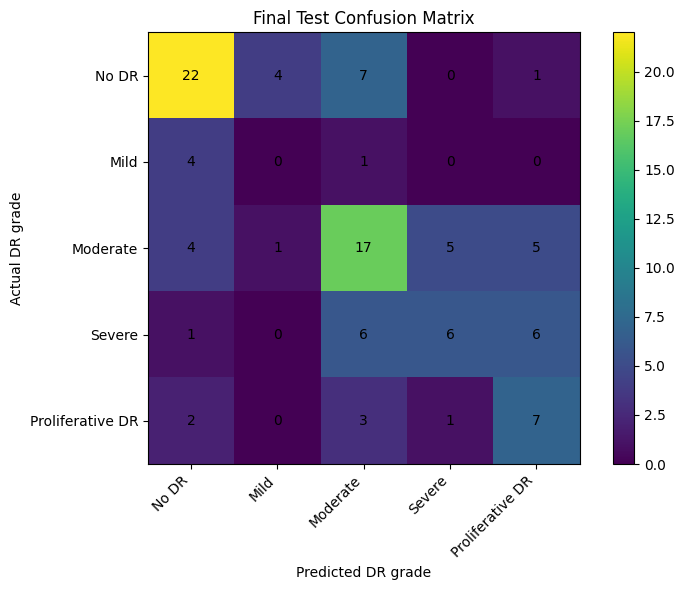

In [63]:
# Cell 55 — Final test confusion matrix

import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

cm_test = confusion_matrix(
    y_test,
    test_predictions,
    labels=list(range(NUM_CLASSES)),
)

labels = [class_names[i] for i in range(NUM_CLASSES)]

fig, ax = plt.subplots(figsize=(8, 6))
image = ax.imshow(cm_test, interpolation="nearest")
fig.colorbar(image, ax=ax)

ax.set(
    xticks=np.arange(NUM_CLASSES),
    yticks=np.arange(NUM_CLASSES),
    xticklabels=labels,
    yticklabels=labels,
    xlabel="Predicted DR grade",
    ylabel="Actual DR grade",
    title="Final Test Confusion Matrix",
)
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")

for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        ax.text(j, i, str(cm_test[i, j]), ha="center", va="center")

plt.tight_layout()
plt.savefig(
    RESULTS_DIR / "final_test_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

In [64]:
# Cell 56 — Fit temperature scaling on validation predictions

import torch
import torch.nn.functional as F

# Reuse validation probabilities saved in Cell 52.
val_probs_np = np.load(
    RESULTS_DIR / "validation_selected_probabilities.npy"
)
y_val_np = np.load(
    RESULTS_DIR / "validation_selected_labels.npy"
)

val_logits = torch.tensor(
    np.log(np.clip(val_probs_np, 1e-8, 1.0)),
    dtype=torch.float32,
    device=DEVICE,
)
val_targets = torch.tensor(
    y_val_np, dtype=torch.long, device=DEVICE
)

log_temperature = torch.nn.Parameter(
    torch.zeros(1, device=DEVICE)
)
optimizer_temp = torch.optim.LBFGS(
    [log_temperature], lr=0.05, max_iter=100
)

def closure():
    optimizer_temp.zero_grad()
    temperature = log_temperature.exp().clamp(0.05, 10.0)
    loss = F.cross_entropy(val_logits / temperature, val_targets)
    loss.backward()
    return loss

optimizer_temp.step(closure)

temperature = log_temperature.detach().exp().clamp(0.05, 10.0)
temperature_value = float(temperature.cpu())

print("Learned temperature:", round(temperature_value, 4))

with open(
    RESULTS_DIR / "calibration_temperature.json",
    "w",
    encoding="utf-8",
) as f:
    json.dump({"temperature": temperature_value}, f, indent=4)

Learned temperature: 1.0015


In [65]:
# Cell 57 — Apply validation-fitted temperature to test predictions

import json
import numpy as np

with open(
    RESULTS_DIR / "calibration_temperature.json",
    "r",
    encoding="utf-8",
) as f:
    temperature = json.load(f)["temperature"]

test_logits_approx = np.log(np.clip(test_probs, 1e-8, 1.0))
scaled_logits = test_logits_approx / temperature

scaled_logits -= scaled_logits.max(axis=1, keepdims=True)
exp_logits = np.exp(scaled_logits)
calibrated_probs = exp_logits / exp_logits.sum(axis=1, keepdims=True)

# Predictive entropy: higher values indicate greater uncertainty.
entropy = -np.sum(
    calibrated_probs * np.log(np.clip(calibrated_probs, 1e-8, 1.0)),
    axis=1,
)

# Maximum class probability is a simple confidence score.
confidence = calibrated_probs.max(axis=1)
calibrated_predictions = calibrated_probs.argmax(axis=1)

print("Mean predictive confidence:", round(float(confidence.mean()), 4))
print("Mean predictive entropy:", round(float(entropy.mean()), 4))

pd.DataFrame({
    "true_label": y_test,
    "predicted_label": calibrated_predictions,
    "confidence": confidence,
    "entropy": entropy,
}).to_csv(
    RESULTS_DIR / "test_predictions_with_uncertainty.csv",
    index=False,
)

Mean predictive confidence: 0.674
Mean predictive entropy: 0.8165


In [66]:
# Cell 58 — Confidence-based selective prediction

from sklearn.metrics import accuracy_score, f1_score

thresholds = [0.50, 0.60, 0.70, 0.80, 0.90]
selective_rows = []

for threshold in thresholds:
    accepted = confidence >= threshold
    coverage = float(accepted.mean())

    if accepted.sum() == 0:
        selective_rows.append({
            "confidence_threshold": threshold,
            "coverage": coverage,
            "accepted_cases": 0,
            "accuracy": np.nan,
            "macro_f1": np.nan,
        })
        continue

    selective_rows.append({
        "confidence_threshold": threshold,
        "coverage": coverage,
        "accepted_cases": int(accepted.sum()),
        "accuracy": accuracy_score(
            y_test[accepted],
            calibrated_predictions[accepted],
        ),
        "macro_f1": f1_score(
            y_test[accepted],
            calibrated_predictions[accepted],
            average="macro",
            zero_division=0,
        ),
    })

selective_df = pd.DataFrame(selective_rows)
display(selective_df)

selective_df.to_csv(
    RESULTS_DIR / "selective_prediction_results.csv",
    index=False,
)

,confidence_threshold,coverage,accepted_cases,accuracy,macro_f1
0,0.5,0.786408,81,0.567901,0.443784
1,0.6,0.650485,67,0.552239,0.389161
2,0.7,0.495146,51,0.568627,0.396098
3,0.8,0.281553,29,0.724138,0.485407
4,0.9,0.087379,9,0.777778,0.625000


In [67]:
# Cell 59 — Export final experiment summary

summary = {
    "selected_model": selected_name,
    "validation_selection_metric": "QWK",
    "test_metrics": {
        key: float(value) for key, value in test_metrics.items()
    },
    "temperature": float(temperature),
    "mean_test_confidence": float(confidence.mean()),
    "mean_test_entropy": float(entropy.mean()),
}

summary_path = RESULTS_DIR / "final_experiment_summary.json"

with open(summary_path, "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=4)

print("Experiment summary saved:", summary_path)
print("\nFiles generated:")
for path in sorted(RESULTS_DIR.iterdir()):
    if path.is_file():
        print(path.name)

Experiment summary saved: /kaggle/working/DR_Project/results/final_experiment_summary.json

Files generated:
benchmark_training_summary.csv
calibration_temperature.json
convnext_tiny_training_history.csv
efficientnet_b0_finetune_history.csv
efficientnet_b0_training_history.csv
efficientnet_finetune_comparison.csv
ensemble_validation_results.csv
final_experiment_summary.json
final_test_confusion_matrix.png
final_test_metrics.csv
resnet50_training_history.csv
selected_model_metadata.json
selective_prediction_results.csv
test_predictions_with_uncertainty.csv
validation_model_comparison.csv
validation_selected_labels.npy
validation_selected_probabilities.npy


In [68]:
# CELL 60 — Training data and imbalance audit

import numpy as np
import pandas as pd

assert len(train_loader.dataset) == len(train_df), (
    "Training dataset length does not match train_df."
)

audit_df = pd.DataFrame({
    "DR_grade": [class_names[i] for i in range(NUM_CLASSES)],
    "train_count": [
        int((train_df["label"] == i).sum())
        for i in range(NUM_CLASSES)
    ],
    "validation_count": [
        int((val_df["label"] == i).sum())
        for i in range(NUM_CLASSES)
    ],
})

audit_df["train_percent"] = (
    100 * audit_df["train_count"] / len(train_df)
).round(2)

display(audit_df)

print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Validation accuracy baseline: 0.7073")
print("Validation macro-F1 baseline: 0.6175")

audit_df.to_csv(
    RESULTS_DIR / "class_imbalance_audit.csv",
    index=False,
)

assert train_df["label"].between(0, 4).all()
assert val_df["label"].between(0, 4).all()

,DR_grade,train_count,validation_count,train_percent
0,No DR,106,27,32.62
1,Mild,15,4,4.62
2,Moderate,106,27,32.62
3,Severe,59,14,18.15
4,Proliferative DR,39,10,12.00


Training images: 325
Validation images: 82
Validation accuracy baseline: 0.7073
Validation macro-F1 baseline: 0.6175


In [69]:
# CELL 61 — ConvNeXt-Tiny fine-tuning with balanced sampling

import copy
import torch
import torch.nn as nn
import pandas as pd
from torch.utils.data import DataLoader, WeightedRandomSampler
from contextlib import nullcontext

BASE_CHECKPOINT = CHECKPOINT_DIR / "convnext_tiny_best.pth"
NEW_CHECKPOINT = CHECKPOINT_DIR / "convnext_tiny_balanced_best.pth"

if not BASE_CHECKPOINT.exists():
    raise FileNotFoundError(
        f"Existing ConvNeXt checkpoint not found: {BASE_CHECKPOINT}"
    )

# Load your own trusted checkpoint.
try:
    checkpoint = torch.load(
        BASE_CHECKPOINT,
        map_location=DEVICE,
        weights_only=True,
    )
except Exception as exc:
    if (
        "Weights only load failed" not in str(exc)
        and "Unsupported global" not in str(exc)
    ):
        raise
    checkpoint = torch.load(
        BASE_CHECKPOINT,
        map_location=DEVICE,
        weights_only=False,
    )

if isinstance(checkpoint, dict) and "model_state_dict" in checkpoint:
    checkpoint = checkpoint["model_state_dict"]
elif isinstance(checkpoint, dict) and "state_dict" in checkpoint:
    checkpoint = checkpoint["state_dict"]

model_bal = build_model(
    "convnext_tiny",
    pretrained=False,
).to(DEVICE)

model_bal.load_state_dict(checkpoint)

# Balanced sampling: minority classes are sampled more frequently.
train_labels = train_df["label"].astype(int).to_numpy()
counts = np.bincount(train_labels, minlength=NUM_CLASSES)

sample_weights = 1.0 / np.maximum(counts[train_labels], 1)

sampler_generator = torch.Generator()
sampler_generator.manual_seed(SEED)

balanced_sampler = WeightedRandomSampler(
    weights=torch.as_tensor(sample_weights, dtype=torch.double),
    num_samples=len(train_labels),
    replacement=True,
    generator=sampler_generator,
)

balanced_loader = DataLoader(
    train_loader.dataset,
    batch_size=train_loader.batch_size,
    sampler=balanced_sampler,
    num_workers=NUM_WORKERS,
    pin_memory=(DEVICE.type == "cuda"),
    drop_last=False,
)

# Do not apply inverse-frequency class weights again in this experiment.
criterion_bal = nn.CrossEntropyLoss(label_smoothing=0.03)

optimizer_bal = torch.optim.AdamW(
    model_bal.parameters(),
    lr=1e-5,
    weight_decay=1e-4,
)

scheduler_bal = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_bal,
    mode="max",
    factor=0.5,
    patience=1,
)

scaler_bal = torch.amp.GradScaler(
    "cuda",
    enabled=(DEVICE.type == "cuda"),
)

def autocast_context():
    if DEVICE.type == "cuda":
        return torch.autocast("cuda", enabled=True)
    return nullcontext()

# Establish baseline using the same unweighted validation loss.
baseline_bal, _, _ = evaluate_model(
    model_bal, val_loader, criterion_bal
)

best_accuracy_bal = baseline_bal["accuracy"]
best_state_bal = copy.deepcopy(model_bal.state_dict())
best_epoch_bal = 0
wait_bal = 0
history_bal = []

MAX_EPOCHS_BAL = 8
PATIENCE_BAL = 3

print("Starting validation metrics:", baseline_bal)
print("Training class counts:", counts.tolist())

for epoch in range(1, MAX_EPOCHS_BAL + 1):
    model_bal.train()
    total_loss = 0.0
    total_seen = 0

    for images, labels in balanced_loader:
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        optimizer_bal.zero_grad(set_to_none=True)

        with autocast_context():
            logits = model_bal(images)
            loss = criterion_bal(logits, labels)

        scaler_bal.scale(loss).backward()
        scaler_bal.unscale_(optimizer_bal)

        torch.nn.utils.clip_grad_norm_(
            model_bal.parameters(),
            max_norm=1.0,
        )

        scaler_bal.step(optimizer_bal)
        scaler_bal.update()

        total_loss += loss.item() * labels.size(0)
        total_seen += labels.size(0)

    train_loss = total_loss / max(total_seen, 1)

    val_metrics_bal, _, _ = evaluate_model(
        model_bal, val_loader, criterion_bal
    )

    scheduler_bal.step(val_metrics_bal["accuracy"])

    history_bal.append({
        "epoch": epoch,
        "train_loss": train_loss,
        **{
            f"val_{key}": value
            for key, value in val_metrics_bal.items()
        },
    })

    print(
        f"Epoch {epoch}/{MAX_EPOCHS_BAL} | "
        f"Train loss={train_loss:.4f} | "
        f"Accuracy={val_metrics_bal['accuracy']:.4f} | "
        f"Macro-F1={val_metrics_bal['macro_f1']:.4f} | "
        f"QWK={val_metrics_bal['qwk']:.4f}"
    )

    # Primary goal: validation accuracy.
    # For equal accuracy, prefer higher QWK.
    improved = (
        val_metrics_bal["accuracy"] > best_accuracy_bal
        or (
            val_metrics_bal["accuracy"] == best_accuracy_bal
            and val_metrics_bal["qwk"] > baseline_bal["qwk"]
            and epoch > best_epoch_bal
        )
    )

    if improved:
        best_accuracy_bal = val_metrics_bal["accuracy"]
        best_state_bal = copy.deepcopy(model_bal.state_dict())
        best_epoch_bal = epoch
        wait_bal = 0

        torch.save({
            "model_name": "convnext_tiny",
            "model_state_dict": best_state_bal,
            "epoch": epoch,
            "best_val_accuracy": best_accuracy_bal,
            "num_classes": NUM_CLASSES,
        }, NEW_CHECKPOINT)

        print("  Saved best validation-accuracy checkpoint.")
    else:
        wait_bal += 1

    if wait_bal >= PATIENCE_BAL:
        print("Early stopping.")
        break

model_bal.load_state_dict(best_state_bal)

pd.DataFrame(history_bal).to_csv(
    RESULTS_DIR / "convnext_balanced_history.csv",
    index=False,
)

print("\nBest epoch:", best_epoch_bal)
print("Best validation accuracy:", round(best_accuracy_bal, 4))
print("Saved checkpoint:", NEW_CHECKPOINT)

Starting validation metrics: {'accuracy': 0.6829268292682927, 'macro_f1': 0.5964370849276509, 'macro_recall': 0.6051322751322752, 'qwk': np.float64(0.8459092223185892), 'loss': 0.8299028931594477}
Training class counts: [106, 15, 106, 59, 39]
Epoch 1/8 | Train loss=0.4447 | Accuracy=0.6585 | Macro-F1=0.5090 | QWK=0.8282
Epoch 2/8 | Train loss=0.3806 | Accuracy=0.6951 | Macro-F1=0.5374 | QWK=0.8416
  Saved best validation-accuracy checkpoint.
Epoch 3/8 | Train loss=0.4037 | Accuracy=0.6829 | Macro-F1=0.5941 | QWK=0.8509
Epoch 4/8 | Train loss=0.4052 | Accuracy=0.6585 | Macro-F1=0.5093 | QWK=0.8268
Epoch 5/8 | Train loss=0.3859 | Accuracy=0.6585 | Macro-F1=0.5071 | QWK=0.8312
Early stopping.

Best epoch: 2
Best validation accuracy: 0.6951
Saved checkpoint: /kaggle/working/DR_Project/checkpoints/convnext_tiny_balanced_best.pth


In [73]:
# CELL 62 — Compare original and balanced ConvNeXt-Tiny

import numpy as np
import pandas as pd
import torch

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    cohen_kappa_score,
)

# ============================================================
# 1. Predict class probabilities
# ============================================================
def predict_probabilities(model, loader, use_tta=False):
    model.eval()
    all_targets = []
    all_probs = []

    with torch.inference_mode():
        for images, labels in loader:
            images = images.to(DEVICE, non_blocking=True)

            with autocast_context():
                # Original image prediction
                logits = model(images)
                probs = torch.softmax(logits.float(), dim=1)

                if use_tta:
                    # Predict a horizontally flipped version
                    flipped_images = torch.flip(images, dims=[3])
                    flipped_logits = model(flipped_images)

                    flipped_probs = torch.softmax(
                        flipped_logits.float(), dim=1
                    )

                    # Average both probability distributions
                    probs = (probs + flipped_probs) / 2.0

            all_targets.extend(labels.cpu().numpy().tolist())
            all_probs.append(probs.cpu().numpy())

    return np.asarray(all_targets), np.concatenate(all_probs, axis=0)


# ============================================================
# 2. Calculate evaluation metrics
# ============================================================
def metrics_from_probs(y_true, probs):
    predictions = np.argmax(probs, axis=1)

    return {
        "accuracy": accuracy_score(y_true, predictions),
        "macro_f1": f1_score(
            y_true,
            predictions,
            average="macro",
            zero_division=0,
        ),
        "qwk": cohen_kappa_score(
            y_true,
            predictions,
            weights="quadratic",
        ),
    }


# ============================================================
# 3. Load the original ConvNeXt-Tiny checkpoint
# ============================================================
assert BASE_CHECKPOINT.exists(), (
    f"Original checkpoint not found: {BASE_CHECKPOINT}"
)

model_original = build_model(
    "convnext_tiny",
    pretrained=False,
).to(DEVICE)

# IMPORTANT:
# weights_only=False is appropriate only for a checkpoint
# that you created yourself or otherwise fully trust.
checkpoint = torch.load(
    BASE_CHECKPOINT,
    map_location="cpu",
    weights_only=False,
)

# Handle either a full checkpoint dictionary or a raw state_dict.
if isinstance(checkpoint, dict) and "model_state_dict" in checkpoint:
    original_state = checkpoint["model_state_dict"]
else:
    original_state = checkpoint

model_original.load_state_dict(original_state, strict=True)
model_original.eval()

print("Original ConvNeXt-Tiny checkpoint loaded successfully.")

# The balanced model should have been created in Cell 61.
assert "model_bal" in globals(), (
    "model_bal is missing. Run Cell 61 first."
)
model_bal.eval()


# ============================================================
# 4. Evaluate all models on the same validation set
# ============================================================
y_original, p_original = predict_probabilities(
    model_original,
    val_loader,
    use_tta=False,
)

y_bal, p_bal = predict_probabilities(
    model_bal,
    val_loader,
    use_tta=False,
)

y_bal_tta, p_bal_tta = predict_probabilities(
    model_bal,
    val_loader,
    use_tta=True,
)

# Ensure the targets and sample order match
assert np.array_equal(y_original, y_bal), (
    "Original and balanced models used different validation targets."
)

assert np.array_equal(y_bal, y_bal_tta), (
    "Balanced model and TTA predictions used different targets."
)


# ============================================================
# 5. Build the comparison table
# ============================================================
comparison = pd.DataFrame([
    {
        "model": "Original ConvNeXt-Tiny",
        **metrics_from_probs(y_original, p_original),
    },
    {
        "model": "Balanced fine-tuned ConvNeXt-Tiny",
        **metrics_from_probs(y_bal, p_bal),
    },
    {
        "model": "Balanced ConvNeXt-Tiny + TTA",
        **metrics_from_probs(y_bal_tta, p_bal_tta),
    },
])

comparison = comparison.sort_values(
    by=["accuracy", "macro_f1", "qwk"],
    ascending=False,
).reset_index(drop=True)

display(comparison.round(4))


# ============================================================
# 6. Save comparison results
# ============================================================
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

comparison_path = (
    RESULTS_DIR / "convnext_accuracy_comparison.csv"
)

comparison.to_csv(comparison_path, index=False)

print(f"Comparison saved to: {comparison_path}")
print("Cell 62 completed successfully.")

Original ConvNeXt-Tiny checkpoint loaded successfully.


,model,accuracy,macro_f1,qwk
0,Balanced fine-tuned ConvNeXt-Tiny,0.6951,0.5374,0.8416
1,Original ConvNeXt-Tiny,0.6829,0.5964,0.8459
2,Balanced ConvNeXt-Tiny + TTA,0.6707,0.5080,0.8192


Comparison saved to: /kaggle/working/DR_Project/results/convnext_accuracy_comparison.csv
Cell 62 completed successfully.


Selected validation candidate: Balanced fine-tuned ConvNeXt-Tiny

Classification report:

                  precision    recall  f1-score   support

           No DR     0.7353    0.9259    0.8197        27
            Mild     0.0000    0.0000    0.0000         4
        Moderate     0.7037    0.7037    0.7037        27
          Severe     0.5714    0.2857    0.3810        14
Proliferative DR     0.6923    0.9000    0.7826        10

        accuracy                         0.6951        82
       macro avg     0.5405    0.5631    0.5374        82
    weighted avg     0.6558    0.6951    0.6621        82



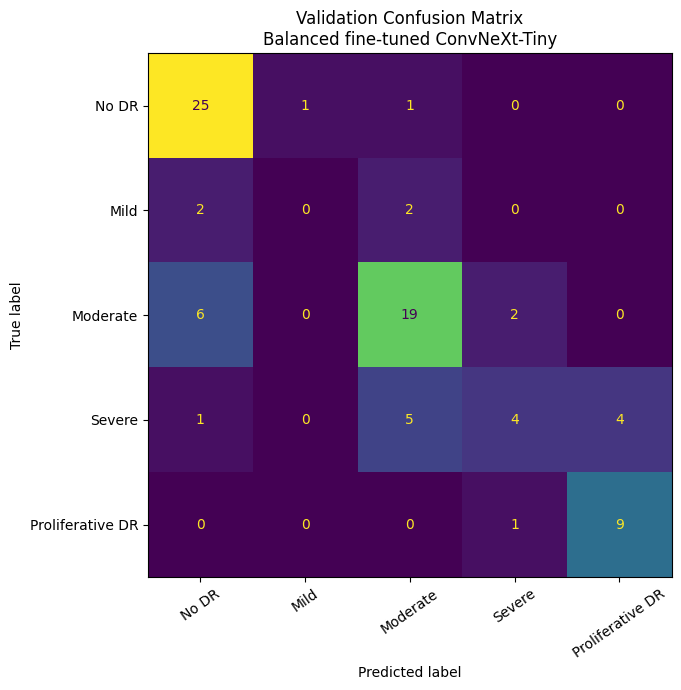

Classification report and confusion matrix saved.


In [74]:
# CELL 63 — Detailed validation evaluation

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

# Class names must follow the label mapping used during training.
CLASS_NAMES = [
    "No DR",
    "Mild",
    "Moderate",
    "Severe",
    "Proliferative DR",
]

# Probability arrays produced by Cell 62.
probability_candidates = {
    "Original ConvNeXt-Tiny": p_original,
    "Balanced fine-tuned ConvNeXt-Tiny": p_bal,
    "Balanced ConvNeXt-Tiny + TTA": p_bal_tta,
}

# Select the highest-ranked candidate from Cell 62.
best_candidate_name = comparison.iloc[0]["model"]
best_probs = probability_candidates[best_candidate_name]

y_true = y_original
y_pred = np.argmax(best_probs, axis=1)

assert len(y_true) == len(y_pred)
assert best_probs.shape[1] == len(CLASS_NAMES)

print("Selected validation candidate:", best_candidate_name)
print("\nClassification report:\n")

print(
    classification_report(
        y_true,
        y_pred,
        labels=list(range(len(CLASS_NAMES))),
        target_names=CLASS_NAMES,
        digits=4,
        zero_division=0,
    )
)

# Confusion matrix: rows = true labels, columns = predictions.
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(len(CLASS_NAMES))),
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=CLASS_NAMES,
)

fig, ax = plt.subplots(figsize=(9, 7))
disp.plot(
    ax=ax,
    values_format="d",
    xticks_rotation=35,
    colorbar=False,
)
ax.set_title(f"Validation Confusion Matrix\n{best_candidate_name}")
plt.tight_layout()
plt.show()

# Save class-wise results.
report_dict = classification_report(
    y_true,
    y_pred,
    labels=list(range(len(CLASS_NAMES))),
    target_names=CLASS_NAMES,
    output_dict=True,
    zero_division=0,
)

report_df = pd.DataFrame(report_dict).transpose()
report_df.to_csv(
    RESULTS_DIR / "best_validation_classification_report.csv"
)

pd.DataFrame(
    cm,
    index=[f"True_{name}" for name in CLASS_NAMES],
    columns=[f"Pred_{name}" for name in CLASS_NAMES],
).to_csv(RESULTS_DIR / "best_validation_confusion_matrix.csv")

print("Classification report and confusion matrix saved.")

In [75]:
# CELL 64 — Save the validation-selected model

candidate_models = {
    "Original ConvNeXt-Tiny": model_original,
    "Balanced fine-tuned ConvNeXt-Tiny": model_bal,
    "Balanced ConvNeXt-Tiny + TTA": model_bal,
}

candidate_tta = {
    "Original ConvNeXt-Tiny": False,
    "Balanced fine-tuned ConvNeXt-Tiny": False,
    "Balanced ConvNeXt-Tiny + TTA": True,
}

selected_name = comparison.iloc[0]["model"]
selected_model = candidate_models[selected_name]
selected_use_tta = candidate_tta[selected_name]

selected_metrics = comparison.loc[
    comparison["model"] == selected_name
].iloc[0]

FINAL_CHECKPOINT = (
    CHECKPOINT_DIR / "selected_convnext_validation_best.pth"
)

# Store tensors on CPU to make the checkpoint portable.
selected_state = {
    key: value.detach().cpu()
    for key, value in selected_model.state_dict().items()
}

torch.save(
    {
        "model_name": "convnext_tiny",
        "selected_candidate": selected_name,
        "model_state_dict": selected_state,
        "use_tta": selected_use_tta,
        "num_classes": NUM_CLASSES,
        "image_size": IMAGE_SIZE,
        "class_names": CLASS_NAMES,
        "validation_accuracy": float(selected_metrics["accuracy"]),
        "validation_macro_f1": float(selected_metrics["macro_f1"]),
        "validation_qwk": float(selected_metrics["qwk"]),
    },
    FINAL_CHECKPOINT,
)

print("Selected candidate:", selected_name)
print("Use TTA at inference:", selected_use_tta)
print(f"Validation accuracy: {selected_metrics['accuracy']:.4f}")
print(f"Validation macro-F1: {selected_metrics['macro_f1']:.4f}")
print(f"Validation QWK: {selected_metrics['qwk']:.4f}")
print("Saved checkpoint:", FINAL_CHECKPOINT)

Selected candidate: Balanced fine-tuned ConvNeXt-Tiny
Use TTA at inference: False
Validation accuracy: 0.6951
Validation macro-F1: 0.5374
Validation QWK: 0.8416
Saved checkpoint: /kaggle/working/DR_Project/checkpoints/selected_convnext_validation_best.pth


In [76]:
# CELL 65 — One-time final test evaluation

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    cohen_kappa_score,
    classification_report,
)

# Reload the saved selection to verify the saved checkpoint.
saved_checkpoint = torch.load(
    FINAL_CHECKPOINT,
    map_location="cpu",
    weights_only=True,
)

final_model = build_model(
    saved_checkpoint["model_name"],
    pretrained=False,
).to(DEVICE)

final_model.load_state_dict(
    saved_checkpoint["model_state_dict"],
    strict=True,
)
final_model.eval()

# test_loader must use the same preprocessing and label mapping.
y_test, p_test = predict_probabilities(
    final_model,
    test_loader,
    use_tta=saved_checkpoint["use_tta"],
)

test_pred = np.argmax(p_test, axis=1)

test_metrics = {
    "accuracy": accuracy_score(y_test, test_pred),
    "macro_f1": f1_score(
        y_test, test_pred,
        average="macro",
        zero_division=0,
    ),
    "qwk": cohen_kappa_score(
        y_test, test_pred,
        weights="quadratic",
    ),
}

print("Final test results:")
for metric, value in test_metrics.items():
    print(f"{metric}: {value:.4f}")

print("\nFinal test classification report:")
print(
    classification_report(
        y_test,
        test_pred,
        labels=list(range(NUM_CLASSES)),
        target_names=CLASS_NAMES,
        digits=4,
        zero_division=0,
    )
)

pd.DataFrame([test_metrics]).to_csv(
    RESULTS_DIR / "final_test_metrics.csv",
    index=False,
)

print("Final test metrics saved.")

Final test results:
accuracy: 0.5534
macro_f1: 0.4045
qwk: 0.6505

Final test classification report:
                  precision    recall  f1-score   support

           No DR     0.7105    0.7941    0.7500        34
            Mild     0.0000    0.0000    0.0000         5
        Moderate     0.5385    0.6562    0.5915        32
          Severe     0.5000    0.2105    0.2963        19
Proliferative DR     0.3846    0.3846    0.3846        13

        accuracy                         0.5534       103
       macro avg     0.4267    0.4091    0.4045       103
    weighted avg     0.5426    0.5534    0.5346       103

Final test metrics saved.


,true_label,predicted_label,confidence,entropy,normalized_entropy,correct,true_class,predicted_class
0,3,4,0.887203,0.457356,0.284171,False,Severe,Proliferative DR
1,3,2,0.460095,1.204197,0.748210,False,Severe,Moderate
2,0,0,0.901193,0.356431,0.221463,True,No DR,No DR
3,2,2,0.538494,1.124280,0.698554,True,Moderate,Moderate
4,2,0,0.679178,0.808493,0.502345,False,Moderate,No DR
5,2,2,0.370269,1.407017,0.874229,True,Moderate,Moderate
6,2,2,0.701111,0.780766,0.485117,True,Moderate,Moderate
7,4,4,0.746902,0.755390,0.469350,True,Proliferative DR,Proliferative DR
8,3,2,0.885768,0.422702,0.262640,False,Severe,Moderate
9,0,0,0.955576,0.210031,0.130500,True,No DR,No DR


Mean confidence for correct predictions: 0.7893
Mean confidence for incorrect predictions: 0.6614


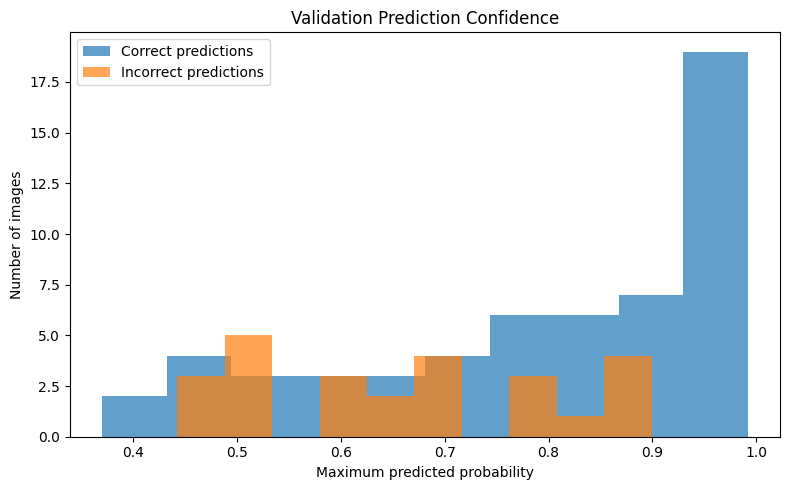

Confidence analysis saved.


In [77]:
# CELL 66 — Prediction confidence analysis

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Use the best validation candidate selected in Cell 63.
# If you have not run Cell 63, select from Cell 62 here.
probabilities = best_probs
targets = y_original
predictions = np.argmax(probabilities, axis=1)

# Maximum predicted probability for each image
confidence = np.max(probabilities, axis=1)

# Entropy: higher values indicate more uncertainty
epsilon = 1e-12
entropy = -np.sum(
    probabilities * np.log(np.clip(probabilities, epsilon, 1.0)),
    axis=1,
)

# Normalized entropy ranges approximately from 0 to 1.
normalized_entropy = entropy / np.log(NUM_CLASSES)

correct = (predictions == targets)

confidence_df = pd.DataFrame({
    "true_label": targets,
    "predicted_label": predictions,
    "confidence": confidence,
    "entropy": entropy,
    "normalized_entropy": normalized_entropy,
    "correct": correct,
})

confidence_df["true_class"] = confidence_df["true_label"].map(
    dict(enumerate(CLASS_NAMES))
)
confidence_df["predicted_class"] = confidence_df["predicted_label"].map(
    dict(enumerate(CLASS_NAMES))
)

display(confidence_df.head(10))

# Compare confidence for correct and incorrect predictions.
print("Mean confidence for correct predictions:",
      round(confidence_df.loc[correct, "confidence"].mean(), 4)
      if correct.any() else "No correct predictions")

print("Mean confidence for incorrect predictions:",
      round(confidence_df.loc[~correct, "confidence"].mean(), 4)
      if (~correct).any() else "No incorrect predictions")

# Confidence distribution
plt.figure(figsize=(8, 5))
plt.hist(
    confidence_df.loc[correct, "confidence"],
    bins=10,
    alpha=0.7,
    label="Correct predictions",
)
plt.hist(
    confidence_df.loc[~correct, "confidence"],
    bins=10,
    alpha=0.7,
    label="Incorrect predictions",
)
plt.xlabel("Maximum predicted probability")
plt.ylabel("Number of images")
plt.title("Validation Prediction Confidence")
plt.legend()
plt.tight_layout()
plt.show()

# Save per-image uncertainty results.
confidence_df.to_csv(
    RESULTS_DIR / "validation_confidence_analysis.csv",
    index=False,
)

print("Confidence analysis saved.")

,confidence_threshold,coverage,accepted_images,referred_images,accuracy_on_accepted
0,0.5,0.8902,73,9,0.6986
1,0.6,0.7561,62,20,0.7419
2,0.7,0.6220,51,31,0.8039
3,0.8,0.4512,37,45,0.8649
4,0.9,0.2927,24,58,1.0000


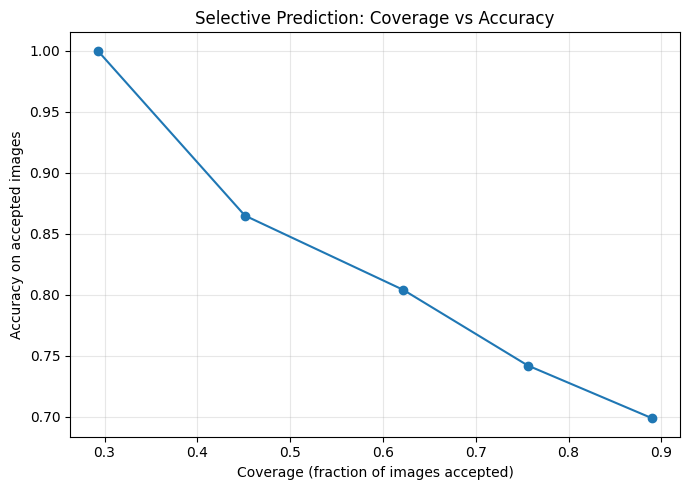

Selective prediction results saved.


In [78]:
# CELL 67 — Validation selective prediction

thresholds = [0.50, 0.60, 0.70, 0.80, 0.90]
selective_results = []

for threshold in thresholds:
    accepted = confidence >= threshold
    coverage = accepted.mean()

    if accepted.any():
        selective_accuracy = accuracy_score(
            targets[accepted],
            predictions[accepted],
        )
    else:
        selective_accuracy = np.nan

    selective_results.append({
        "confidence_threshold": threshold,
        "coverage": coverage,
        "accepted_images": int(accepted.sum()),
        "referred_images": int((~accepted).sum()),
        "accuracy_on_accepted": selective_accuracy,
    })

selective_df = pd.DataFrame(selective_results)
display(selective_df.round(4))

selective_df.to_csv(
    RESULTS_DIR / "validation_selective_prediction.csv",
    index=False,
)

plt.figure(figsize=(7, 5))
plt.plot(
    selective_df["coverage"],
    selective_df["accuracy_on_accepted"],
    marker="o",
)
plt.xlabel("Coverage (fraction of images accepted)")
plt.ylabel("Accuracy on accepted images")
plt.title("Selective Prediction: Coverage vs Accuracy")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("Selective prediction results saved.")

Validation NLL: 0.7441
Multiclass Brier score: 0.4336
Top-label ECE: 0.1324


,confidence_interval,count,mean_confidence,accuracy
0,0.3-0.4,2,0.3764,1.0000
1,0.4-0.5,7,0.4630,0.5714
2,0.5-0.6,11,0.5345,0.4545
3,0.6-0.7,11,0.6513,0.4545
4,0.7-0.8,14,0.7454,0.6429
5,0.8-0.9,13,0.8626,0.6154
6,0.9-1.0,24,0.9516,1.0000


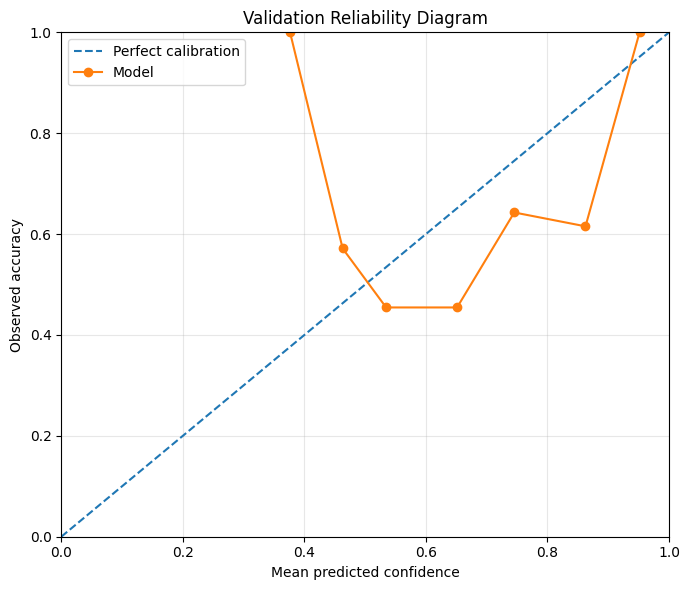

Calibration analysis saved.


In [79]:
# CELL 68 — Calibration evaluation on validation data

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import log_loss

# Use the same validation predictions selected in Cell 63.
probs = np.asarray(best_probs, dtype=np.float64)
targets = np.asarray(y_original, dtype=int)

assert probs.ndim == 2 and probs.shape[1] == NUM_CLASSES
assert len(probs) == len(targets)
assert np.all(np.isfinite(probs))
assert np.allclose(probs.sum(axis=1), 1.0, atol=1e-5)

predictions = probs.argmax(axis=1)
confidence = probs.max(axis=1)
correct = (predictions == targets).astype(float)

# Multiclass Brier score: lower is better.
one_hot = np.eye(NUM_CLASSES)[targets]
brier_score = np.mean(np.sum((probs - one_hot) ** 2, axis=1))

# Negative log-likelihood: lower is better.
nll = log_loss(
    targets,
    probs,
    labels=list(range(NUM_CLASSES)),
)

# Expected calibration error (ECE), using confidence bins.
num_bins = 10
bin_edges = np.linspace(0.0, 1.0, num_bins + 1)
ece = 0.0
calibration_rows = []

for i in range(num_bins):
    # Include confidence=1.0 in the final bin.
    if i == num_bins - 1:
        mask = (
            (confidence >= bin_edges[i])
            & (confidence <= bin_edges[i + 1])
        )
    else:
        mask = (
            (confidence >= bin_edges[i])
            & (confidence < bin_edges[i + 1])
        )

    count = int(mask.sum())

    if count == 0:
        continue

    mean_confidence = float(confidence[mask].mean())
    bin_accuracy = float(correct[mask].mean())

    ece += (count / len(targets)) * abs(
        bin_accuracy - mean_confidence
    )

    calibration_rows.append({
        "confidence_interval": (
            f"{bin_edges[i]:.1f}-{bin_edges[i + 1]:.1f}"
        ),
        "count": count,
        "mean_confidence": mean_confidence,
        "accuracy": bin_accuracy,
    })

calibration_df = pd.DataFrame(calibration_rows)

print(f"Validation NLL: {nll:.4f}")
print(f"Multiclass Brier score: {brier_score:.4f}")
print(f"Top-label ECE: {ece:.4f}")

display(calibration_df.round(4))

# Reliability diagram
plt.figure(figsize=(7, 6))

plt.plot(
    [0, 1], [0, 1],
    linestyle="--",
    label="Perfect calibration",
)

if not calibration_df.empty:
    plt.plot(
        calibration_df["mean_confidence"],
        calibration_df["accuracy"],
        marker="o",
        label="Model",
    )

plt.xlabel("Mean predicted confidence")
plt.ylabel("Observed accuracy")
plt.title("Validation Reliability Diagram")
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

calibration_df.to_csv(
    RESULTS_DIR / "validation_calibration_bins.csv",
    index=False,
)

print("Calibration analysis saved.")

In [80]:
# CELL 68 — Temperature scaling using validation logits

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

from sklearn.metrics import log_loss

# Use the selected validation candidate from Cell 63.
# If you have not run Cell 63, use the selected candidate from Cell 62.
calibration_model = selected_model
calibration_model.eval()

# Collect validation logits and labels.
all_logits = []
all_labels = []

with torch.inference_mode():
    for images, labels in val_loader:
        images = images.to(DEVICE, non_blocking=True)

        with autocast_context():
            logits = calibration_model(images)

        all_logits.append(logits.float().cpu())
        all_labels.append(labels.cpu())

val_logits = torch.cat(all_logits, dim=0)
val_labels = torch.cat(all_labels, dim=0).long()

assert val_logits.shape[0] == val_labels.shape[0]
assert val_logits.shape[1] == NUM_CLASSES

# Optimize one scalar temperature.
# Use CPU float64 for stable optimization.
logits_cpu = val_logits.double()
labels_cpu = val_labels.long()

log_temperature = torch.nn.Parameter(
    torch.zeros((), dtype=torch.float64)
)

optimizer = torch.optim.LBFGS(
    [log_temperature],
    lr=0.1,
    max_iter=100,
    line_search_fn="strong_wolfe",
)

def closure():
    optimizer.zero_grad()

    temperature = torch.exp(log_temperature).clamp(
        min=0.05, max=20.0
    )

    loss = F.cross_entropy(
        logits_cpu / temperature,
        labels_cpu,
    )

    loss.backward()
    return loss

optimizer.step(closure)

temperature = torch.exp(log_temperature.detach()).clamp(
    min=0.05, max=20.0
).item()

# Compute probabilities before and after calibration.
probs_before = torch.softmax(logits_cpu, dim=1).numpy()

probs_after = torch.softmax(
    logits_cpu / temperature, dim=1
).numpy()

y_cal = labels_cpu.numpy()

nll_before = log_loss(
    y_cal, probs_before, labels=list(range(NUM_CLASSES))
)
nll_after = log_loss(
    y_cal, probs_after, labels=list(range(NUM_CLASSES))
)

calibration_comparison = pd.DataFrame([
    {
        "method": "Before temperature scaling",
        "temperature": 1.0,
        "NLL": nll_before,
    },
    {
        "method": "After temperature scaling",
        "temperature": temperature,
        "NLL": nll_after,
    },
])

display(calibration_comparison.round(5))

calibration_comparison.to_csv(
    RESULTS_DIR / "temperature_scaling_comparison.csv",
    index=False,
)

# Save the scalar temperature for later inference.
temperature_path = RESULTS_DIR / "validation_temperature.txt"
temperature_path.write_text(str(temperature))

print(f"Optimized temperature: {temperature:.4f}")
print(f"Saved temperature to: {temperature_path}")

,method,temperature,NLL
0,Before temperature scaling,1.0000,0.74409
1,After temperature scaling,1.1381,0.73825


Optimized temperature: 1.1381
Saved temperature to: /kaggle/working/DR_Project/results/validation_temperature.txt


,method,accuracy,NLL,multiclass_Brier,top_label_ECE
0,Before calibration,0.69512,0.74409,0.43356,0.13245
1,After temperature scaling,0.69512,0.73825,0.42565,0.08542


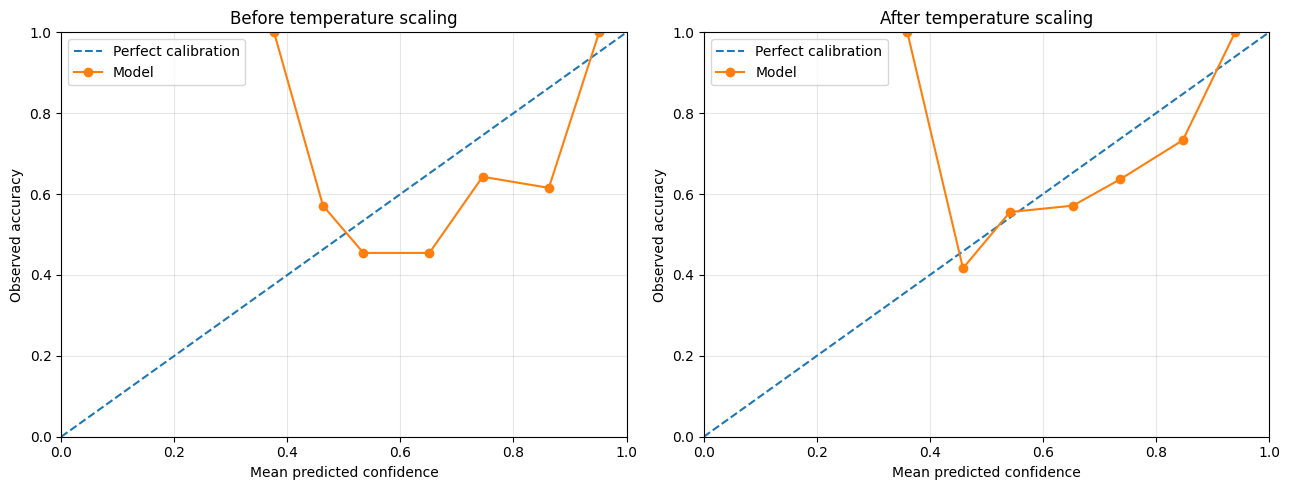

Calibration metrics and reliability plots saved.


In [81]:
# CELL 69 — ECE, multiclass Brier score, and reliability diagrams

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import accuracy_score, log_loss

# Reuse probabilities and labels from Cell 68.
y_true_cal = np.asarray(y_cal)
p_uncalibrated = np.asarray(probs_before)
p_calibrated = np.asarray(probs_after)

assert p_uncalibrated.shape == p_calibrated.shape
assert p_uncalibrated.shape[0] == len(y_true_cal)
assert np.allclose(p_uncalibrated.sum(axis=1), 1.0, atol=1e-5)
assert np.allclose(p_calibrated.sum(axis=1), 1.0, atol=1e-5)


# ------------------------------------------------------------
# 1. Calculate top-label ECE and multiclass Brier score
# ------------------------------------------------------------
def calibration_metrics(y_true, probs, n_bins=10):
    n_classes = probs.shape[1]
    predictions = np.argmax(probs, axis=1)
    confidence = np.max(probs, axis=1)
    correctness = (predictions == y_true).astype(float)

    # Equal-width bins over [0, 1].
    bin_edges = np.linspace(0.0, 1.0, n_bins + 1)
    ece = 0.0
    bin_rows = []

    for i in range(n_bins):
        # Include confidence=1.0 in the last bin.
        if i == n_bins - 1:
            mask = (
                (confidence >= bin_edges[i])
                & (confidence <= bin_edges[i + 1])
            )
        else:
            mask = (
                (confidence >= bin_edges[i])
                & (confidence < bin_edges[i + 1])
            )

        count = int(mask.sum())

        if count > 0:
            mean_conf = float(confidence[mask].mean())
            observed_accuracy = float(correctness[mask].mean())

            ece += (count / len(y_true)) * abs(
                mean_conf - observed_accuracy
            )
        else:
            mean_conf = np.nan
            observed_accuracy = np.nan

        bin_rows.append({
            "confidence_interval":
                f"{bin_edges[i]:.1f}-{bin_edges[i + 1]:.1f}",
            "count": count,
            "mean_confidence": mean_conf,
            "accuracy": observed_accuracy,
        })

    # Multiclass Brier score: mean sum of squared class-probability errors.
    one_hot = np.eye(n_classes)[y_true]
    brier = np.mean(np.sum((probs - one_hot) ** 2, axis=1))

    return {
        "accuracy": accuracy_score(y_true, predictions),
        "NLL": log_loss(
            y_true, probs, labels=list(range(n_classes))
        ),
        "multiclass_Brier": brier,
        "top_label_ECE": ece,
    }, pd.DataFrame(bin_rows)


metrics_before, bins_before = calibration_metrics(
    y_true_cal, p_uncalibrated
)
metrics_after, bins_after = calibration_metrics(
    y_true_cal, p_calibrated
)

calibration_results = pd.DataFrame([
    {"method": "Before calibration", **metrics_before},
    {"method": "After temperature scaling", **metrics_after},
])

display(calibration_results.round(5))

calibration_results.to_csv(
    RESULTS_DIR / "calibration_metrics_comparison.csv",
    index=False,
)

bins_before.to_csv(
    RESULTS_DIR / "reliability_bins_before.csv",
    index=False,
)
bins_after.to_csv(
    RESULTS_DIR / "reliability_bins_after.csv",
    index=False,
)


# ------------------------------------------------------------
# 2. Plot reliability diagrams
# ------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, bin_df, title in [
    (axes[0], bins_before, "Before temperature scaling"),
    (axes[1], bins_after, "After temperature scaling"),
]:
    ax.plot(
        [0, 1], [0, 1],
        linestyle="--",
        label="Perfect calibration",
    )

    valid = bin_df["count"] > 0

    ax.plot(
        bin_df.loc[valid, "mean_confidence"],
        bin_df.loc[valid, "accuracy"],
        marker="o",
        label="Model",
    )

    ax.set_xlabel("Mean predicted confidence")
    ax.set_ylabel("Observed accuracy")
    ax.set_title(title)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.grid(True, alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.savefig(
    RESULTS_DIR / "reliability_before_after.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()

print("Calibration metrics and reliability plots saved.")

In [82]:
# CELL 70 — Save final model weights and calibration configuration

import torch
import json

FINAL_MODEL_PATH = CHECKPOINT_DIR / "dr_convnext_calibrated.pth"
FINAL_CONFIG_PATH = RESULTS_DIR / "dr_model_config.json"

# selected_model and selected_name were defined in Cell 64.
# temperature was learned using validation data in Cell 68.
assert selected_model is not None
assert temperature > 0

final_state_dict = {
    key: value.detach().cpu()
    for key, value in selected_model.state_dict().items()
}

torch.save(
    {
        "model_name": "convnext_tiny",
        "selected_candidate": selected_name,
        "model_state_dict": final_state_dict,
        "temperature": float(temperature),
        "num_classes": NUM_CLASSES,
        "image_size": IMAGE_SIZE,
        "class_names": CLASS_NAMES,
        "use_tta": bool(selected_use_tta),
    },
    FINAL_MODEL_PATH,
)

config = {
    "model_name": "convnext_tiny",
    "selected_candidate": selected_name,
    "temperature": float(temperature),
    "num_classes": int(NUM_CLASSES),
    "image_size": int(IMAGE_SIZE),
    "class_names": CLASS_NAMES,
    "use_tta": bool(selected_use_tta),
    "validation_accuracy": float(metrics_after["accuracy"]),
    "validation_nll_after_calibration": float(metrics_after["NLL"]),
    "validation_brier_after_calibration": float(
        metrics_after["multiclass_Brier"]
    ),
    "validation_ece_after_calibration": float(
        metrics_after["top_label_ECE"]
    ),
}

FINAL_CONFIG_PATH.write_text(json.dumps(config, indent=4))

print("Calibrated model saved:", FINAL_MODEL_PATH)
print("Model configuration saved:", FINAL_CONFIG_PATH)

Calibrated model saved: /kaggle/working/DR_Project/checkpoints/dr_convnext_calibrated.pth
Model configuration saved: /kaggle/working/DR_Project/results/dr_model_config.json


In [83]:
# CELL 71 — Verify saved calibrated inference

saved = torch.load(
    FINAL_MODEL_PATH,
    map_location="cpu",
    weights_only=True,
)

verification_model = build_model(
    saved["model_name"],
    pretrained=False,
).to(DEVICE)

verification_model.load_state_dict(
    saved["model_state_dict"],
    strict=True,
)
verification_model.eval()

temperature_saved = float(saved["temperature"])

# Get logits using the saved model and the configured TTA setting.
logits_list = []
labels_list = []

with torch.inference_mode():
    for images, labels in val_loader:
        images = images.to(DEVICE, non_blocking=True)

        with autocast_context():
            logits = verification_model(images)

            if saved["use_tta"]:
                flipped_logits = verification_model(
                    torch.flip(images, dims=[3])
                )
                logits = (logits.float() + flipped_logits.float()) / 2.0

        logits_list.append(logits.float().cpu())
        labels_list.append(labels.cpu())

verification_logits = torch.cat(logits_list, dim=0)
verification_labels = torch.cat(labels_list, dim=0).numpy()

# Apply temperature scaling to the final logits.
verification_probs = torch.softmax(
    verification_logits / temperature_saved,
    dim=1,
).numpy()

assert np.isfinite(verification_probs).all()
assert np.allclose(
    verification_probs.sum(axis=1), 1.0, atol=1e-5
)

verification_predictions = verification_probs.argmax(axis=1)

print("Saved-model validation accuracy:",
      round(accuracy_score(
          verification_labels, verification_predictions
      ), 5))

print("Probability range:",
      float(verification_probs.min()),
      "to",
      float(verification_probs.max()))

print("All probability rows sum to approximately 1.")

Saved-model validation accuracy: 0.69512
Probability range: 0.0005160821019671857 to 0.9835426807403564
All probability rows sum to approximately 1.


In [84]:
# CELL 72 — Refit calibration for the selected inference pipeline

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

from sklearn.metrics import log_loss

calibration_model = selected_model
calibration_model.eval()

# Collect probabilities using exactly the selected TTA setting.
y_cal_final, p_cal_raw = predict_probabilities(
    calibration_model,
    val_loader,
    use_tta=selected_use_tta,
)

assert p_cal_raw.shape == (len(y_cal_final), NUM_CLASSES)
assert np.isfinite(p_cal_raw).all()
assert np.allclose(p_cal_raw.sum(axis=1), 1.0, atol=1e-5)

# Convert probabilities to log-probabilities.
# This allows calibration after TTA probability averaging.
prob_tensor = torch.tensor(
    p_cal_raw,
    dtype=torch.float64,
)

log_prob_tensor = torch.log(
    prob_tensor.clamp(min=1e-12)
)

target_tensor = torch.tensor(
    y_cal_final,
    dtype=torch.long,
)

# Learn a single positive temperature using validation NLL.
log_temp_final = torch.nn.Parameter(
    torch.zeros((), dtype=torch.float64)
)

optimizer_final = torch.optim.LBFGS(
    [log_temp_final],
    lr=0.1,
    max_iter=100,
    line_search_fn="strong_wolfe",
)

def calibration_closure():
    optimizer_final.zero_grad()

    temp = torch.exp(log_temp_final).clamp(
        min=0.05,
        max=20.0,
    )

    calibrated_log_probs = F.log_softmax(
        log_prob_tensor / temp,
        dim=1,
    )

    loss = F.nll_loss(
        calibrated_log_probs,
        target_tensor,
    )

    loss.backward()
    return loss

optimizer_final.step(calibration_closure)

final_temperature = float(
    torch.exp(log_temp_final.detach()).clamp(
        min=0.05,
        max=20.0,
    ).item()
)

# Apply calibration to the same validation probabilities.
p_cal_final = torch.softmax(
    log_prob_tensor / final_temperature,
    dim=1,
).numpy()

nll_before_final = log_loss(
    y_cal_final,
    p_cal_raw,
    labels=list(range(NUM_CLASSES)),
)

nll_after_final = log_loss(
    y_cal_final,
    p_cal_final,
    labels=list(range(NUM_CLASSES)),
)

final_calibration_summary = pd.DataFrame([
    {
        "pipeline": "Selected model before calibration",
        "temperature": 1.0,
        "validation_NLL": nll_before_final,
    },
    {
        "pipeline": "Selected model after calibration",
        "temperature": final_temperature,
        "validation_NLL": nll_after_final,
    },
])

display(final_calibration_summary.round(5))

final_calibration_summary.to_csv(
    RESULTS_DIR / "final_pipeline_calibration.csv",
    index=False,
)

# Save the temperature associated with this exact inference pipeline.
FINAL_TEMPERATURE_PATH = (
    RESULTS_DIR / "final_pipeline_temperature.txt"
)

FINAL_TEMPERATURE_PATH.write_text(
    str(final_temperature)
)

print("Selected model:", selected_name)
print("TTA enabled:", selected_use_tta)
print("Final calibration temperature:", round(final_temperature, 5))
print("Before-calibration NLL:", round(nll_before_final, 5))
print("After-calibration NLL:", round(nll_after_final, 5))
print("Saved:", FINAL_TEMPERATURE_PATH)

,pipeline,temperature,validation_NLL
0,Selected model before calibration,1.0000,0.74409
1,Selected model after calibration,1.1381,0.73825


Selected model: Balanced fine-tuned ConvNeXt-Tiny
TTA enabled: False
Final calibration temperature: 1.1381
Before-calibration NLL: 0.74409
After-calibration NLL: 0.73825
Saved: /kaggle/working/DR_Project/results/final_pipeline_temperature.txt


,model,tta_enabled,temperature,test_samples,accuracy,macro_f1,qwk,nll,multiclass_brier
0,Balanced fine-tuned ConvNeXt-Tiny,False,1.1381,103,0.5534,0.40449,0.65051,1.11902,0.59284


                  precision    recall  f1-score   support

           No DR     0.7105    0.7941    0.7500        34
            Mild     0.0000    0.0000    0.0000         5
        Moderate     0.5385    0.6562    0.5915        32
          Severe     0.5000    0.2105    0.2963        19
Proliferative DR     0.3846    0.3846    0.3846        13

        accuracy                         0.5534       103
       macro avg     0.4267    0.4091    0.4045       103
    weighted avg     0.5426    0.5534    0.5346       103



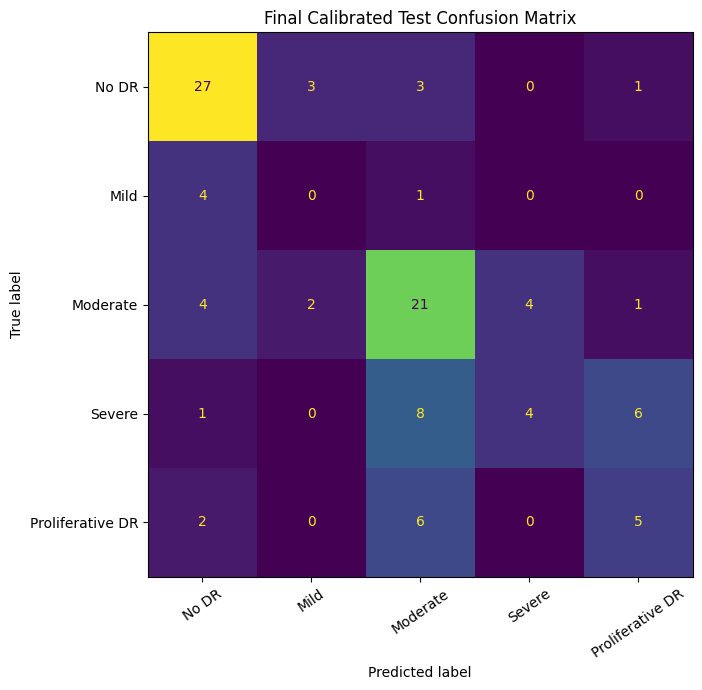

Final test results saved to: /kaggle/working/DR_Project/results


In [85]:
# CELL 73 — Final calibrated test evaluation
# Run only after all model and inference choices are finalized.

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    cohen_kappa_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    log_loss,
)

# 1. Validate final configuration
assert "selected_model" in globals()
assert "selected_use_tta" in globals()
assert "final_temperature" in globals()
assert final_temperature > 0

# 2. Generate raw test probabilities using the finalized pipeline
y_test_final, p_test_raw = predict_probabilities(
    selected_model,
    test_loader,
    use_tta=selected_use_tta,
)

assert p_test_raw.shape == (len(y_test_final), NUM_CLASSES)
assert np.isfinite(p_test_raw).all()
assert np.allclose(p_test_raw.sum(axis=1), 1.0, atol=1e-5)

# 3. Apply temperature scaling consistently
p_test_final = torch.softmax(
    torch.log(
        torch.tensor(p_test_raw, dtype=torch.float64).clamp(min=1e-12)
    ) / final_temperature,
    dim=1,
).numpy()

test_predictions = p_test_final.argmax(axis=1)

# 4. Calculate final metrics
test_accuracy = accuracy_score(y_test_final, test_predictions)
test_macro_f1 = f1_score(
    y_test_final,
    test_predictions,
    average="macro",
    zero_division=0,
)
test_qwk = cohen_kappa_score(
    y_test_final,
    test_predictions,
    weights="quadratic",
)
test_nll = log_loss(
    y_test_final,
    p_test_final,
    labels=list(range(NUM_CLASSES)),
)

one_hot_test = np.eye(NUM_CLASSES)[y_test_final]
test_brier = np.mean(
    np.sum((p_test_final - one_hot_test) ** 2, axis=1)
)

test_metrics_final = {
    "model": selected_name,
    "tta_enabled": selected_use_tta,
    "temperature": final_temperature,
    "test_samples": len(y_test_final),
    "accuracy": test_accuracy,
    "macro_f1": test_macro_f1,
    "qwk": test_qwk,
    "nll": test_nll,
    "multiclass_brier": test_brier,
}

display(pd.DataFrame([test_metrics_final]).round(5))

# 5. Class-wise report
print(
    classification_report(
        y_test_final,
        test_predictions,
        labels=list(range(NUM_CLASSES)),
        target_names=CLASS_NAMES,
        digits=4,
        zero_division=0,
    )
)

# 6. Confusion matrix
cm_test = confusion_matrix(
    y_test_final,
    test_predictions,
    labels=list(range(NUM_CLASSES)),
)

fig, ax = plt.subplots(figsize=(9, 7))
ConfusionMatrixDisplay(
    confusion_matrix=cm_test,
    display_labels=CLASS_NAMES,
).plot(
    ax=ax,
    values_format="d",
    xticks_rotation=35,
    colorbar=False,
)

ax.set_title("Final Calibrated Test Confusion Matrix")
plt.tight_layout()
plt.savefig(
    RESULTS_DIR / "final_test_confusion_matrix.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()

# 7. Save results
pd.DataFrame([test_metrics_final]).to_csv(
    RESULTS_DIR / "final_calibrated_test_metrics.csv",
    index=False,
)

pd.DataFrame(
    cm_test,
    index=[f"True_{name}" for name in CLASS_NAMES],
    columns=[f"Pred_{name}" for name in CLASS_NAMES],
).to_csv(
    RESULTS_DIR / "final_calibrated_test_confusion_matrix.csv"
)

print("Final test results saved to:", RESULTS_DIR)

In [118]:
# FINAL CELL — SAVE MODEL + CREATE WEBSITE DEPLOYMENT BUNDLE

from pathlib import Path
import json
import shutil
import zipfile
import torch

# --------------------------------------------------
# 1. Check that the final model is available
# --------------------------------------------------
assert "selected_model" in globals(), (
    "Run the model-selection cells first."
)
assert "selected_use_tta" in globals(), (
    "Run the final model-selection cell first."
)
assert "final_temperature" in globals(), (
    "Run the final calibration cell first."
)
assert float(final_temperature) > 0

PROJECT_DIR = Path("/kaggle/working/DR_Project")
DEPLOY_DIR = PROJECT_DIR / "deployment"
MODEL_DIR = DEPLOY_DIR / "models"

MODEL_DIR.mkdir(parents=True, exist_ok=True)

MODEL_PATH = MODEL_DIR / "dr_convnext_tiny_weights.pth"
CONFIG_PATH = MODEL_DIR / "model_config.json"

CLASS_NAMES = {
    0: "No DR",
    1: "Mild",
    2: "Moderate",
    3: "Severe",
    4: "Proliferative DR",
}

# --------------------------------------------------
# 2. Save the exact selected model weights
# --------------------------------------------------
state_dict_cpu = {
    key: value.detach().cpu()
    for key, value in selected_model.state_dict().items()
}

checkpoint = {
    "architecture": "torchvision_convnext_tiny",
    "model_state_dict": state_dict_cpu,
    "num_classes": 5,
    "image_size": 224,
    "class_names": CLASS_NAMES,
    "temperature": float(final_temperature),
    "use_tta": bool(selected_use_tta),
    "selected_candidate": str(
        globals().get("selected_name", "ConvNeXt-Tiny")
    ),
}

torch.save(checkpoint, MODEL_PATH)

# --------------------------------------------------
# 3. Save the inference configuration
# --------------------------------------------------
config = {
    "architecture": "torchvision_convnext_tiny",
    "num_classes": 5,
    "image_size": 224,
    "class_names": CLASS_NAMES,
    "temperature": float(final_temperature),
    "use_tta": bool(selected_use_tta),
    "normalization_mean": [0.485, 0.456, 0.406],
    "normalization_std": [0.229, 0.224, 0.225],
    "preprocessing": "Resize to 224x224, RGB, ImageNet normalization",
}

CONFIG_PATH.write_text(json.dumps(config, indent=2))

# --------------------------------------------------
# 4. Create requirements.txt
# --------------------------------------------------
requirements = """streamlit
torch
torchvision
Pillow
numpy
"""

(DEPLOY_DIR / "requirements.txt").write_text(requirements)

# --------------------------------------------------
# 5. Create app.py
# --------------------------------------------------
app_code = r'''
import json
from pathlib import Path

import numpy as np
import streamlit as st
import torch
import torch.nn.functional as F
from PIL import Image, ImageOps
from torchvision import models, transforms
from torch import nn

BASE_DIR = Path(__file__).resolve().parent
MODEL_PATH = BASE_DIR / "models" / "dr_convnext_tiny_weights.pth"
CONFIG_PATH = BASE_DIR / "models" / "model_config.json"

st.set_page_config(
    page_title="DR Vision AI",
    page_icon="👁️",
    layout="centered",
)

CLASS_NAMES = [
    "No DR",
    "Mild",
    "Moderate",
    "Severe",
    "Proliferative DR",
]

@st.cache_resource
def load_model():
    if not MODEL_PATH.exists() or not CONFIG_PATH.exists():
        raise FileNotFoundError(
            "Model files are missing. Check the models/ folder."
        )

    config = json.loads(CONFIG_PATH.read_text())
    device = torch.device(
        "cuda" if torch.cuda.is_available() else "cpu"
    )

    # Match the architecture used in the training notebook.
    model = models.convnext_tiny(weights=None)
    in_features = model.classifier[2].in_features
    model.classifier[2] = nn.Linear(in_features, 5)

    try:
        checkpoint = torch.load(
            MODEL_PATH,
            map_location="cpu",
            weights_only=True,
        )
    except TypeError:
        checkpoint = torch.load(MODEL_PATH, map_location="cpu")

    model.load_state_dict(checkpoint["model_state_dict"], strict=True)
    model.to(device).eval()

    return model, config, device

def prepare_image(image, size):
    image = ImageOps.exif_transpose(image).convert("RGB")

    # Must match the notebook's evaluation transform.
    transform = transforms.Compose([
        transforms.Resize((size, size)),
        transforms.ToTensor(),
        transforms.Normalize(
            mean=[0.485, 0.456, 0.406],
            std=[0.229, 0.224, 0.225],
        ),
    ])
    return transform(image).unsqueeze(0)

def predict(image, model, config, device):
    x = prepare_image(image, int(config["image_size"])).to(device)
    temperature = max(float(config["temperature"]), 1e-6)

    with torch.inference_mode():
        # Original image probabilities
        probs = torch.softmax(model(x).float(), dim=1)

        # Match notebook TTA: average probabilities before calibration.
        if bool(config.get("use_tta", False)):
            flipped = torch.flip(x, dims=[3])
            flipped_probs = torch.softmax(
                model(flipped).float(), dim=1
            )
            probs = (probs + flipped_probs) / 2.0

        # Match the notebook's final probability calibration.
        calibrated = torch.softmax(
            torch.log(probs.clamp(min=1e-12)) / temperature,
            dim=1,
        )[0]

    scores = calibrated.cpu().numpy()
    predicted_index = int(np.argmax(scores))
    return CLASS_NAMES[predicted_index], scores

st.title("👁️ DR Vision AI")
st.subheader("Diabetic Retinopathy Severity Classification")

st.write(
    "Upload a retinal fundus image to view the model's "
    "experimental five-class severity prediction."
)

st.warning(
    "Research prototype only. Not for medical diagnosis or "
    "treatment decisions. Consult a qualified eye-care professional."
)

uploaded = st.file_uploader(
    "Choose a retinal fundus image",
    type=["jpg", "jpeg", "png"],
)

if uploaded is not None:
    try:
        image = Image.open(uploaded)
        image = ImageOps.exif_transpose(image).convert("RGB")
        st.image(image, caption="Uploaded image", use_container_width=True)

        if st.button("Analyze image", type="primary"):
            with st.spinner("Running model..."):
                model, config, device = load_model()
                predicted_class, scores = predict(
                    image, model, config, device
                )

            st.subheader("Prediction")
            st.success(f"Predicted class: {predicted_class}")

            st.write("Class probability scores")
            for label, score in zip(CLASS_NAMES, scores):
                st.write(f"**{label}: {score:.1%}**")
                st.progress(float(score))

            st.caption(
                "Scores represent model outputs, not guaranteed "
                "clinical probabilities or diagnostic certainty."
            )

    except Exception as error:
        st.error(f"Prediction failed: {error}")

st.divider()
st.caption(
    "ConvNeXt-Tiny | Five-class DR research prototype"
)
'''

(DEPLOY_DIR / "app.py").write_text(app_code)

# --------------------------------------------------
# 6. Verify saved model can be loaded
# --------------------------------------------------
saved = torch.load(
    MODEL_PATH,
    map_location="cpu",
    weights_only=True,
)

assert saved["num_classes"] == 5
assert len(saved["model_state_dict"]) > 0
assert saved["temperature"] > 0

print("MODEL AND WEBSITE FILES SAVED")
print("Selected model:", checkpoint["selected_candidate"])
print("TTA enabled:", checkpoint["use_tta"])
print("Calibration temperature:", checkpoint["temperature"])
print("Model file size (MB):", round(MODEL_PATH.stat().st_size / 1e6, 2))
print("Deployment folder:", DEPLOY_DIR)

# --------------------------------------------------
# 7. Zip everything for download
# --------------------------------------------------
ZIP_PATH = PROJECT_DIR / "DR_Vision_AI_Deployment.zip"

with zipfile.ZipFile(
    ZIP_PATH, "w", compression=zipfile.ZIP_DEFLATED
) as zf:
    for file in DEPLOY_DIR.rglob("*"):
        if file.is_file():
            zf.write(file, file.relative_to(PROJECT_DIR))

print("\nDeployment ZIP created:", ZIP_PATH)
print("In Kaggle, open the Output/Files panel to download it.")

MODEL AND WEBSITE FILES SAVED
Selected model: Balanced fine-tuned ConvNeXt-Tiny
TTA enabled: False
Calibration temperature: 1.1381041910876293
Model file size (MB): 111.35
Deployment folder: /kaggle/working/DR_Project/deployment

Deployment ZIP created: /kaggle/working/DR_Project/DR_Vision_AI_Deployment.zip
In Kaggle, open the Output/Files panel to download it.


Test top-label ECE (10 bins): 0.13470


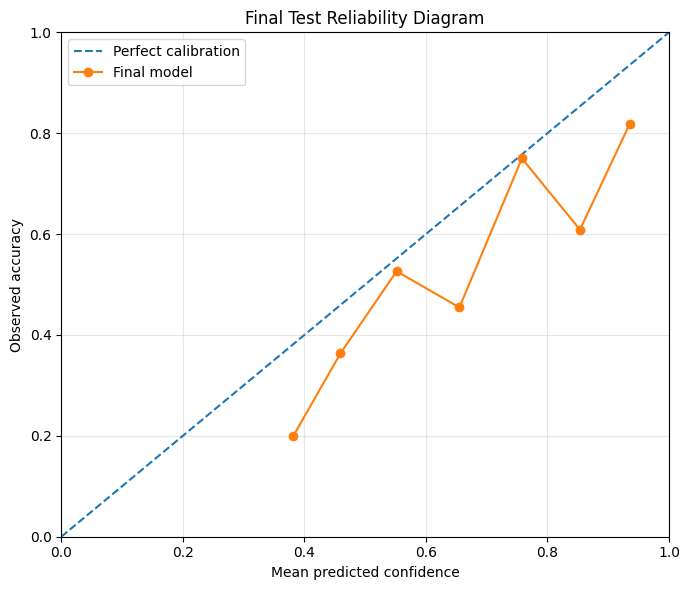

In [86]:
# CELL 74 — Final test calibration analysis

def calculate_top_label_ece(y_true, probs, n_bins=10):
    y_true = np.asarray(y_true)
    confidence = probs.max(axis=1)
    predicted = probs.argmax(axis=1)
    correct = (predicted == y_true).astype(float)

    edges = np.linspace(0.0, 1.0, n_bins + 1)
    ece = 0.0
    rows = []

    for i in range(n_bins):
        if i == n_bins - 1:
            mask = (
                (confidence >= edges[i])
                & (confidence <= edges[i + 1])
            )
        else:
            mask = (
                (confidence >= edges[i])
                & (confidence < edges[i + 1])
            )

        count = int(mask.sum())

        if count:
            mean_conf = float(confidence[mask].mean())
            accuracy_bin = float(correct[mask].mean())

            ece += (
                count / len(y_true)
            ) * abs(mean_conf - accuracy_bin)
        else:
            mean_conf = np.nan
            accuracy_bin = np.nan

        rows.append({
            "bin": f"{edges[i]:.1f}-{edges[i + 1]:.1f}",
            "count": count,
            "mean_confidence": mean_conf,
            "observed_accuracy": accuracy_bin,
        })

    return ece, pd.DataFrame(rows)


test_ece, test_reliability_bins = calculate_top_label_ece(
    y_test_final,
    p_test_final,
    n_bins=10,
)

print(f"Test top-label ECE (10 bins): {test_ece:.5f}")

test_reliability_bins.to_csv(
    RESULTS_DIR / "final_test_reliability_bins.csv",
    index=False,
)

# Plot the test reliability diagram.
valid_bins = test_reliability_bins["count"] > 0

plt.figure(figsize=(7, 6))
plt.plot(
    [0, 1], [0, 1],
    linestyle="--",
    label="Perfect calibration",
)
plt.plot(
    test_reliability_bins.loc[valid_bins, "mean_confidence"],
    test_reliability_bins.loc[valid_bins, "observed_accuracy"],
    marker="o",
    label="Final model",
)

plt.xlabel("Mean predicted confidence")
plt.ylabel("Observed accuracy")
plt.title("Final Test Reliability Diagram")
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "final_test_reliability_diagram.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()

In [87]:
# CELL 75 — Bootstrap 95% confidence interval for test accuracy

# Fixed seed for reproducibility.
rng = np.random.default_rng(SEED)

n_test = len(y_test_final)
n_bootstrap = 5000

bootstrap_accuracies = np.empty(n_bootstrap)

for b in range(n_bootstrap):
    indices = rng.integers(0, n_test, size=n_test)

    bootstrap_accuracies[b] = accuracy_score(
        y_test_final[indices],
        test_predictions[indices],
    )

ci_lower, ci_upper = np.percentile(
    bootstrap_accuracies,
    [2.5, 97.5],
)

print(f"Test accuracy: {test_accuracy:.4f}")
print(
    "Bootstrap 95% confidence interval: "
    f"[{ci_lower:.4f}, {ci_upper:.4f}]"
)

bootstrap_summary = pd.DataFrame([{
    "test_samples": n_test,
    "accuracy": test_accuracy,
    "ci_95_lower": ci_lower,
    "ci_95_upper": ci_upper,
    "bootstrap_repetitions": n_bootstrap,
}])

bootstrap_summary.to_csv(
    RESULTS_DIR / "test_accuracy_confidence_interval.csv",
    index=False,
)

display(bootstrap_summary.round(4))

Test accuracy: 0.5534
Bootstrap 95% confidence interval: [0.4563, 0.6505]


,test_samples,accuracy,ci_95_lower,ci_95_upper,bootstrap_repetitions
0,103,0.5534,0.4563,0.6505,5000


In [88]:
# CELL 76 — Consolidated research metrics table

import pandas as pd
import numpy as np

# Verify the required results exist from Cells 62–75.
required_variables = [
    "comparison",
    "test_metrics_final",
    "test_ece",
    "ci_lower",
    "ci_upper",
]

for variable in required_variables:
    assert variable in globals(), (
        f"Missing variable: {variable}. Run the corresponding cell first."
    )

# Validation comparison: original, balanced, and TTA models.
validation_table = comparison.copy()
validation_table = validation_table.rename(columns={
    "accuracy": "validation_accuracy",
    "macro_f1": "validation_macro_f1",
    "qwk": "validation_qwk",
})

# Final test metrics, including calibration.
test_row = {
    "selected_model": test_metrics_final["model"],
    "test_samples": test_metrics_final["test_samples"],
    "test_accuracy": test_metrics_final["accuracy"],
    "test_macro_f1": test_metrics_final["macro_f1"],
    "test_qwk": test_metrics_final["qwk"],
    "test_nll": test_metrics_final["nll"],
    "test_brier": test_metrics_final["multiclass_brier"],
    "test_ece_10_bins": test_ece,
    "test_accuracy_ci95_lower": ci_lower,
    "test_accuracy_ci95_upper": ci_upper,
}

research_results = pd.DataFrame([test_row])

display(validation_table.round(4))
display(research_results.round(4))

validation_table.to_csv(
    RESULTS_DIR / "research_validation_comparison.csv",
    index=False,
)

research_results.to_csv(
    RESULTS_DIR / "research_final_test_results.csv",
    index=False,
)

print("Research tables saved in:", RESULTS_DIR)

,model,validation_accuracy,validation_macro_f1,validation_qwk
0,Balanced fine-tuned ConvNeXt-Tiny,0.6951,0.5374,0.8416
1,Original ConvNeXt-Tiny,0.6829,0.5964,0.8459
2,Balanced ConvNeXt-Tiny + TTA,0.6707,0.5080,0.8192


,selected_model,test_samples,test_accuracy,test_macro_f1,test_qwk,test_nll,test_brier,test_ece_10_bins,test_accuracy_ci95_lower,test_accuracy_ci95_upper
0,Balanced fine-tuned ConvNeXt-Tiny,103,0.5534,0.4045,0.6505,1.119,0.5928,0.1347,0.4563,0.6505


Research tables saved in: /kaggle/working/DR_Project/results


In [89]:
# CELL 77 — Ablation-study summary from measured results

ablation_rows = []

# Original model
row = comparison.loc[
    comparison["model"] == "Original ConvNeXt-Tiny"
]
if not row.empty:
    r = row.iloc[0]
    ablation_rows.append({
        "experiment": "Original ConvNeXt-Tiny",
        "balanced_sampling": False,
        "tta": False,
        "validation_accuracy": r["accuracy"],
        "validation_macro_f1": r["macro_f1"],
        "validation_qwk": r["qwk"],
    })

# Balanced fine-tuned model
row = comparison.loc[
    comparison["model"] == "Balanced fine-tuned ConvNeXt-Tiny"
]
if not row.empty:
    r = row.iloc[0]
    ablation_rows.append({
        "experiment": "Balanced fine-tuned ConvNeXt-Tiny",
        "balanced_sampling": True,
        "tta": False,
        "validation_accuracy": r["accuracy"],
        "validation_macro_f1": r["macro_f1"],
        "validation_qwk": r["qwk"],
    })

# Balanced model with test-time augmentation
row = comparison.loc[
    comparison["model"] == "Balanced ConvNeXt-Tiny + TTA"
]
if not row.empty:
    r = row.iloc[0]
    ablation_rows.append({
        "experiment": "Balanced ConvNeXt-Tiny + TTA",
        "balanced_sampling": True,
        "tta": True,
        "validation_accuracy": r["accuracy"],
        "validation_macro_f1": r["macro_f1"],
        "validation_qwk": r["qwk"],
    })

ablation_table = pd.DataFrame(ablation_rows)
display(ablation_table.round(4))

ablation_table.to_csv(
    RESULTS_DIR / "ablation_study_summary.csv",
    index=False,
)

print("Ablation summary saved.")

,experiment,balanced_sampling,tta,validation_accuracy,validation_macro_f1,validation_qwk
0,Original ConvNeXt-Tiny,False,False,0.6829,0.5964,0.8459
1,Balanced fine-tuned ConvNeXt-Tiny,True,False,0.6951,0.5374,0.8416
2,Balanced ConvNeXt-Tiny + TTA,True,True,0.6707,0.5080,0.8192


Ablation summary saved.


In [90]:
# CELL 78 — Package project outputs

import zipfile
from pathlib import Path

PACKAGE_PATH = Path("/kaggle/working/DR_research_results.zip")

folders_to_package = [
    RESULTS_DIR,
    CHECKPOINT_DIR,
]

with zipfile.ZipFile(
    PACKAGE_PATH,
    mode="w",
    compression=zipfile.ZIP_DEFLATED,
) as archive:

    for folder in folders_to_package:
        if folder.exists():
            for file_path in folder.rglob("*"):
                if file_path.is_file():
                    archive.write(
                        file_path,
                        arcname=str(
                            Path(folder.name) / file_path.relative_to(folder)
                        ),
                    )

print("Research package created:", PACKAGE_PATH)
print(f"Package size: {PACKAGE_PATH.stat().st_size / (1024**2):.2f} MB")

Research package created: /kaggle/working/DR_research_results.zip
Package size: 492.39 MB


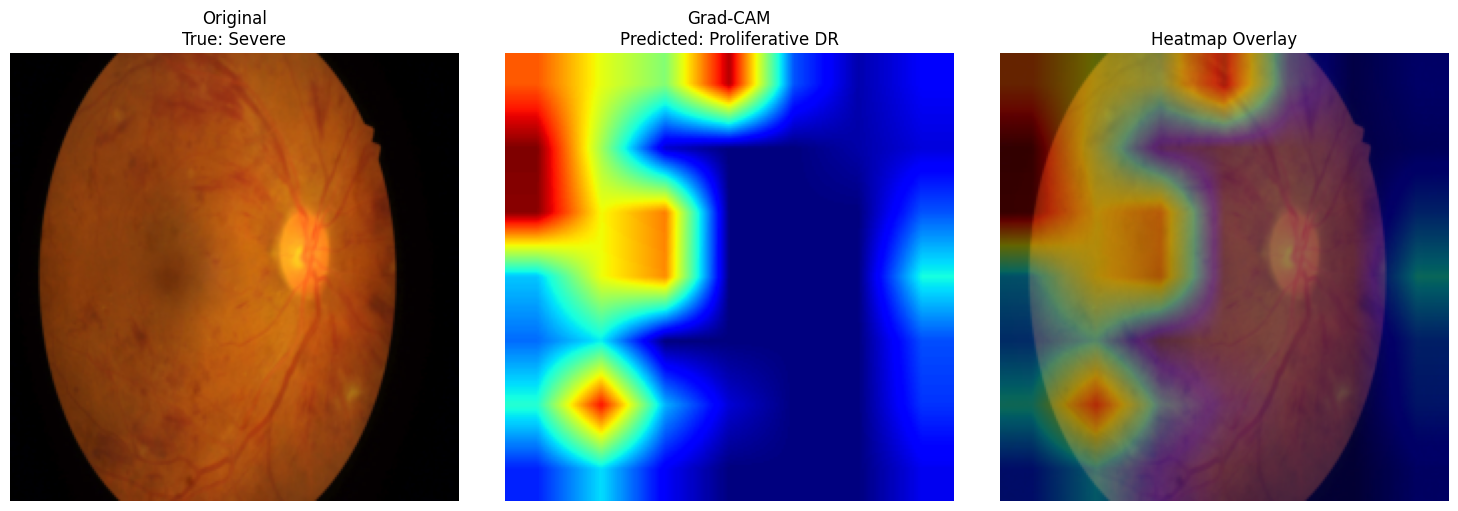

True class: Severe
Predicted class: Proliferative DR
Grad-CAM saved to: /kaggle/working/DR_Project/results/gradcam_validation_example.png


In [91]:
# CELL 79 — Grad-CAM for ConvNeXt-Tiny

import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

# Select the model chosen using validation results.
gradcam_model = selected_model
gradcam_model.eval()

# For torchvision ConvNeXt-Tiny, the final feature block is
# model.features[-1], before global pooling and classification.
target_layer = gradcam_model.features[-1]

activations = {}
gradients = {}

def save_activations(module, inputs, output):
    activations["value"] = output

def save_gradients(module, grad_input, grad_output):
    gradients["value"] = grad_output[0]

activation_hook = target_layer.register_forward_hook(save_activations)
gradient_hook = target_layer.register_full_backward_hook(save_gradients)

try:
    # Take one validation batch.
    images, labels = next(iter(val_loader))

    # Choose one image by its batch index.
    image_index = 0
    image = images[image_index:image_index + 1].to(DEVICE)
    true_label = int(labels[image_index].item())

    gradcam_model.zero_grad(set_to_none=True)

    # Forward pass
    with autocast_context():
        logits = gradcam_model(image)

    predicted_label = int(logits.argmax(dim=1).item())

    # Backpropagate the predicted class score.
    score = logits[0, predicted_label]
    score.backward()

    feature_maps = activations["value"]
    feature_gradients = gradients["value"]

    # Grad-CAM channel weights: average gradients over spatial dimensions.
    weights = feature_gradients.mean(dim=(2, 3), keepdim=True)

    cam = (weights * feature_maps).sum(dim=1, keepdim=True)
    cam = F.relu(cam)

    cam = F.interpolate(
        cam,
        size=(IMAGE_SIZE, IMAGE_SIZE),
        mode="bilinear",
        align_corners=False,
    )

    cam = cam[0, 0].detach().float().cpu().numpy()

    # Normalize heatmap.
    cam = cam - cam.min()
    if cam.max() > 1e-8:
        cam = cam / cam.max()

    # Reverse ImageNet normalization for display.
    mean = torch.tensor(
        [0.485, 0.456, 0.406],
        device=image.device,
    ).view(1, 3, 1, 1)

    std = torch.tensor(
        [0.229, 0.224, 0.225],
        device=image.device,
    ).view(1, 3, 1, 1)

    display_image = (
        image * std + mean
    ).clamp(0, 1)[0].permute(1, 2, 0).detach().cpu().numpy()

    # Display original image, heatmap, and overlay.
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))

    axes[0].imshow(display_image)
    axes[0].set_title(
        f"Original\nTrue: {CLASS_NAMES[true_label]}"
    )

    axes[1].imshow(cam, cmap="jet", vmin=0, vmax=1)
    axes[1].set_title(
        f"Grad-CAM\nPredicted: {CLASS_NAMES[predicted_label]}"
    )

    axes[2].imshow(display_image)
    axes[2].imshow(
        cam,
        cmap="jet",
        alpha=0.4,
        vmin=0,
        vmax=1,
    )
    axes[2].set_title("Heatmap Overlay")

    for ax in axes:
        ax.axis("off")

    plt.tight_layout()

    gradcam_path = RESULTS_DIR / "gradcam_validation_example.png"
    plt.savefig(gradcam_path, dpi=200, bbox_inches="tight")
    plt.show()

    print("True class:", CLASS_NAMES[true_label])
    print("Predicted class:", CLASS_NAMES[predicted_label])
    print("Grad-CAM saved to:", gradcam_path)

finally:
    # Remove hooks to avoid retaining them during later evaluation.
    activation_hook.remove()
    gradient_hook.remove()
    gradcam_model.zero_grad(set_to_none=True)

In [92]:
# CELL 80 — Systematic validation error analysis

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import confusion_matrix

# Use validation probabilities from Cell 62 for the selected candidate.
# These variables must correspond to the same selected model.
error_probs = best_probs
error_targets = np.asarray(y_original)
error_predictions = np.argmax(error_probs, axis=1)
error_confidence = np.max(error_probs, axis=1)

assert len(error_targets) == len(error_predictions)
assert len(error_targets) == len(val_dataset)

# Create a validation error table.
error_df = pd.DataFrame({
    "validation_index": np.arange(len(error_targets)),
    "true_label": error_targets,
    "predicted_label": error_predictions,
    "confidence": error_confidence,
})

error_df["true_class"] = error_df["true_label"].map(
    dict(enumerate(CLASS_NAMES))
)
error_df["predicted_class"] = error_df["predicted_label"].map(
    dict(enumerate(CLASS_NAMES))
)

error_df["correct"] = (
    error_df["true_label"] == error_df["predicted_label"]
)

# Absolute grade difference: useful because DR grades are ordinal.
error_df["grade_error"] = np.abs(
    error_df["true_label"] - error_df["predicted_label"]
)

# Record image paths when the dataset exposes them.
if hasattr(val_dataset, "image_paths"):
    error_df["image_path"] = list(val_dataset.image_paths)
elif hasattr(val_dataset, "df") and "image_path" in val_dataset.df.columns:
    error_df["image_path"] = (
        val_dataset.df["image_path"].astype(str).to_numpy()
    )
else:
    error_df["image_path"] = "Path unavailable in dataset object"

misclassified_df = (
    error_df.loc[~error_df["correct"]]
    .sort_values(
        ["grade_error", "confidence"],
        ascending=[False, False],
    )
    .reset_index(drop=True)
)

display(misclassified_df.head(25))

error_df.to_csv(
    RESULTS_DIR / "validation_error_analysis_all.csv",
    index=False,
)
misclassified_df.to_csv(
    RESULTS_DIR / "validation_misclassified_images.csv",
    index=False,
)

# Class-wise recall and error counts.
class_summary = []

for class_id, class_name in enumerate(CLASS_NAMES):
    mask = error_targets == class_id
    count = int(mask.sum())
    correct_count = int(
        (error_predictions[mask] == class_id).sum()
    )

    class_summary.append({
        "class": class_name,
        "support": count,
        "correct": correct_count,
        "misclassified": count - correct_count,
        "recall": correct_count / count if count else np.nan,
    })

class_summary_df = pd.DataFrame(class_summary)
display(class_summary_df.round(4))

class_summary_df.to_csv(
    RESULTS_DIR / "validation_class_error_summary.csv",
    index=False,
)

print("Error analysis saved to:", RESULTS_DIR)

,validation_index,true_label,predicted_label,confidence,true_class,predicted_class,correct,grade_error,image_path
0,79,3,0,0.590946,Severe,No DR,False,3,Path unavailable in dataset object
1,43,2,0,0.899149,Moderate,No DR,False,2,Path unavailable in dataset object
2,67,2,0,0.874748,Moderate,No DR,False,2,Path unavailable in dataset object
3,44,2,0,0.682684,Moderate,No DR,False,2,Path unavailable in dataset object
4,4,2,0,0.679178,Moderate,No DR,False,2,Path unavailable in dataset object
5,39,2,0,0.522550,Moderate,No DR,False,2,Path unavailable in dataset object
6,10,2,0,0.501468,Moderate,No DR,False,2,Path unavailable in dataset object
7,56,0,2,0.481186,No DR,Moderate,False,2,Path unavailable in dataset object
8,0,3,4,0.887203,Severe,Proliferative DR,False,1,Path unavailable in dataset object
9,8,3,2,0.885768,Severe,Moderate,False,1,Path unavailable in dataset object


,class,support,correct,misclassified,recall
0,No DR,27,25,2,0.9259
1,Mild,4,0,4,0.0000
2,Moderate,27,19,8,0.7037
3,Severe,14,4,10,0.2857
4,Proliferative DR,10,9,1,0.9000


Error analysis saved to: /kaggle/working/DR_Project/results


,validation_samples,exact_accuracy,within_one_grade,mean_absolute_grade_error,quadratic_weighted_kappa
0,82,0.6951,0.9024,0.4146,0.8416


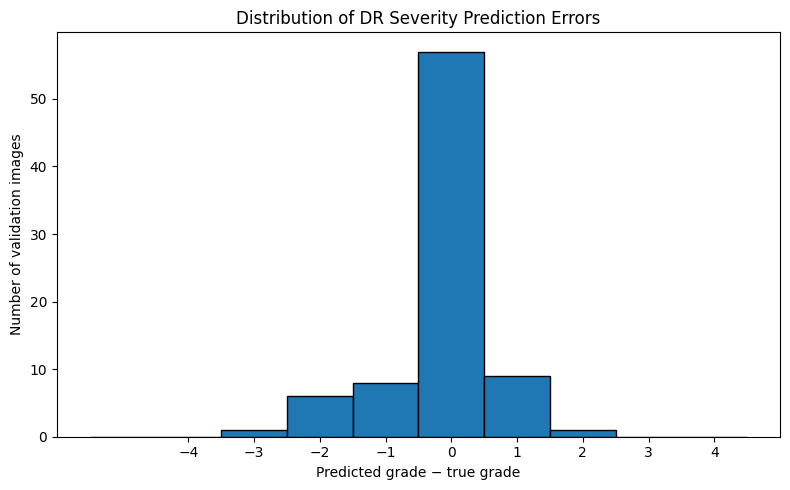

In [93]:
# CELL 81 — Ordinal severity error analysis

grade_difference = (
    error_predictions.astype(int) - error_targets.astype(int)
)

ordinal_summary = pd.DataFrame([{
    "validation_samples": len(error_targets),
    "exact_accuracy": float(np.mean(grade_difference == 0)),
    "within_one_grade": float(np.mean(np.abs(grade_difference) <= 1)),
    "mean_absolute_grade_error": float(
        np.mean(np.abs(grade_difference))
    ),
    "quadratic_weighted_kappa": float(
        cohen_kappa_score(
            error_targets,
            error_predictions,
            weights="quadratic",
        )
    ),
}])

display(ordinal_summary.round(4))

ordinal_summary.to_csv(
    RESULTS_DIR / "validation_ordinal_error_summary.csv",
    index=False,
)

# Plot signed grade errors.
plt.figure(figsize=(8, 5))
plt.hist(
    grade_difference,
    bins=np.arange(-NUM_CLASSES - 0.5, NUM_CLASSES + 0.5, 1),
    edgecolor="black",
)
plt.xticks(range(-(NUM_CLASSES - 1), NUM_CLASSES))
plt.xlabel("Predicted grade − true grade")
plt.ylabel("Number of validation images")
plt.title("Distribution of DR Severity Prediction Errors")
plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "validation_ordinal_error_distribution.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()

In [101]:
# ============================================================
# CELL 82 — DDR EXTERNAL DATASET AUDIT (CORRECTED)
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
from PIL import Image

KAGGLE_INPUT = Path("/kaggle/input")
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".tif", ".tiff", ".bmp"}

# 1. Locate the DDR CSV
csv_matches = [
    p for p in KAGGLE_INPUT.rglob("DR_grading.csv")
    if p.is_file()
]

if not csv_matches:
    raise FileNotFoundError(
        "DR_grading.csv not found. Check Kaggle > Add Input."
    )

EXTERNAL_CSV = csv_matches[0]
DDR_ROOT = EXTERNAL_CSV.parent

print("DDR CSV:", EXTERNAL_CSV)

raw_external_df = pd.read_csv(EXTERNAL_CSV)
print("CSV columns:", raw_external_df.columns.tolist())
print("CSV shape:", raw_external_df.shape)
display(raw_external_df.head())

# 2. Explicitly use the column names in your CSV
image_col = "id_code"
label_col = "diagnosis"

if image_col not in raw_external_df.columns:
    raise KeyError(f"Missing column: {image_col}")

if label_col not in raw_external_df.columns:
    raise KeyError(f"Missing column: {label_col}")

# 3. Index image files by filename and filename stem
image_files = [
    p for p in DDR_ROOT.rglob("*")
    if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
]

print("Image files discovered:", len(image_files))

image_lookup = {}

for path in image_files:
    image_lookup.setdefault(path.name.lower(), []).append(str(path))
    image_lookup.setdefault(path.stem.lower(), []).append(str(path))

def resolve_ddr_image(value):
    name = Path(str(value).strip()).name

    candidates = []
    for key in {name.lower(), Path(name).stem.lower()}:
        candidates.extend(image_lookup.get(key, []))

    candidates = list(dict.fromkeys(candidates))

    # Resolve only unique matches.
    return candidates[0] if len(candidates) == 1 else None

# 4. Build standardized dataframe
external_df = pd.DataFrame({
    "image": raw_external_df[image_col].astype(str).str.strip(),
    "label": pd.to_numeric(raw_external_df[label_col], errors="coerce")
})

external_df["image_path"] = external_df["image"].map(resolve_ddr_image)

print("Unmatched/ambiguous images:",
      int(external_df["image_path"].isna().sum()))
print("Invalid labels:",
      int(external_df["label"].isna().sum()))

external_df = external_df.dropna(
    subset=["image_path", "label"]
).copy()

# 5. Validate the five-class label range
if not np.allclose(
    external_df["label"].to_numpy(),
    external_df["label"].astype(int).to_numpy()
):
    raise ValueError("Non-integer DR grades found in diagnosis.")

external_df["label"] = external_df["label"].astype(int)

if not external_df["label"].isin(range(5)).all():
    raise ValueError(
        "Found grades outside 0–4. Verify DDR label definitions "
        "before evaluating the five-class model."
    )

# 6. Check image readability
def is_valid_image(path):
    try:
        with Image.open(path) as img:
            img.verify()
        return True
    except Exception:
        return False

external_df["valid_image"] = external_df["image_path"].map(
    is_valid_image
)

invalid_count = int((~external_df["valid_image"]).sum())

external_df = (
    external_df.loc[external_df["valid_image"]]
    .drop_duplicates(subset=["image_path"])
    .reset_index(drop=True)
)

# 7. Report audit results
print("\nDDR EXTERNAL DATASET AUDIT")
print("=" * 45)
print("Usable labeled images:", len(external_df))
print("Invalid images removed:", invalid_count)

print("\nClass distribution:")
print(
    external_df["label"]
    .value_counts()
    .reindex(range(5), fill_value=0)
    .sort_index()
)

display(external_df.head())

# 8. Save audit output
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

external_df.to_csv(
    RESULTS_DIR / "ddr_external_dataset_audit.csv",
    index=False
)

print("\nAudit saved successfully.")

DDR CSV: /kaggle/input/datasets/mariaherrerot/ddrdataset/DR_grading.csv
CSV columns: ['id_code', 'diagnosis']
CSV shape: (12522, 2)


,id_code,diagnosis
0,20170413102628830.jpg,0
1,20170413111955404.jpg,0
2,20170413112015395.jpg,0
3,20170413112017305.jpg,0
4,20170413112528859.jpg,0


Image files discovered: 12524
Unmatched/ambiguous images: 0
Invalid labels: 0

DDR EXTERNAL DATASET AUDIT
Usable labeled images: 12522
Invalid images removed: 0

Class distribution:
label
0    6266
1     630
2    4477
3     236
4     913
Name: count, dtype: int64


,image,label,image_path,valid_image
0,20170413102628830.jpg,0,/kaggle/input/datasets/mariaherrerot/ddrdatase...,True
1,20170413111955404.jpg,0,/kaggle/input/datasets/mariaherrerot/ddrdatase...,True
2,20170413112015395.jpg,0,/kaggle/input/datasets/mariaherrerot/ddrdatase...,True
3,20170413112017305.jpg,0,/kaggle/input/datasets/mariaherrerot/ddrdatase...,True
4,20170413112528859.jpg,0,/kaggle/input/datasets/mariaherrerot/ddrdatase...,True



Audit saved successfully.


In [102]:
# ============================================================
# CELL 83 — DDR EXTERNAL DATASET AND DATALOADER
# ============================================================

from torch.utils.data import DataLoader

assert "external_df" in globals(), "Run Cell 82 successfully first."
assert not external_df.empty, "DDR external dataset is empty."
assert "DRDataset" in globals(), "DRDataset is not defined."
assert "eval_transform" in globals(), "eval_transform is not defined."

# Keep only the columns expected by DRDataset.
ddr_eval_df = external_df[
    ["image_path", "label"]
].copy().reset_index(drop=True)

# Confirm labels are valid for the five-class model.
assert ddr_eval_df["label"].isin([0, 1, 2, 3, 4]).all(), (
    "DDR labels must be in the range 0–4."
)

# Create dataset with evaluation-only preprocessing.
ddr_external_dataset = DRDataset(
    ddr_eval_df,
    transform=eval_transform
)

# Create DataLoader; do not shuffle so predictions match dataframe rows.
ddr_external_loader = DataLoader(
    ddr_external_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=(DEVICE.type == "cuda")
)

print("DDR external images:", len(ddr_external_dataset))
print("DDR batches:", len(ddr_external_loader))
print("Device:", DEVICE)
print("\nDDR class distribution:")
print(ddr_eval_df["label"].value_counts().sort_index())

# Verify one batch before full evaluation.
images, labels = next(iter(ddr_external_loader))

print("\nBatch image shape:", tuple(images.shape))
print("Batch label shape:", tuple(labels.shape))
print("Batch labels:", labels[:10].tolist())

DDR external images: 12522
DDR batches: 392
Device: cuda

DDR class distribution:
label
0    6266
1     630
2    4477
3     236
4     913
Name: count, dtype: int64

Batch image shape: (32, 3, 224, 224)
Batch label shape: (32,)
Batch labels: [0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


In [103]:
# ============================================================
# CELL 84 — DDR EXTERNAL MODEL EVALUATION
# ============================================================

import numpy as np
import pandas as pd
from sklearn.metrics import classification_report, confusion_matrix

# Check required variables
required_vars = [
    "selected_model",
    "selected_use_tta",
    "final_temperature",
    "metrics_from_probs",
    "RESULTS_DIR",
    "NUM_CLASSES"
]

for var in required_vars:
    assert var in globals(), f"Required variable missing: {var}"

assert "ddr_external_loader" in globals(), "Run Cell 83 first."

# ------------------------------------------------------------
# 1. Generate predictions using the frozen selected model
# ------------------------------------------------------------
y_external, probs_external_raw = predict_probabilities(
    selected_model,
    ddr_external_loader,
    use_tta=selected_use_tta
)

y_external = np.asarray(y_external, dtype=np.int64)
probs_external_raw = np.asarray(
    probs_external_raw, dtype=np.float64
)

# ------------------------------------------------------------
# 2. Validate output dimensions and probabilities
# ------------------------------------------------------------
if probs_external_raw.shape != (len(y_external), NUM_CLASSES):
    raise ValueError(
        f"Expected probability shape (N, {NUM_CLASSES}), "
        f"got {probs_external_raw.shape}"
    )

if len(y_external) != len(ddr_eval_df):
    raise ValueError(
        "Prediction count does not match DDR dataset length."
    )

if not np.isfinite(probs_external_raw).all():
    raise ValueError("Predictions contain NaN or infinite values.")

probs_external_raw = np.clip(
    probs_external_raw, 1e-12, 1.0
)
probs_external_raw /= probs_external_raw.sum(
    axis=1, keepdims=True
)

# ------------------------------------------------------------
# 3. Apply temperature from internal validation ONLY
# ------------------------------------------------------------
temperature = max(float(final_temperature), 1e-6)

log_probs = np.log(probs_external_raw)
scaled_logits = log_probs / temperature
scaled_logits -= scaled_logits.max(axis=1, keepdims=True)

probs_external = np.exp(scaled_logits)
probs_external /= probs_external.sum(axis=1, keepdims=True)

pred_external = probs_external.argmax(axis=1)

# Ground-truth labels follow the non-shuffled DataLoader order.
true_external = ddr_eval_df["label"].to_numpy(dtype=np.int64)

# ------------------------------------------------------------
# 4. Calculate metrics
# ------------------------------------------------------------
external_metrics = metrics_from_probs(
    true_external,
    probs_external
)

class_names = [
    "No DR",
    "Mild",
    "Moderate",
    "Severe",
    "Proliferative DR"
]

print("=" * 60)
print("DDR EXTERNAL EVALUATION")
print("=" * 60)
print("Selected model:", selected_name)
print("Number of images:", len(true_external))
print("Temperature:", temperature)

for metric, value in external_metrics.items():
    print(f"{metric}: {value}")

print("\nClassification report:")
print(classification_report(
    true_external,
    pred_external,
    labels=[0, 1, 2, 3, 4],
    target_names=class_names,
    zero_division=0
))

cm = confusion_matrix(
    true_external,
    pred_external,
    labels=[0, 1, 2, 3, 4]
)

print("\nConfusion matrix:")
print(cm)

# ------------------------------------------------------------
# 5. Save metrics, confusion matrix and image predictions
# ------------------------------------------------------------
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

pd.DataFrame([external_metrics]).to_csv(
    RESULTS_DIR / "ddr_external_metrics.csv",
    index=False
)

pd.DataFrame(
    cm,
    index=class_names,
    columns=class_names
).to_csv(
    RESULTS_DIR / "ddr_external_confusion_matrix.csv"
)

predictions_df = ddr_eval_df.copy()
predictions_df["true_label"] = true_external
predictions_df["predicted_label"] = pred_external
predictions_df["confidence"] = probs_external.max(axis=1)

for class_id in range(NUM_CLASSES):
    predictions_df[f"prob_class_{class_id}"] = (
        probs_external[:, class_id]
    )

predictions_df.to_csv(
    RESULTS_DIR / "ddr_external_predictions.csv",
    index=False
)

print("\nSaved DDR evaluation files in:", RESULTS_DIR)

DDR EXTERNAL EVALUATION
Selected model: Balanced fine-tuned ConvNeXt-Tiny
Number of images: 12522
Temperature: 1.1381041910876293
accuracy: 0.6627535537454081
macro_f1: 0.44582947274739626
qwk: 0.6396492092967809

Classification report:
                  precision    recall  f1-score   support

           No DR       0.69      0.92      0.79      6266
            Mild       0.12      0.09      0.10       630
        Moderate       0.74      0.42      0.53      4477
          Severe       0.33      0.19      0.24       236
Proliferative DR       0.52      0.62      0.57       913

        accuracy                           0.66     12522
       macro avg       0.48      0.45      0.45     12522
    weighted avg       0.66      0.66      0.64     12522


Confusion matrix:
[[5773  203  251    0   39]
 [ 489   55   81    1    4]
 [1958  188 1860   70  401]
 [  25    5   80   44   82]
 [  90    9  230   17  567]]

Saved DDR evaluation files in: /kaggle/working/DR_Project/results


In [104]:
# ============================================================
# CELL 85 — DDR DUPLICATE IMAGE / DATA LEAKAGE AUDIT
# ============================================================

import hashlib
import pandas as pd
from pathlib import Path

assert "ddr_eval_df" in globals(), "Run Cell 83 first."
assert "RESULTS_DIR" in globals(), "RESULTS_DIR is not defined."

# Collect images from the internal splits.
split_frames = []

for split_name in ["train_df", "val_df", "test_labels"]:
    if split_name in globals():
        frame = globals()[split_name].copy()

        if "image_path" in frame.columns:
            frame = frame[["image_path"]].copy()
            frame["split"] = split_name
            split_frames.append(frame)

if not split_frames:
    raise RuntimeError(
        "No internal split DataFrames with an image_path column were found."
    )

internal_df = pd.concat(split_frames, ignore_index=True)
internal_df["image_path"] = internal_df["image_path"].astype(str)
internal_df = internal_df.drop_duplicates(subset=["image_path"])

# SHA-256 identifies exact file-content matches.
def sha256_file(path, chunk_size=1024 * 1024):
    digest = hashlib.sha256()

    with open(path, "rb") as file:
        while True:
            chunk = file.read(chunk_size)
            if not chunk:
                break
            digest.update(chunk)

    return digest.hexdigest()


print("Hashing internal images...")
internal_hash_records = []

for row in internal_df.itertuples(index=False):
    path = Path(row.image_path)

    if path.is_file():
        try:
            internal_hash_records.append({
                "image_path": str(path),
                "split": row.split,
                "sha256": sha256_file(path)
            })
        except OSError as exc:
            print(f"Could not hash internal image {path}: {exc}")

internal_hash_df = pd.DataFrame(internal_hash_records)

print("Hashing DDR images...")
ddr_hash_records = []

for path_string in ddr_eval_df["image_path"].astype(str):
    path = Path(path_string)

    if path.is_file():
        try:
            ddr_hash_records.append({
                "image_path": str(path),
                "sha256": sha256_file(path)
            })
        except OSError as exc:
            print(f"Could not hash DDR image {path}: {exc}")

ddr_hash_df = pd.DataFrame(ddr_hash_records)

if internal_hash_df.empty or ddr_hash_df.empty:
    raise RuntimeError("No images could be hashed. Check your image paths.")

# Find exact byte-for-byte duplicates.
overlap_df = ddr_hash_df.merge(
    internal_hash_df,
    on="sha256",
    how="inner",
    suffixes=("_ddr", "_internal")
)

print("\n" + "=" * 60)
print("DDR DUPLICATE IMAGE AUDIT")
print("=" * 60)
print("DDR images hashed:", len(ddr_hash_df))
print("Internal images hashed:", len(internal_hash_df))
print("Exact duplicate matches:", len(overlap_df))

if overlap_df.empty:
    print(
        "No exact file-content duplicates found between DDR and "
        "the internal splits."
    )
else:
    print("\nDuplicate matches by internal split:")
    print(overlap_df["split"].value_counts())

    print("\nExample duplicate matches:")
    print(overlap_df.head(10).to_string(index=False))

RESULTS_DIR.mkdir(parents=True, exist_ok=True)

overlap_df.to_csv(
    RESULTS_DIR / "ddr_internal_exact_duplicates.csv",
    index=False
)

internal_hash_df.to_csv(
    RESULTS_DIR / "internal_image_hashes.csv",
    index=False
)

ddr_hash_df.to_csv(
    RESULTS_DIR / "ddr_image_hashes.csv",
    index=False
)

print("\nAudit files saved to:", RESULTS_DIR)

Hashing internal images...
Hashing DDR images...

DDR DUPLICATE IMAGE AUDIT
DDR images hashed: 12522
Internal images hashed: 510
Exact duplicate matches: 0
No exact file-content duplicates found between DDR and the internal splits.

Audit files saved to: /kaggle/working/DR_Project/results


In [105]:
# ============================================================
# CELL 86 — INTERNAL TEST VS DDR EXTERNAL PERFORMANCE
# ============================================================

import pandas as pd
import numpy as np

# ------------------------------------------------------------
# 1. Verify required results
# ------------------------------------------------------------
assert "test_metrics_final" in globals(), (
    "test_metrics_final is missing. Run the internal test evaluation first."
)

assert "external_metrics" in globals(), (
    "external_metrics is missing. Run Cell 84 first."
)

assert "RESULTS_DIR" in globals(), "RESULTS_DIR is not defined."

# ------------------------------------------------------------
# 2. Standardize metric names
# ------------------------------------------------------------
internal_metrics = dict(test_metrics_final)
ddr_metrics = dict(external_metrics)

# Include common metrics when they are available.
preferred_metrics = [
    "accuracy",
    "macro_f1",
    "qwk",
    "loss",
    "balanced_accuracy",
    "macro_precision",
    "macro_recall"
]

available_metrics = [
    metric for metric in preferred_metrics
    if metric in internal_metrics or metric in ddr_metrics
]

# Include any additional metrics returned by your metric function.
for metric in list(internal_metrics) + list(ddr_metrics):
    if metric not in available_metrics:
        available_metrics.append(metric)

# ------------------------------------------------------------
# 3. Build comparison table
# ------------------------------------------------------------
comparison_rows = []

for metric in available_metrics:
    internal_value = internal_metrics.get(metric, np.nan)
    ddr_value = ddr_metrics.get(metric, np.nan)

    try:
        internal_value = float(internal_value)
    except (TypeError, ValueError):
        internal_value = np.nan

    try:
        ddr_value = float(ddr_value)
    except (TypeError, ValueError):
        ddr_value = np.nan

    difference = (
        ddr_value - internal_value
        if np.isfinite(ddr_value) and np.isfinite(internal_value)
        else np.nan
    )

    comparison_rows.append({
        "metric": metric,
        "internal_test": internal_value,
        "DDR_external": ddr_value,
        "DDR_minus_internal": difference
    })

performance_comparison = pd.DataFrame(comparison_rows)

# ------------------------------------------------------------
# 4. Display results
# ------------------------------------------------------------
print("=" * 75)
print("INTERNAL IDRiD TEST VS DDR EXTERNAL EVALUATION")
print("=" * 75)

print("Internal test images:", len(y_test_final) if "y_test_final" in globals() else "Check notebook")
print("DDR external images:", len(ddr_eval_df))
print("Selected model:", globals().get("selected_name", "Selected model"))

display(
    performance_comparison.style.format({
        "internal_test": "{:.4f}",
        "DDR_external": "{:.4f}",
        "DDR_minus_internal": "{:+.4f}"
    }, na_rep="N/A")
)

# ------------------------------------------------------------
# 5. Save results
# ------------------------------------------------------------
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

comparison_path = (
    RESULTS_DIR / "internal_vs_DDR_external_comparison.csv"
)

performance_comparison.to_csv(comparison_path, index=False)

print("\nSaved comparison to:", comparison_path)

INTERNAL IDRiD TEST VS DDR EXTERNAL EVALUATION
Internal test images: 103
DDR external images: 12522
Selected model: Balanced fine-tuned ConvNeXt-Tiny


,metric,internal_test,DDR_external,DDR_minus_internal
0,accuracy,0.5534,0.6628,+0.1094
1,macro_f1,0.4045,0.4458,+0.0413
2,qwk,0.6505,0.6396,-0.0109
3,model,N/A,N/A,N/A
4,tta_enabled,0.0000,N/A,N/A
5,temperature,1.1381,N/A,N/A
6,test_samples,103.0000,N/A,N/A
7,nll,1.1190,N/A,N/A
8,multiclass_brier,0.5928,N/A,N/A



Saved comparison to: /kaggle/working/DR_Project/results/internal_vs_DDR_external_comparison.csv


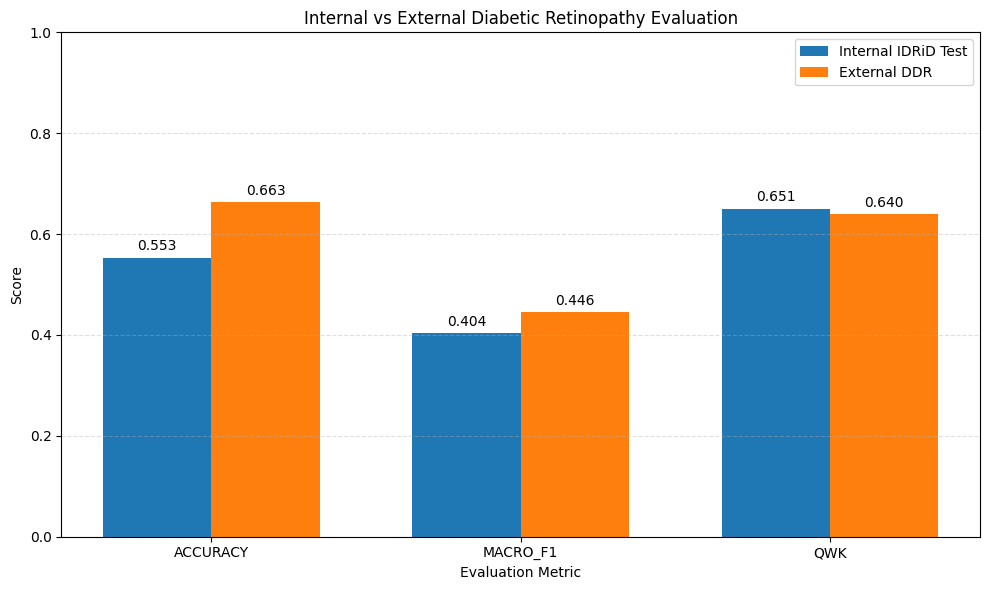

Figure saved to: /kaggle/working/DR_Project/results/internal_vs_DDR_performance.png


In [106]:
# ============================================================
# CELL 87 — INTERNAL VS DDR PERFORMANCE VISUALIZATION
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

assert "performance_comparison" in globals(), (
    "Run Cell 86 first."
)

# Metrics commonly used for DR grading.
plot_metrics = ["accuracy", "macro_f1", "qwk"]

plot_df = performance_comparison[
    performance_comparison["metric"].isin(plot_metrics)
].copy()

if plot_df.empty:
    raise ValueError(
        "No accuracy, macro_f1, or qwk metrics found. "
        "Check the output of Cell 86."
    )

# Keep only metrics available for both datasets.
plot_df = plot_df.dropna(
    subset=["internal_test", "DDR_external"]
)

if plot_df.empty:
    raise ValueError(
        "No metrics are available for both internal and external evaluation."
    )

# ------------------------------------------------------------
# Plot comparison
# ------------------------------------------------------------
x = np.arange(len(plot_df))
bar_width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))

internal_bars = ax.bar(
    x - bar_width / 2,
    plot_df["internal_test"],
    bar_width,
    label="Internal IDRiD Test"
)

external_bars = ax.bar(
    x + bar_width / 2,
    plot_df["DDR_external"],
    bar_width,
    label="External DDR"
)

ax.set_xlabel("Evaluation Metric")
ax.set_ylabel("Score")
ax.set_title("Internal vs External Diabetic Retinopathy Evaluation")
ax.set_xticks(x)
ax.set_xticklabels(plot_df["metric"].str.upper())
ax.legend()
ax.grid(axis="y", linestyle="--", alpha=0.4)

# Add values above each bar.
ax.bar_label(internal_bars, fmt="%.3f", padding=3)
ax.bar_label(external_bars, fmt="%.3f", padding=3)

# Use a suitable range for score metrics.
ax.set_ylim(
    0,
    max(
        1.0,
        float(plot_df[["internal_test", "DDR_external"]].max().max()) * 1.12
    )
)

plt.tight_layout()

figure_path = RESULTS_DIR / "internal_vs_DDR_performance.png"
plt.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()

print("Figure saved to:", figure_path)

In [107]:
# ============================================================
# CELL 88 — EXTERNAL GENERALIZATION SUMMARY
# ============================================================

import numpy as np
import pandas as pd

assert "performance_comparison" in globals(), (
    "Run Cell 86 first."
)

summary_df = performance_comparison.copy()

metric_labels = {
    "accuracy": "Accuracy",
    "macro_f1": "Macro-F1",
    "qwk": "Quadratic Weighted Kappa (QWK)",
    "loss": "Loss",
    "balanced_accuracy": "Balanced Accuracy",
    "macro_precision": "Macro Precision",
    "macro_recall": "Macro Recall"
}

print("=" * 70)
print("EXTERNAL GENERALIZATION SUMMARY")
print("=" * 70)

print(
    "Internal evaluation: IDRiD test split\n"
    "External evaluation: DDR dataset"
)

for _, row in summary_df.iterrows():
    metric = row["metric"]
    internal = row["internal_test"]
    external = row["DDR_external"]
    difference = row["DDR_minus_internal"]

    label = metric_labels.get(metric, metric)

    if pd.isna(internal) or pd.isna(external):
        print(f"\n{label}: comparison unavailable.")
        continue

    print(f"\n{label}")
    print(f"  Internal test: {internal:.4f}")
    print(f"  DDR external:  {external:.4f}")
    print(f"  Difference:    {difference:+.4f}")

    if metric in ["accuracy", "macro_f1", "qwk", "balanced_accuracy",
                  "macro_precision", "macro_recall"]:
        if difference < -0.05:
            print("  Observation: notable decrease on DDR.")
        elif difference > 0.05:
            print("  Observation: higher score on DDR.")
        else:
            print("  Observation: scores are relatively close.")
    elif metric == "loss":
        if difference > 0.05:
            print("  Observation: loss increased on DDR.")
        elif difference < -0.05:
            print("  Observation: loss decreased on DDR.")
        else:
            print("  Observation: loss is relatively close.")

summary_path = RESULTS_DIR / "DDR_external_generalization_summary.txt"

with open(summary_path, "w", encoding="utf-8") as f:
    f.write("External Generalization Summary\n")
    f.write("Internal dataset: IDRiD test split\n")
    f.write("External dataset: DDR\n\n")

    for _, row in summary_df.iterrows():
        f.write(
            f"{row['metric']}: "
            f"internal={row['internal_test']}, "
            f"DDR={row['DDR_external']}, "
            f"difference={row['DDR_minus_internal']}\n"
        )

print("\nSummary saved to:", summary_path)

EXTERNAL GENERALIZATION SUMMARY
Internal evaluation: IDRiD test split
External evaluation: DDR dataset

Accuracy
  Internal test: 0.5534
  DDR external:  0.6628
  Difference:    +0.1094
  Observation: higher score on DDR.

Macro-F1
  Internal test: 0.4045
  DDR external:  0.4458
  Difference:    +0.0413
  Observation: scores are relatively close.

Quadratic Weighted Kappa (QWK)
  Internal test: 0.6505
  DDR external:  0.6396
  Difference:    -0.0109
  Observation: scores are relatively close.

model: comparison unavailable.

tta_enabled: comparison unavailable.

temperature: comparison unavailable.

test_samples: comparison unavailable.

nll: comparison unavailable.

multiclass_brier: comparison unavailable.

Summary saved to: /kaggle/working/DR_Project/results/DDR_external_generalization_summary.txt


In [108]:
# ============================================================
# CELL 89 — PER-CLASS DDR PERFORMANCE
# ============================================================

import numpy as np
import pandas as pd
from sklearn.metrics import (
    precision_recall_fscore_support,
    confusion_matrix
)

assert "true_external" in globals(), "Run Cell 84 first."
assert "pred_external" in globals(), "Run Cell 84 first."
assert "NUM_CLASSES" in globals()

class_names = [
    "No DR",
    "Mild",
    "Moderate",
    "Severe",
    "Proliferative DR"
]

labels = list(range(NUM_CLASSES))

precision, recall, f1, support = precision_recall_fscore_support(
    true_external,
    pred_external,
    labels=labels,
    zero_division=0
)

class_results = pd.DataFrame({
    "class_id": labels,
    "class_name": class_names,
    "precision": precision,
    "recall": recall,
    "f1_score": f1,
    "support": support
})

print("DDR PER-CLASS PERFORMANCE")
display(class_results.style.format({
    "precision": "{:.4f}",
    "recall": "{:.4f}",
    "f1_score": "{:.4f}"
}))

class_results.to_csv(
    RESULTS_DIR / "ddr_per_class_metrics.csv",
    index=False
)

print("Saved:", RESULTS_DIR / "ddr_per_class_metrics.csv")

DDR PER-CLASS PERFORMANCE


,class_id,class_name,precision,recall,f1_score,support
0,0,No DR,0.6926,0.9213,0.7908,6266
1,1,Mild,0.1196,0.0873,0.1009,630
2,2,Moderate,0.7434,0.4155,0.5330,4477
3,3,Severe,0.3333,0.1864,0.2391,236
4,4,Proliferative DR,0.5188,0.6210,0.5653,913


Saved: /kaggle/working/DR_Project/results/ddr_per_class_metrics.csv


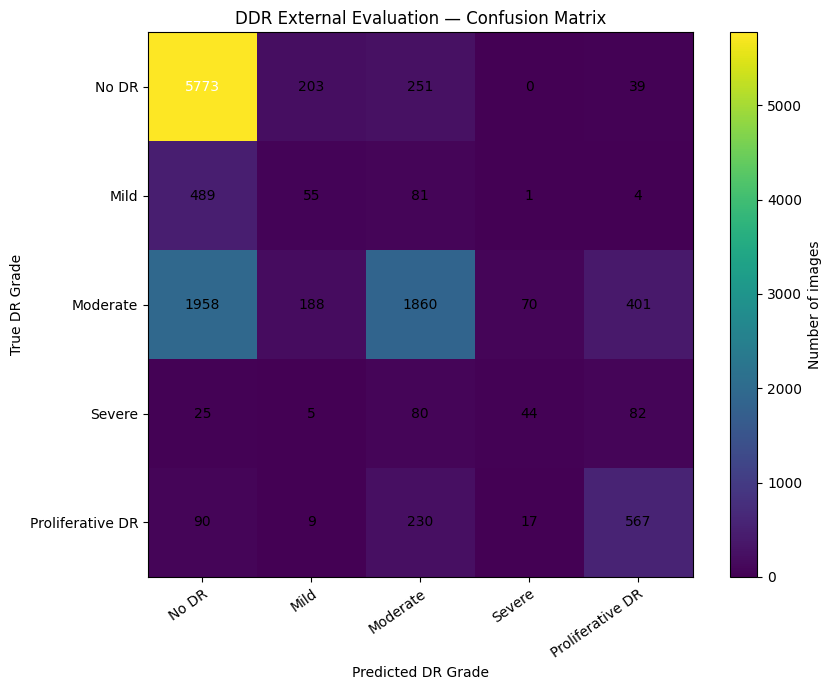

Saved: /kaggle/working/DR_Project/results/ddr_confusion_matrix.png


In [109]:
# ============================================================
# CELL 90 — DDR CONFUSION MATRIX VISUALIZATION
# ============================================================

import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    true_external,
    pred_external,
    labels=list(range(NUM_CLASSES))
)

fig, ax = plt.subplots(figsize=(9, 7))

image = ax.imshow(cm, interpolation="nearest")
fig.colorbar(image, ax=ax, label="Number of images")

ax.set(
    xticks=np.arange(NUM_CLASSES),
    yticks=np.arange(NUM_CLASSES),
    xticklabels=class_names,
    yticklabels=class_names,
    xlabel="Predicted DR Grade",
    ylabel="True DR Grade",
    title="DDR External Evaluation — Confusion Matrix"
)

plt.setp(
    ax.get_xticklabels(),
    rotation=35,
    ha="right",
    rotation_mode="anchor"
)

threshold = cm.max() / 2 if cm.size and cm.max() > 0 else 0

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(
            j,
            i,
            str(cm[i, j]),
            ha="center",
            va="center",
            color="white" if cm[i, j] > threshold else "black"
        )

fig.tight_layout()

cm_plot_path = RESULTS_DIR / "ddr_confusion_matrix.png"
fig.savefig(cm_plot_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", cm_plot_path)

DDR CONFIDENCE SUMMARY


,count,mean,median,min,max
correct,,,,,
Incorrect,4223,0.6416,0.6251,0.2542,0.9756
Correct,8299,0.7483,0.7948,0.2351,0.9797


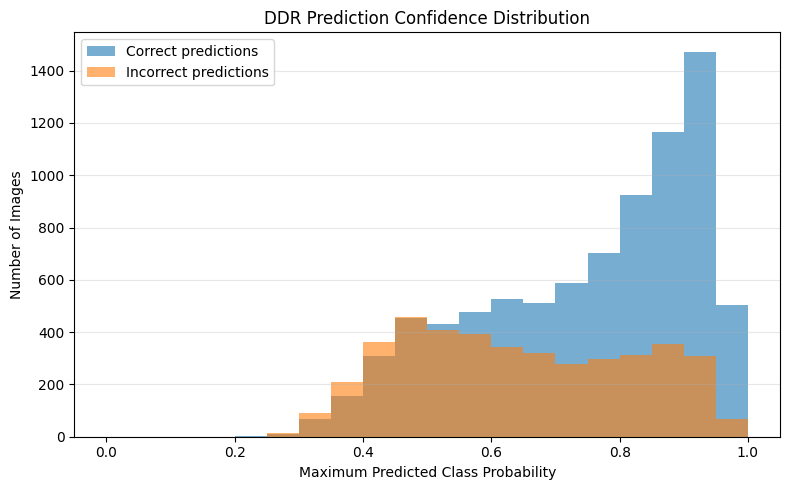

Saved confidence analysis to: /kaggle/working/DR_Project/results


In [110]:
# ============================================================
# CELL 91 — DDR PREDICTION CONFIDENCE ANALYSIS
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

assert "probs_external" in globals(), "Run Cell 84 first."

confidence = probs_external.max(axis=1)
correct = (pred_external == true_external)

confidence_df = pd.DataFrame({
    "true_label": true_external,
    "predicted_label": pred_external,
    "confidence": confidence,
    "correct": correct
})

print("DDR CONFIDENCE SUMMARY")
display(
    confidence_df.groupby("correct")["confidence"]
    .agg(["count", "mean", "median", "min", "max"])
    .rename(index={False: "Incorrect", True: "Correct"})
    .round(4)
)

# Confidence distribution for correct vs incorrect predictions.
fig, ax = plt.subplots(figsize=(8, 5))

for is_correct, group_name in [
    (True, "Correct predictions"),
    (False, "Incorrect predictions")
]:
    values = confidence[correct == is_correct]

    if len(values) > 0:
        ax.hist(
            values,
            bins=np.linspace(0, 1, 21),
            alpha=0.6,
            label=group_name
        )

ax.set_xlabel("Maximum Predicted Class Probability")
ax.set_ylabel("Number of Images")
ax.set_title("DDR Prediction Confidence Distribution")
ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()

confidence_plot_path = RESULTS_DIR / "ddr_confidence_distribution.png"
plt.savefig(confidence_plot_path, dpi=300, bbox_inches="tight")
plt.show()

confidence_df.to_csv(
    RESULTS_DIR / "ddr_prediction_confidence.csv",
    index=False
)

print("Saved confidence analysis to:", RESULTS_DIR)

In [111]:
# ============================================================
# CELL 92 — FINAL VERIFICATION AND RESULTS EXPORT
# Diabetic Retinopathy Research Project
# Does not train or modify the selected model
# ============================================================

from pathlib import Path
from datetime import datetime
import numpy as np
import pandas as pd
import json

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

PROJECT_DIR = Path("/kaggle/working/DR_Project")
RESULTS_DIR = PROJECT_DIR / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

CLASS_NAMES = {
    0: "No DR",
    1: "Mild",
    2: "Moderate",
    3: "Severe",
    4: "Proliferative DR"
}

audit = []
class_count_tables = []

def record_check(name, status, details):
    audit.append({
        "check": name,
        "status": status,
        "details": str(details)
    })
    print(f"[{status}] {name}: {details}")


def normalized_paths(df):
    """Normalize image paths for split-overlap checking."""
    return set(
        Path(str(p)).resolve().as_posix().lower()
        for p in df["image_path"].dropna()
    )


print("=" * 65)
print("FINAL PROJECT VERIFICATION")
print("=" * 65)

# ------------------------------------------------------------
# 2. VERIFY INTERNAL DATA SPLITS
# ------------------------------------------------------------

required_splits = {
    "train": "train_df",
    "validation": "val_df",
    "internal_test": "test_labels"
}

split_frames = {}

for split_name, variable_name in required_splits.items():
    df = globals().get(variable_name)

    if not isinstance(df, pd.DataFrame):
        record_check(
            f"{split_name} DataFrame",
            "NOT CHECKED",
            f"{variable_name} is unavailable in memory."
        )
        continue

    missing_columns = {
        "image_path", "label"
    } - set(df.columns)

    if missing_columns:
        record_check(
            f"{split_name} columns",
            "FAIL",
            f"Missing columns: {sorted(missing_columns)}"
        )
        continue

    split_frames[split_name] = df

    labels = pd.to_numeric(df["label"], errors="coerce")
    invalid_labels = labels.isna() | ~labels.isin(CLASS_NAMES.keys())
    missing_paths = df["image_path"].isna()
    duplicate_paths = df["image_path"].dropna().duplicated().sum()

    record_check(
        f"{split_name} labels",
        "PASS" if not invalid_labels.any() else "FAIL",
        f"{len(df)} rows; invalid/missing labels: "
        f"{int(invalid_labels.sum())}"
    )

    record_check(
        f"{split_name} image paths",
        "PASS" if not missing_paths.any() else "FAIL",
        f"Missing paths: {int(missing_paths.sum())}; "
        f"duplicate path rows: {int(duplicate_paths)}"
    )

    # Check whether referenced files actually exist.
    existing = df["image_path"].dropna().astype(str).map(
        lambda p: Path(p).is_file()
    )
    record_check(
        f"{split_name} file existence",
        "PASS" if existing.all() else "FAIL",
        f"Existing: {int(existing.sum())}; "
        f"missing: {int((~existing).sum())}"
    )

    counts = (
        labels[~invalid_labels]
        .astype(int)
        .value_counts()
        .reindex(CLASS_NAMES.keys(), fill_value=0)
    )

    for grade, count in counts.items():
        class_count_tables.append({
            "dataset_split": split_name,
            "label": int(grade),
            "class_name": CLASS_NAMES[int(grade)],
            "image_count": int(count)
        })

# Compare internal split paths.
if len(split_frames) == 3:
    path_sets = {
        name: normalized_paths(df)
        for name, df in split_frames.items()
    }

    pairs = [
        ("train", "validation"),
        ("train", "internal_test"),
        ("validation", "internal_test")
    ]

    for a, b in pairs:
        overlap = path_sets[a] & path_sets[b]
        record_check(
            f"{a} vs {b} path overlap",
            "PASS" if not overlap else "FAIL",
            f"{len(overlap)} shared normalized paths"
        )
else:
    record_check(
        "Internal split separation",
        "NOT CHECKED",
        "All three split DataFrames must be available."
    )

# ------------------------------------------------------------
# 3. VERIFY DDR LABELS AND DATA SEPARATION
# ------------------------------------------------------------

ddr_df = globals().get("ddr_eval_df")
if not isinstance(ddr_df, pd.DataFrame):
    ddr_df = globals().get("external_df")

if isinstance(ddr_df, pd.DataFrame):
    if {"image_path", "label"}.issubset(ddr_df.columns):
        ddr_labels = pd.to_numeric(
            ddr_df["label"], errors="coerce"
        )
        invalid = (
            ddr_labels.isna()
            | ~ddr_labels.isin(CLASS_NAMES.keys())
        )

        record_check(
            "DDR label values",
            "PASS" if not invalid.any() else "FAIL",
            f"{len(ddr_df)} rows; invalid labels: "
            f"{int(invalid.sum())}"
        )

        for grade, count in (
            ddr_labels[~invalid]
            .astype(int)
            .value_counts()
            .reindex(CLASS_NAMES.keys(), fill_value=0)
            .items()
        ):
            class_count_tables.append({
                "dataset_split": "DDR_external",
                "label": int(grade),
                "class_name": CLASS_NAMES[int(grade)],
                "image_count": int(count)
            })

        # Compare paths with the internal splits.
        if split_frames:
            internal_paths = set()
            for df in split_frames.values():
                internal_paths.update(normalized_paths(df))

            ddr_paths = normalized_paths(ddr_df)
            overlap = internal_paths & ddr_paths

            record_check(
                "DDR vs internal path overlap",
                "PASS" if not overlap else "FAIL",
                f"{len(overlap)} shared normalized paths"
            )

        # Check DDR image files.
        ddr_exists = ddr_df["image_path"].dropna().astype(str).map(
            lambda p: Path(p).is_file()
        )
        record_check(
            "DDR file existence",
            "PASS" if ddr_exists.all() else "FAIL",
            f"Existing: {int(ddr_exists.sum())}; "
            f"missing: {int((~ddr_exists).sum())}"
        )

    else:
        record_check(
            "DDR dataset columns",
            "FAIL",
            "Expected image_path and label columns."
        )
else:
    record_check(
        "DDR dataset",
        "NOT CHECKED",
        "DDR DataFrame is unavailable in memory."
    )

# Important: numeric labels alone cannot prove semantic mapping.
record_check(
    "Five-class semantic mapping",
    "MANUAL CHECK REQUIRED",
    "Confirm from official dataset documentation that labels "
    "0-4 mean No DR, Mild, Moderate, Severe, Proliferative DR."
)

record_check(
    "DDR independence",
    "MANUAL CHECK REQUIRED",
    "Review notebook history to ensure DDR was not used for "
    "training, model selection, hyperparameter tuning or calibration."
)

record_check(
    "Exact and transformed duplicates",
    "MANUAL CHECK REQUIRED",
    "The earlier audit found zero exact file-content matches. "
    "This does not exclude resized or recompressed duplicates."
)

# ------------------------------------------------------------
# 4. VERIFY EXISTING EVALUATION RESULTS
# ------------------------------------------------------------

if "external_metrics" in globals():
    record_check(
        "DDR evaluation metrics",
        "PASS" if isinstance(external_metrics, dict) else "FAIL",
        "external_metrics variable is available."
    )
else:
    record_check(
        "DDR evaluation metrics",
        "NOT CHECKED",
        "external_metrics variable is unavailable."
    )

if "test_metrics_final" in globals():
    record_check(
        "Internal test metrics",
        "PASS" if isinstance(test_metrics_final, dict) else "FAIL",
        "test_metrics_final variable is available."
    )
else:
    record_check(
        "Internal test metrics",
        "NOT CHECKED",
        "test_metrics_final variable is unavailable."
    )

if "selected_model" in globals():
    record_check(
        "Selected model",
        "PASS",
        f"Model object available: {type(selected_model).__name__}"
    )
else:
    record_check(
        "Selected model",
        "NOT CHECKED",
        "selected_model variable is unavailable."
    )

# ------------------------------------------------------------
# 5. VERIFY SAVED OUTPUTS
# ------------------------------------------------------------

expected_files = [
    "ddr_external_metrics.csv",
    "ddr_external_predictions.csv",
    "ddr_external_confusion_matrix.csv",
    "internal_vs_DDR_external_comparison.csv",
    "ddr_per_class_metrics.csv",
    "ddr_confusion_matrix.png",
    "ddr_confidence_distribution.png",
    "DDR_external_generalization_summary.txt"
]

for filename in expected_files:
    path = RESULTS_DIR / filename
    exists = path.is_file()

    record_check(
        f"Output: {filename}",
        "PASS" if exists else "NOT FOUND",
        f"Size: {path.stat().st_size:,} bytes"
        if exists else "File not found at expected path."
    )

# ------------------------------------------------------------
# 6. EXPORT AUDIT AND CLASS COUNTS
# ------------------------------------------------------------

audit_df = pd.DataFrame(audit)
audit_path = RESULTS_DIR / "final_verification_report.csv"
audit_df.to_csv(audit_path, index=False)

class_counts_df = pd.DataFrame(class_count_tables)
counts_path = RESULTS_DIR / "final_dataset_class_counts.csv"
class_counts_df.to_csv(counts_path, index=False)

summary_path = RESULTS_DIR / "final_project_summary.txt"

with open(summary_path, "w", encoding="utf-8") as f:
    f.write("DIABETIC RETINOPATHY PROJECT — FINAL VERIFICATION\n")
    f.write(f"Generated: {datetime.now().isoformat(timespec='seconds')}\n\n")
    f.write(f"Project directory: {PROJECT_DIR}\n")
    f.write(f"Results directory: {RESULTS_DIR}\n\n")
    f.write("CLASS MAPPING TO VERIFY AGAINST OFFICIAL DOCUMENTATION:\n")

    for grade, name in CLASS_NAMES.items():
        f.write(f"{grade}: {name}\n")

    f.write("\nVERIFICATION RESULTS:\n")
    f.write(audit_df.to_string(index=False))
    f.write("\n\nIMPORTANT:\n")
    f.write(
        "This report checks available variables, paths and output files. "
        "It cannot independently prove semantic label correctness, "
        "absence of transformed duplicates, or that DDR was never used "
        "during training/tuning. Review those items manually.\n"
    )

print("\n" + "=" * 65)
print("FINAL VERIFICATION SUMMARY")
print("=" * 65)
print(audit_df["status"].value_counts().to_string())

print("\nSaved reports:")
print(audit_path)
print(counts_path)
print(summary_path)

print("\nReview every FAIL, NOT FOUND, NOT CHECKED, and")
print("MANUAL CHECK REQUIRED entry before final submission.")


FINAL PROJECT VERIFICATION
[PASS] train labels: 325 rows; invalid/missing labels: 0
[PASS] train image paths: Missing paths: 0; duplicate path rows: 0
[PASS] train file existence: Existing: 325; missing: 0
[PASS] validation labels: 82 rows; invalid/missing labels: 0
[PASS] validation image paths: Missing paths: 0; duplicate path rows: 0
[PASS] validation file existence: Existing: 82; missing: 0
[PASS] internal_test labels: 103 rows; invalid/missing labels: 0
[PASS] internal_test image paths: Missing paths: 0; duplicate path rows: 0
[PASS] internal_test file existence: Existing: 103; missing: 0
[PASS] train vs validation path overlap: 0 shared normalized paths
[PASS] train vs internal_test path overlap: 0 shared normalized paths
[PASS] validation vs internal_test path overlap: 0 shared normalized paths
[PASS] DDR label values: 12522 rows; invalid labels: 0
[PASS] DDR vs internal path overlap: 0 shared normalized paths
[PASS] DDR file existence: Existing: 12522; missing: 0
[MANUAL CHECK 

In [112]:
import pandas as pd
from pathlib import Path

report_path = Path(
    "/kaggle/working/DR_Project/results/final_verification_report.csv"
)

report = pd.read_csv(report_path)

print("MANUAL CHECK REQUIRED entries:")
display(
    report[
        report["status"].astype(str).str.upper()
        .str.contains("MANUAL CHECK REQUIRED", na=False)
    ]
)

print("\nAny FAIL / NOT FOUND / NOT CHECKED entries:")
display(
    report[
        report["status"].astype(str).str.upper()
        .str.contains(r"FAIL|NOT FOUND|NOT CHECKED", na=False)
    ]
)

MANUAL CHECK REQUIRED entries:


,check,status,details
15,Five-class semantic mapping,MANUAL CHECK REQUIRED,Confirm from official dataset documentation th...
16,DDR independence,MANUAL CHECK REQUIRED,Review notebook history to ensure DDR was not ...
17,Exact and transformed duplicates,MANUAL CHECK REQUIRED,The earlier audit found zero exact file-conten...



Any FAIL / NOT FOUND / NOT CHECKED entries:


,check,status,details


In [113]:
# Inspect the label mappings and class counts used by the notebook

print("Expected class names:")
print(CLASS_NAMES)

print("\nIDRiD internal dataset label counts:")
for name, df in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Internal test", test_labels),
]:
    print(f"\n{name}:")
    print(df["label"].value_counts(dropna=False).sort_index())

print("\nDDR label counts:")
ddr_df = (
    ddr_eval_df
    if "ddr_eval_df" in globals()
    else external_df
)
print(ddr_df["label"].value_counts(dropna=False).sort_index())

print("\nDDR source columns:")
print(ddr_df.columns.tolist())

if "diagnosis" in ddr_df.columns:
    print("\nDDR original diagnosis counts:")
    print(ddr_df["diagnosis"].value_counts(dropna=False).sort_index())

Expected class names:
{0: 'No DR', 1: 'Mild', 2: 'Moderate', 3: 'Severe', 4: 'Proliferative DR'}

IDRiD internal dataset label counts:

Train:
label
0    106
1     15
2    106
3     59
4     39
Name: count, dtype: int64

Validation:
label
0    27
1     4
2    27
3    14
4    10
Name: count, dtype: int64

Internal test:
label
0    34
1     5
2    32
3    19
4    13
Name: count, dtype: int64

DDR label counts:
label
0    6266
1     630
2    4477
3     236
4     913
Name: count, dtype: int64

DDR source columns:
['image_path', 'label']


In [114]:
from pathlib import Path
import pandas as pd

# Find likely annotation CSVs in the attached Kaggle datasets
for root in [Path("/kaggle/input")]:
    print("Searching for relevant annotation CSV files...")
    candidates = [
        p for p in root.rglob("*.csv")
        if any(word in p.name.lower()
               for word in ["label", "grade", "diagnos", "ddr"])
    ]

    for p in candidates[:50]:
        print("\nFile:", p)
        try:
            preview = pd.read_csv(p, nrows=5)
            print("Columns:", preview.columns.tolist())
            print(preview.head(3).to_string(index=False))
        except Exception as e:
            print("Could not read:", e)

Searching for relevant annotation CSV files...

File: /kaggle/input/datasets/mariaherrerot/idrid-dataset/idrid_labels.csv
Columns: ['id_code', 'diagnosis', 'Risk of macular edema ', 'Unnamed: 3', 'Unnamed: 4', 'Unnamed: 5', 'Unnamed: 6', 'Unnamed: 7', 'Unnamed: 8', 'Unnamed: 9', 'Unnamed: 10', 'Unnamed: 11']
  id_code  diagnosis  Risk of macular edema   Unnamed: 3  Unnamed: 4  Unnamed: 5  Unnamed: 6  Unnamed: 7  Unnamed: 8  Unnamed: 9  Unnamed: 10  Unnamed: 11
IDRiD_001          3                       2         NaN         NaN         NaN         NaN         NaN         NaN         NaN          NaN          NaN
IDRiD_002          3                       2         NaN         NaN         NaN         NaN         NaN         NaN         NaN          NaN          NaN
IDRiD_003          2                       2         NaN         NaN         NaN         NaN         NaN         NaN         NaN          NaN          NaN

File: /kaggle/input/datasets/dankok/diabetic-retinopathy-image-datase

In [115]:
from pathlib import Path
import pandas as pd

test_csv = Path(
    "/kaggle/input/datasets/dankok/"
    "diabetic-retinopathy-image-dataset/"
    "Disease_Grading/Groundtruths/"
    "IDRiD_Disease Grading_Testing Labels.csv"
)

official_test = pd.read_csv(test_csv)
official_test["Image name"] = official_test["Image name"].astype(str).str.strip()

# Extract image ID from each internal-test image path
check_df = test_labels.copy()
check_df["image_id"] = check_df["image_path"].apply(
    lambda p: Path(str(p)).stem
)

# Compare only IDs that can be matched directly
comparison = check_df.merge(
    official_test[["Image name", "Retinopathy grade"]],
    left_on="image_id",
    right_on="Image name",
    how="left"
)

print("Internal test rows:", len(check_df))
print("Rows matched to official test CSV:",
      comparison["Retinopathy grade"].notna().sum())
print("Rows with label disagreement:",
      (
          comparison["Retinopathy grade"].notna()
          & (
              comparison["label"].astype("Int64")
              != comparison["Retinopathy grade"].astype("Int64")
          )
      ).sum())

display(
    comparison[
        ["image_path", "label", "Retinopathy grade"]
    ].head(15)
)

Internal test rows: 103
Rows matched to official test CSV: 103
Rows with label disagreement: 0


,image_path,label,Retinopathy grade
0,/kaggle/input/datasets/dankok/diabetic-retinop...,4,4
1,/kaggle/input/datasets/dankok/diabetic-retinop...,4,4
2,/kaggle/input/datasets/dankok/diabetic-retinop...,4,4
3,/kaggle/input/datasets/dankok/diabetic-retinop...,4,4
4,/kaggle/input/datasets/dankok/diabetic-retinop...,4,4
5,/kaggle/input/datasets/dankok/diabetic-retinop...,3,3
6,/kaggle/input/datasets/dankok/diabetic-retinop...,3,3
7,/kaggle/input/datasets/dankok/diabetic-retinop...,2,2
8,/kaggle/input/datasets/dankok/diabetic-retinop...,2,2
9,/kaggle/input/datasets/dankok/diabetic-retinop...,2,2


In [116]:
from pathlib import Path
import pandas as pd

train_csv = Path(
    "/kaggle/input/datasets/dankok/"
    "diabetic-retinopathy-image-dataset/"
    "Disease_Grading/Groundtruths/"
    "IDRiD_Disease Grading_Training Labels.csv"
)

official_train = pd.read_csv(train_csv)
official_train["Image name"] = (
    official_train["Image name"].astype(str).str.strip()
)

official_train = official_train.dropna(
    subset=["Image name", "Retinopathy grade"]
).copy()

official_train["Retinopathy grade"] = pd.to_numeric(
    official_train["Retinopathy grade"], errors="coerce"
)
official_train = official_train.dropna(
    subset=["Retinopathy grade"]
)
official_train["Retinopathy grade"] = (
    official_train["Retinopathy grade"].astype(int)
)

for split_name, df in [
    ("Train", train_df),
    ("Validation", val_df),
]:
    check = df.copy()
    check["image_id"] = check["image_path"].apply(
        lambda p: Path(str(p)).stem
    )

    merged = check.merge(
        official_train[["Image name", "Retinopathy grade"]],
        left_on="image_id",
        right_on="Image name",
        how="left"
    )

    matched = merged["Retinopathy grade"].notna()
    mismatch = (
        matched
        & (
            merged["label"].astype("Int64")
            != merged["Retinopathy grade"].astype("Int64")
        )
    )

    print(f"\n{split_name}")
    print("Rows:", len(merged))
    print("Matched to official training CSV:", int(matched.sum()))
    print("Label disagreements:", int(mismatch.sum()))
    print("Unmatched rows:", int((~matched).sum()))

    if mismatch.any():
        display(
            merged.loc[
                mismatch,
                ["image_id", "label", "Retinopathy grade"]
            ].head(10)
        )


Train
Rows: 325
Matched to official training CSV: 325
Label disagreements: 0
Unmatched rows: 0

Validation
Rows: 82
Matched to official training CSV: 82
Label disagreements: 0
Unmatched rows: 0


In [117]:
from pathlib import Path
import pandas as pd

# Locate the original DDR annotation CSV.
ddr_root = Path("/kaggle/input/datasets/dankok/diabetic-retinopathy-image-dataset")

csv_candidates = [
    p for p in ddr_root.rglob("*.csv")
    if "diagnos" in p.name.lower()
    or "groundtruth" in p.name.lower()
]

print("Potential DDR annotation files:")
for p in csv_candidates:
    print(p)

Potential DDR annotation files:
